In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy import stats

In [2]:
df = pd.read_csv('M25_DA_A1_Dataset2.csv', low_memory=False)

In [3]:
def clean_dataset(df, nan_strategies):
    """
    Clean the dataset based on specified strategies for NaN values and return the parameters used.

    Parameters:
    - df (pd.DataFrame): The input dataset to be cleaned.
    - nan_strategies (dict): A dictionary where keys are column names, and values are dictionaries specifying:
        - 'strategy': Strategy for handling NaNs ('remove', 'mean', 'mode')
        - 'group_by': Optional column name to group by for mean calculation (e.g., 'City'). If None, use the mean of the whole column.

    Returns:
    - pd.DataFrame: The cleaned dataset.
    - dict: A dictionary with details about the cleaning parameters used.
    """
    
    df_cleaned = df.copy()
    cleaning_details = {}

    for column, settings in nan_strategies.items():
        strategy = settings.get('strategy')
        group_by = settings.get('group_by')

        if column not in df_cleaned.columns:
            raise KeyError(f"Column '{column}' does not exist in the DataFrame.")
        
        if strategy == 'remove':
            df_cleaned = df_cleaned[~df_cleaned[column].isin([np.inf, -np.inf])]
            df_cleaned = df_cleaned.dropna(subset=[column])
            cleaning_details[column] = {'strategy': 'remove'}
        
        elif strategy == 'mean':
            if group_by:
                if group_by not in df_cleaned.columns:
                    raise KeyError(f"Grouping column '{group_by}' does not exist in the DataFrame.")
                mean_value_by_group = df_cleaned.groupby(group_by)[column].transform('mean')
                mean_values = df_cleaned.groupby(group_by)[column].mean().to_dict()
                cleaning_details[column] = {
                    'strategy': 'mean',
                    'group_by': group_by,
                    'mean_values_by_group': mean_values
                }
                df_cleaned[column] = df_cleaned[column].fillna(mean_value_by_group)
            else:
                mean_value = df_cleaned[column].mean()
                cleaning_details[column] = {
                    'strategy': 'mean',
                    'mean_value': mean_value
                }
                df_cleaned[column] = df_cleaned[column].fillna(mean_value)
        
        elif strategy == 'mode':
            mode_value = df_cleaned[column].mode()[0]
            cleaning_details[column] = {
                'strategy': 'mode',
                'mode_value': mode_value
            }
            df_cleaned[column] = df_cleaned[column].fillna(mode_value)
        
        else:
            raise ValueError(f"Strategy '{strategy}' not recognized for column '{column}'.")

    return df_cleaned, cleaning_details

In [4]:


def visualize_columns(df, columns, num_bins=30):
    """
    Visualize the given columns in subplots, including histograms and box plots for numeric columns,
    and count plots for categorical columns, arranged in a grid with 3 columns per row.

    Parameters:
    - df (pd.DataFrame): The input dataset.
    - columns (list): List of column names to visualize.
    - num_bins (int): Number of bins for histograms (default is 30).
    """
    num_columns = len(columns)
    num_rows = int(np.ceil(num_columns / 3))  
    
    fig, axes = plt.subplots(nrows=num_rows, ncols=3, figsize=(15, 5 * num_rows))
    
    axes = axes.flatten()
    
    for i, column in enumerate(columns):
        if df[column].dtype in ['int64', 'float64']:
            sns.boxplot(x=df[column], ax=axes[i])
            axes[i].set_title(f'Box Plot of {column}')
            axes[i].set_xlabel(column)
        
        elif df[column].dtype == 'object':
            sns.barplot(x=df[column].value_counts().index, y=df[column].value_counts().values, ax=axes[i])
            axes[i].set_title(f'Count Plot of {column}')
            axes[i].set_xlabel('Count')
            axes[i].set_ylabel(column)
            axes[i].tick_params(axis='x', rotation=90)
        
        else:
            axes[i].text(0.5, 0.5, 'Unsupported Data Type', horizontalalignment='center', verticalalignment='center')
        
        if i >= len(columns):
            axes[i].axis('off')
    for j in range(len(columns), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

In [5]:
def remove_outliers_with_regression(df, target_column, feature_columns):
    """
    Remove outliers from a dataset based on regression model residuals, handling categorical data.

    Parameters:
    - df (pd.DataFrame): The input dataset.
    - target_column (str): The column name of the target variable.
    - feature_columns (list): List of feature column names used for regression.

    Returns:
    - pd.DataFrame: The dataset with outliers removed.
    """
    
    initial_row_count = df.shape[0]
    print(f"Initial number of rows: {initial_row_count}")
    
    X = df[feature_columns]
    y = df[target_column]
    
    categorical_features = X.select_dtypes(include=['object']).columns.tolist()
    numerical_features = X.select_dtypes(exclude=['object']).columns.tolist()
    
    if not numerical_features:
        raise ValueError("No numerical features provided. Ensure you include numerical features for regression.")

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', numerical_features),
            ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
        ])
    
    model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ])
    
    model.fit(X, y)
    
    df['predicted'] = model.predict(X)
    df['residual'] = df[target_column] - df['predicted']
    
    z_scores = np.abs(stats.zscore(df['residual']))
    
    df_no_outliers = df[z_scores < 3]
    
    final_row_count = df_no_outliers.shape[0]
    print(f"Number of rows after outlier removal: {final_row_count}")
    print(f"Number of rows removed: {initial_row_count - final_row_count}")
    
    df_no_outliers = df_no_outliers.drop(columns=['predicted', 'residual'])

    return df_no_outliers



In [6]:
def identify_outliers_z_score(df, column, threshold=3):
    """
    Identify outliers using Z-scores.

    Parameters:
    - df (pd.DataFrame): The input dataset.
    - column (str): The column name to check for outliers.
    - threshold (float): The Z-score threshold for identifying outliers (default is 3).

    Returns:
    - pd.DataFrame: DataFrame containing the outliers.
    """
    z_scores = stats.zscore(df[[column]].dropna())
    df['z_score'] = z_scores
    outliers = df[df['z_score'].abs() > threshold]
    return outliers


def remove_outliers_z_score(df, column, threshold=3):
    """
    Remove outliers using Z-scores.

    Parameters:
    - df (pd.DataFrame): The input dataset.
    - column (str): The column name to check for outliers.
    - threshold (float): The Z-score threshold for identifying outliers (default is 3).

    Returns:
    - pd.DataFrame: DataFrame with outliers removed.
    """
    z_scores = stats.zscore(df[[column]].dropna())
    df['z_score'] = z_scores
    outliers = df[df['z_score'].abs() > threshold]
    df_cleaned = df[df['z_score'].abs() <= threshold].drop(columns='z_score')
    return outliers,df_cleaned

In [7]:
def sort_amenities(amenities):
    if pd.isna(amenities) or amenities == "Not Available":
        return amenities
    return ', '.join(sorted(amenities.split(', ')))

# Price Segmentation & Market Overview


In [8]:
missing_values = df[['Price', 'City']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['Price', 'City']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
Price    84
City      0
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
253,12432,Ready to Move,NaN,2,Y,Madan Chikankar,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
405,12280,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
406,12279,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
794,11891,Under Construction,NaN,9,Y,Versatile Housing,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
795,11890,NaN,NaN,4,N,Lodha,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [9]:
df_1 = df[['Price', 'City']]

nan_strategies = {
    'Price': {
        'strategy': 'remove',
    },
}

df_1, cleaning_details = clean_dataset(df_1, nan_strategies)
print(df_1.head())
print("Cleaning Details:")
print(cleaning_details)

       Price   City
0  3150000.0  Thane
1  6300000.0  Thane
2  5400000.0  Thane
3  9000000.0  Thane
4  4950000.0  Thane
Cleaning Details:
{'Price': {'strategy': 'remove'}}


In [10]:
percentiles = df_1['Price'].quantile([0.33, 0.66])
min_price = df_1['Price'].min() -1
max_price = df_1['Price'].max()+1

price_labels = ['Low', 'Mid', 'High']

price_bins = [min_price, percentiles[0.33], percentiles[0.66], max_price]

price_labels = ['Low', 'Mid', 'High']

df_1['Price Range'] = pd.cut(df_1['Price'], bins=price_bins, labels=price_labels)

price_range_summary = df_1.groupby('Price Range', observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
price_range_summary

,count,mean,min,max
Price Range,,,,
Low,4168,5.157855e+06,100000.0,8.700000e+06
Mid,4159,1.359214e+07,8750000.0,1.980000e+07
High,4274,5.958626e+07,19900000.0,4.080000e+10


In [11]:
city_summary = df_1.groupby(['City', 'Price Range'], observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
city_summary

count          mean         min           max
City      Price Range                                               
Agartala  Low              1  5.117000e+06   5117000.0  5.117000e+06
          Mid              0           NaN         NaN           NaN
          High             0           NaN         NaN           NaN
Bhiwandi  Low              2  2.200000e+06   2200000.0  2.200000e+06
          Mid              0           NaN         NaN           NaN
          High             0           NaN         NaN           NaN
Gurgaon   Low              1  3.500000e+06   3500000.0  3.500000e+06
          Mid              0           NaN         NaN           NaN
          High             0           NaN         NaN           NaN
Hyderabad Low              8  3.968750e+06   1800000.0  8.000000e+06
          Mid              0           NaN         NaN           NaN
          High             0           NaN         NaN           NaN
Kalyan    Low              7  4.328571e+06   2200000.0  7.000000e+06
          Mid              2  9.750000e+06   9500000.0  1.000000e+07
          High             0           NaN         NaN           NaN
Mumbai    Low           2041  4.897038e+06    100000.0  8.700000e+06
          Mid           2599  1.406197e+07   8750000.0  1.980000e+07
          High          3855  6.274127e+07  19900000.0  4.080000e+10
Nagpur    Low              5  4.640000e+06   3000000.0  6.500000e+06
          Mid              2  1.075000e+07   9000000.0  1.250000e+07
          High             0           NaN         NaN           NaN
Palghar   Low              2  4.150000e+06   2800000.0  5.500000e+06
          Mid              0           NaN         NaN           NaN
          High             0           NaN         NaN           NaN
Thane     Low           2101  5.424330e+06    750000.0  8.700000e+06
          Mid           1556  1.281598e+07   8800000.0  1.980000e+07
          High           419  3.055870e+07  19900000.0  1.900000e+08

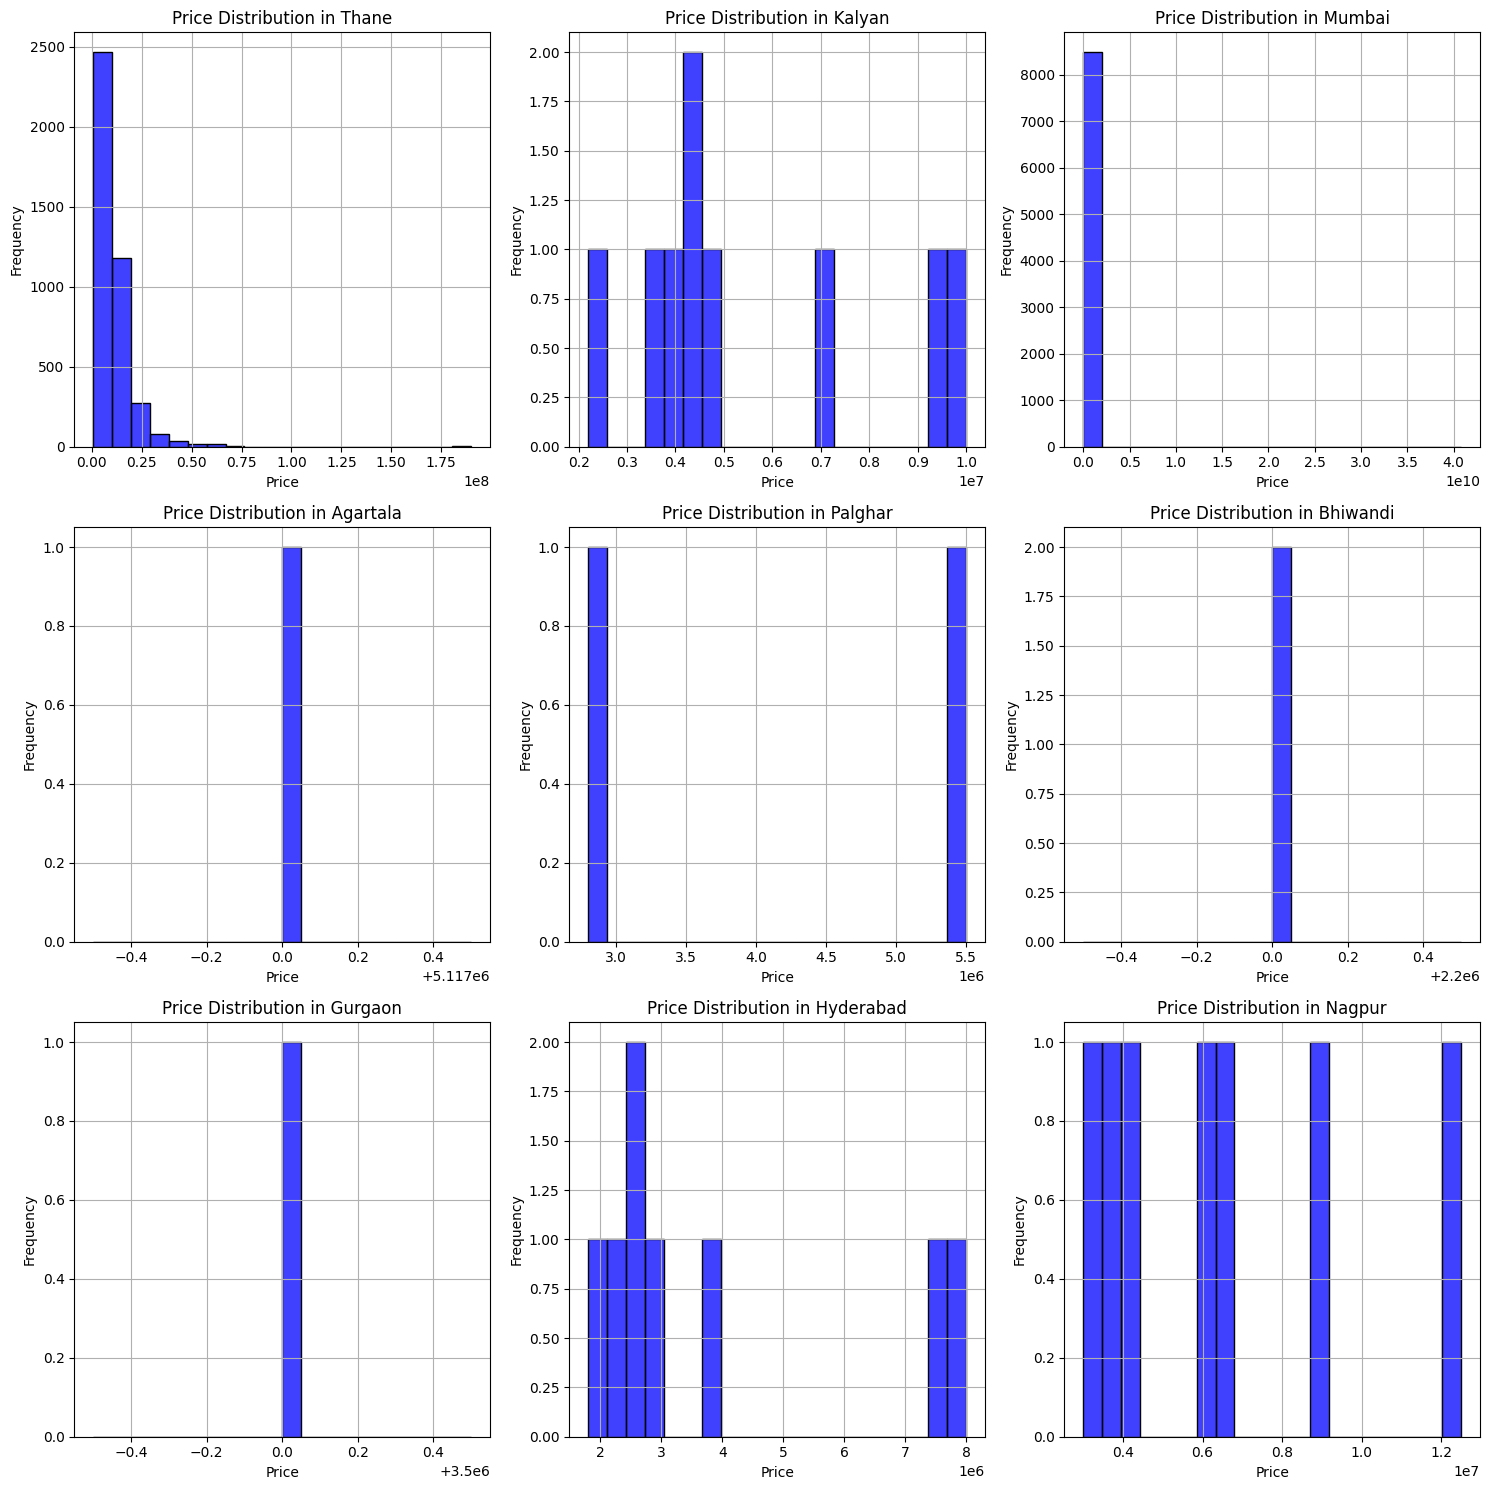

In [12]:

cities = df_1['City'].unique()

n_cities = len(cities)
n_cols = 3  
n_rows = int(np.ceil(n_cities / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows), tight_layout=True)

axes = axes.flatten()
for i, city in enumerate(cities):
    city_data = df_1[df_1['City'] == city]
    sns.histplot(city_data['Price'], bins=20, kde=False, color='blue', ax=axes[i])
    axes[i].set_title(f'Price Distribution in {city}')
    axes[i].set_xlabel('Price')
    axes[i].set_ylabel('Frequency')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

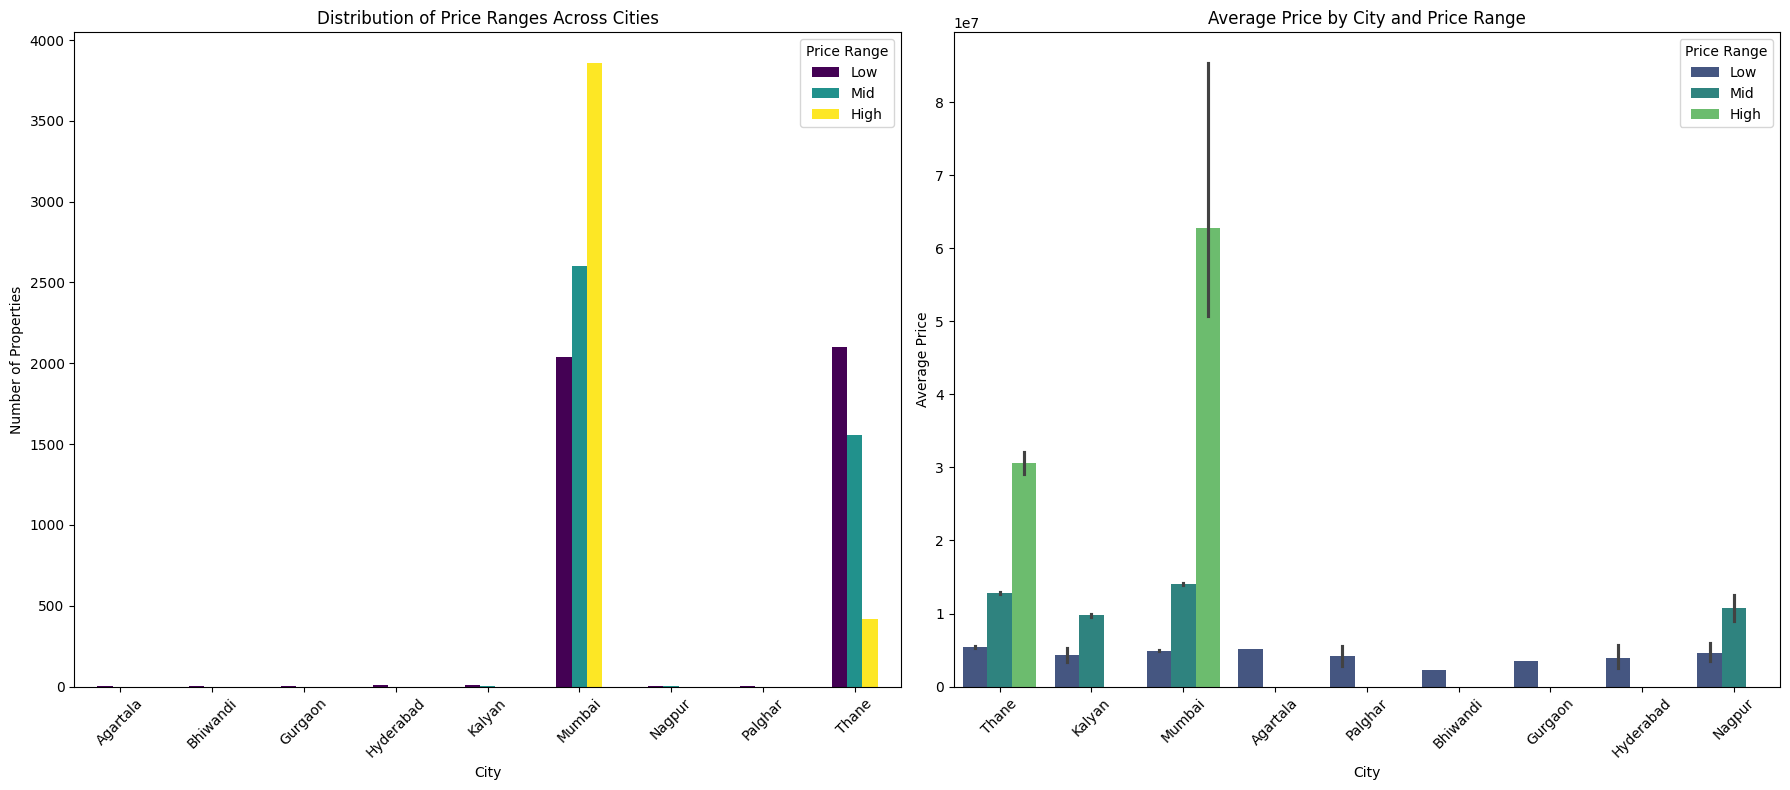

In [13]:
city_price_distribution = df_1.groupby(['City', 'Price Range'], observed=False).size().unstack()
pivot_table = city_price_distribution

fig, axs = plt.subplots(1, 2, figsize=(18, 8))

pivot_table.plot(kind='bar', colormap='viridis', ax=axs[0])
axs[0].set_title('Distribution of Price Ranges Across Cities')
axs[0].set_xlabel('City')
axs[0].set_ylabel('Number of Properties')
axs[0].legend(title='Price Range')
axs[0].tick_params(axis='x', rotation=45)

sns.barplot(x='City', y='Price', hue='Price Range', data=df_1, estimator='mean', palette='viridis', ax=axs[1])
axs[1].set_title('Average Price by City and Price Range')
axs[1].set_xlabel('City')
axs[1].set_ylabel('Average Price')
axs[1].legend(title='Price Range')
axs[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [14]:
missing_values = df[['Price', 'City', 'Type of Property']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['Price', 'City']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
Price               84
City                 0
Type of Property     0
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
253,12432,Ready to Move,NaN,2,Y,Madan Chikankar,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
405,12280,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
406,12279,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
794,11891,Under Construction,NaN,9,Y,Versatile Housing,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
795,11890,NaN,NaN,4,N,Lodha,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [15]:
df_2 = df[['Price', 'City', 'Type of Property','Amenities Facing']].copy()

df_2.loc[:, 'Amenities Facing'] = df_2['Amenities Facing'].fillna("Not Available")

count_not_available = (df_2['Amenities Facing'] == 'Not Available').sum()

print(f"Number of 'Not Available' entries: {count_not_available}")
nan_strategies = {
    'Price': {
        'strategy': 'remove'
    },
}

df_2, cleaning_details = clean_dataset(df_2, nan_strategies)

print(df_2.head())
print("Cleaning Details:")
print(cleaning_details)

Number of 'Not Available' entries: 4099
       Price   City Type of Property              Amenities Facing
0  3150000.0  Thane        Apartment             Garden/Park, Pool
1  6300000.0  Thane        Apartment                     Main Road
2  5400000.0  Thane        Apartment        Garden/Park, Main Road
3  9000000.0  Thane        Apartment  Pool, Garden/Park, Main Road
4  4950000.0  Thane        Apartment                   Garden/Park
Cleaning Details:
{'Price': {'strategy': 'remove'}}


In [16]:

outliers,df_cleaned_z = remove_outliers_z_score(df_2, 'Price',1)
print(outliers)
print("Number of rows of Z-score outliers:", len(df_2) - len(df_cleaned_z))
df_2 = df_cleaned_z

df_2.loc[:, 'Amenities Facing'] = df_2['Amenities Facing'].str.replace('Main Road, Not Available ', 'Main Road', regex=False)
 
df_2.loc[:, 'Amenities Facing'] = df_2['Amenities Facing'].apply(sort_amenities)

             Price    City Type of Property              Amenities Facing  \
2397  4.080000e+10  Mumbai        Apartment                   Garden/Park   
7165  4.100000e+08  Mumbai        Apartment                   Garden/Park   
7202  4.500000e+08  Mumbai        Apartment  Garden/Park, Pool, Main Road   
8858  2.800000e+09  Mumbai        Apartment                 Not Available   

         z_score  
2397  111.601369  
7165    1.049944  
7202    1.159428  
8858    7.591610  
Number of rows of Z-score outliers: 4


In [17]:
percentiles = df_2['Price'].quantile([0.33, 0.66])
min_price = df_2['Price'].min() -1
max_price = df_2['Price'].max()+1

price_labels = ['Low', 'Mid', 'High']

price_bins = [min_price, percentiles[0.33], percentiles[0.66], max_price]

df_2['Price Range'] = pd.cut(df_2['Price'], bins=price_bins, labels=price_labels)

def split_amenities(amenity_string):
    if pd.isna(amenity_string) or amenity_string == "Not Available":
        return []
    return [s.strip() for s in amenity_string.split(',')]

df_2['Amenities List'] = df_2['Amenities Facing'].apply(split_amenities)
df_amenities_expanded = df_2.explode('Amenities List')

In [18]:
price_range_summary = df_2.groupby('Price Range', observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
price_range_summary

,count,mean,min,max
Price Range,,,,
Low,4168,5.157855e+06,100000.0,8700000.0
Mid,4159,1.359214e+07,8750000.0,19800000.0
High,4270,4.922990e+07,19900000.0,380000000.0


In [19]:
property_type_summary = df_2.groupby(['Type of Property', 'Price Range'], observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
property_type_summary

count          mean         min  \
Type of Property        Price Range                                    
Apartment               Low           3881  5.245765e+06    100000.0   
                        Mid           4057  1.359754e+07   8750000.0   
                        High          4095  4.860034e+07  19900000.0   
Builder Floor Apartment Low            145  4.044138e+06   1100000.0   
                        Mid             38  1.277895e+07   9000000.0   
                        High            22  4.204545e+07  21000000.0   
Penthouse               Low              1  3.500000e+06   3500000.0   
                        Mid              2  1.310000e+07  13100000.0   
                        High            35  8.453143e+07  19900000.0   
Residential House       Low            126  3.754968e+06    350000.0   
                        Mid             53  1.329819e+07   8800000.0   
                        High            63  4.867937e+07  19900000.0   
Villa                   Low             15  5.073333e+06   1300000.0   
                        Mid              9  1.643333e+07  14400000.0   
                        High            55  7.714364e+07  20000000.0   

                                             max  
Type of Property        Price Range               
Apartment               Low            8700000.0  
                        Mid           19800000.0  
                        High         380000000.0  
Builder Floor Apartment Low            8500000.0  
                        Mid           19000000.0  
                        High         200000000.0  
Penthouse               Low            3500000.0  
                        Mid           13100000.0  
                        High         319000000.0  
Residential House       Low            8500000.0  
                        Mid           19500000.0  
                        High         370000000.0  
Villa                   Low            8000000.0  
                        Mid           18500000.0  
                        High         250000000.0

In [20]:
city_summary = df_2.groupby(['City', 'Price Range'], observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
city_summary

count          mean         min          max
City      Price Range                                              
Agartala  Low              1  5.117000e+06   5117000.0    5117000.0
          Mid              0           NaN         NaN          NaN
          High             0           NaN         NaN          NaN
Bhiwandi  Low              2  2.200000e+06   2200000.0    2200000.0
          Mid              0           NaN         NaN          NaN
          High             0           NaN         NaN          NaN
Gurgaon   Low              1  3.500000e+06   3500000.0    3500000.0
          Mid              0           NaN         NaN          NaN
          High             0           NaN         NaN          NaN
Hyderabad Low              8  3.968750e+06   1800000.0    8000000.0
          Mid              0           NaN         NaN          NaN
          High             0           NaN         NaN          NaN
Kalyan    Low              7  4.328571e+06   2200000.0    7000000.0
          Mid              2  9.750000e+06   9500000.0   10000000.0
          High             0           NaN         NaN          NaN
Mumbai    Low           2041  4.897038e+06    100000.0    8700000.0
          Mid           2599  1.406197e+07   8750000.0   19800000.0
          High          3851  5.126138e+07  19900000.0  380000000.0
Nagpur    Low              5  4.640000e+06   3000000.0    6500000.0
          Mid              2  1.075000e+07   9000000.0   12500000.0
          High             0           NaN         NaN          NaN
Palghar   Low              2  4.150000e+06   2800000.0    5500000.0
          Mid              0           NaN         NaN          NaN
          High             0           NaN         NaN          NaN
Thane     Low           2101  5.424330e+06    750000.0    8700000.0
          Mid           1556  1.281598e+07   8800000.0   19800000.0
          High           419  3.055870e+07  19900000.0  190000000.0

In [21]:
amenity_summary = df_amenities_expanded.groupby(['Amenities List', 'Price Range'], observed=False)['Price'].agg(['count', 'mean'])
amenity_summary

count          mean
Amenities List Price Range                     
Garden/Park    Low           1776  5.440997e+06
               Mid           1841  1.369435e+07
               High          2237  5.266665e+07
Main Road      Low           1773  5.316702e+06
               Mid           1978  1.382142e+07
               High          2493  4.849464e+07
Pool           Low            548  5.676385e+06
               Mid            677  1.394626e+07
               High          1072  5.609180e+07

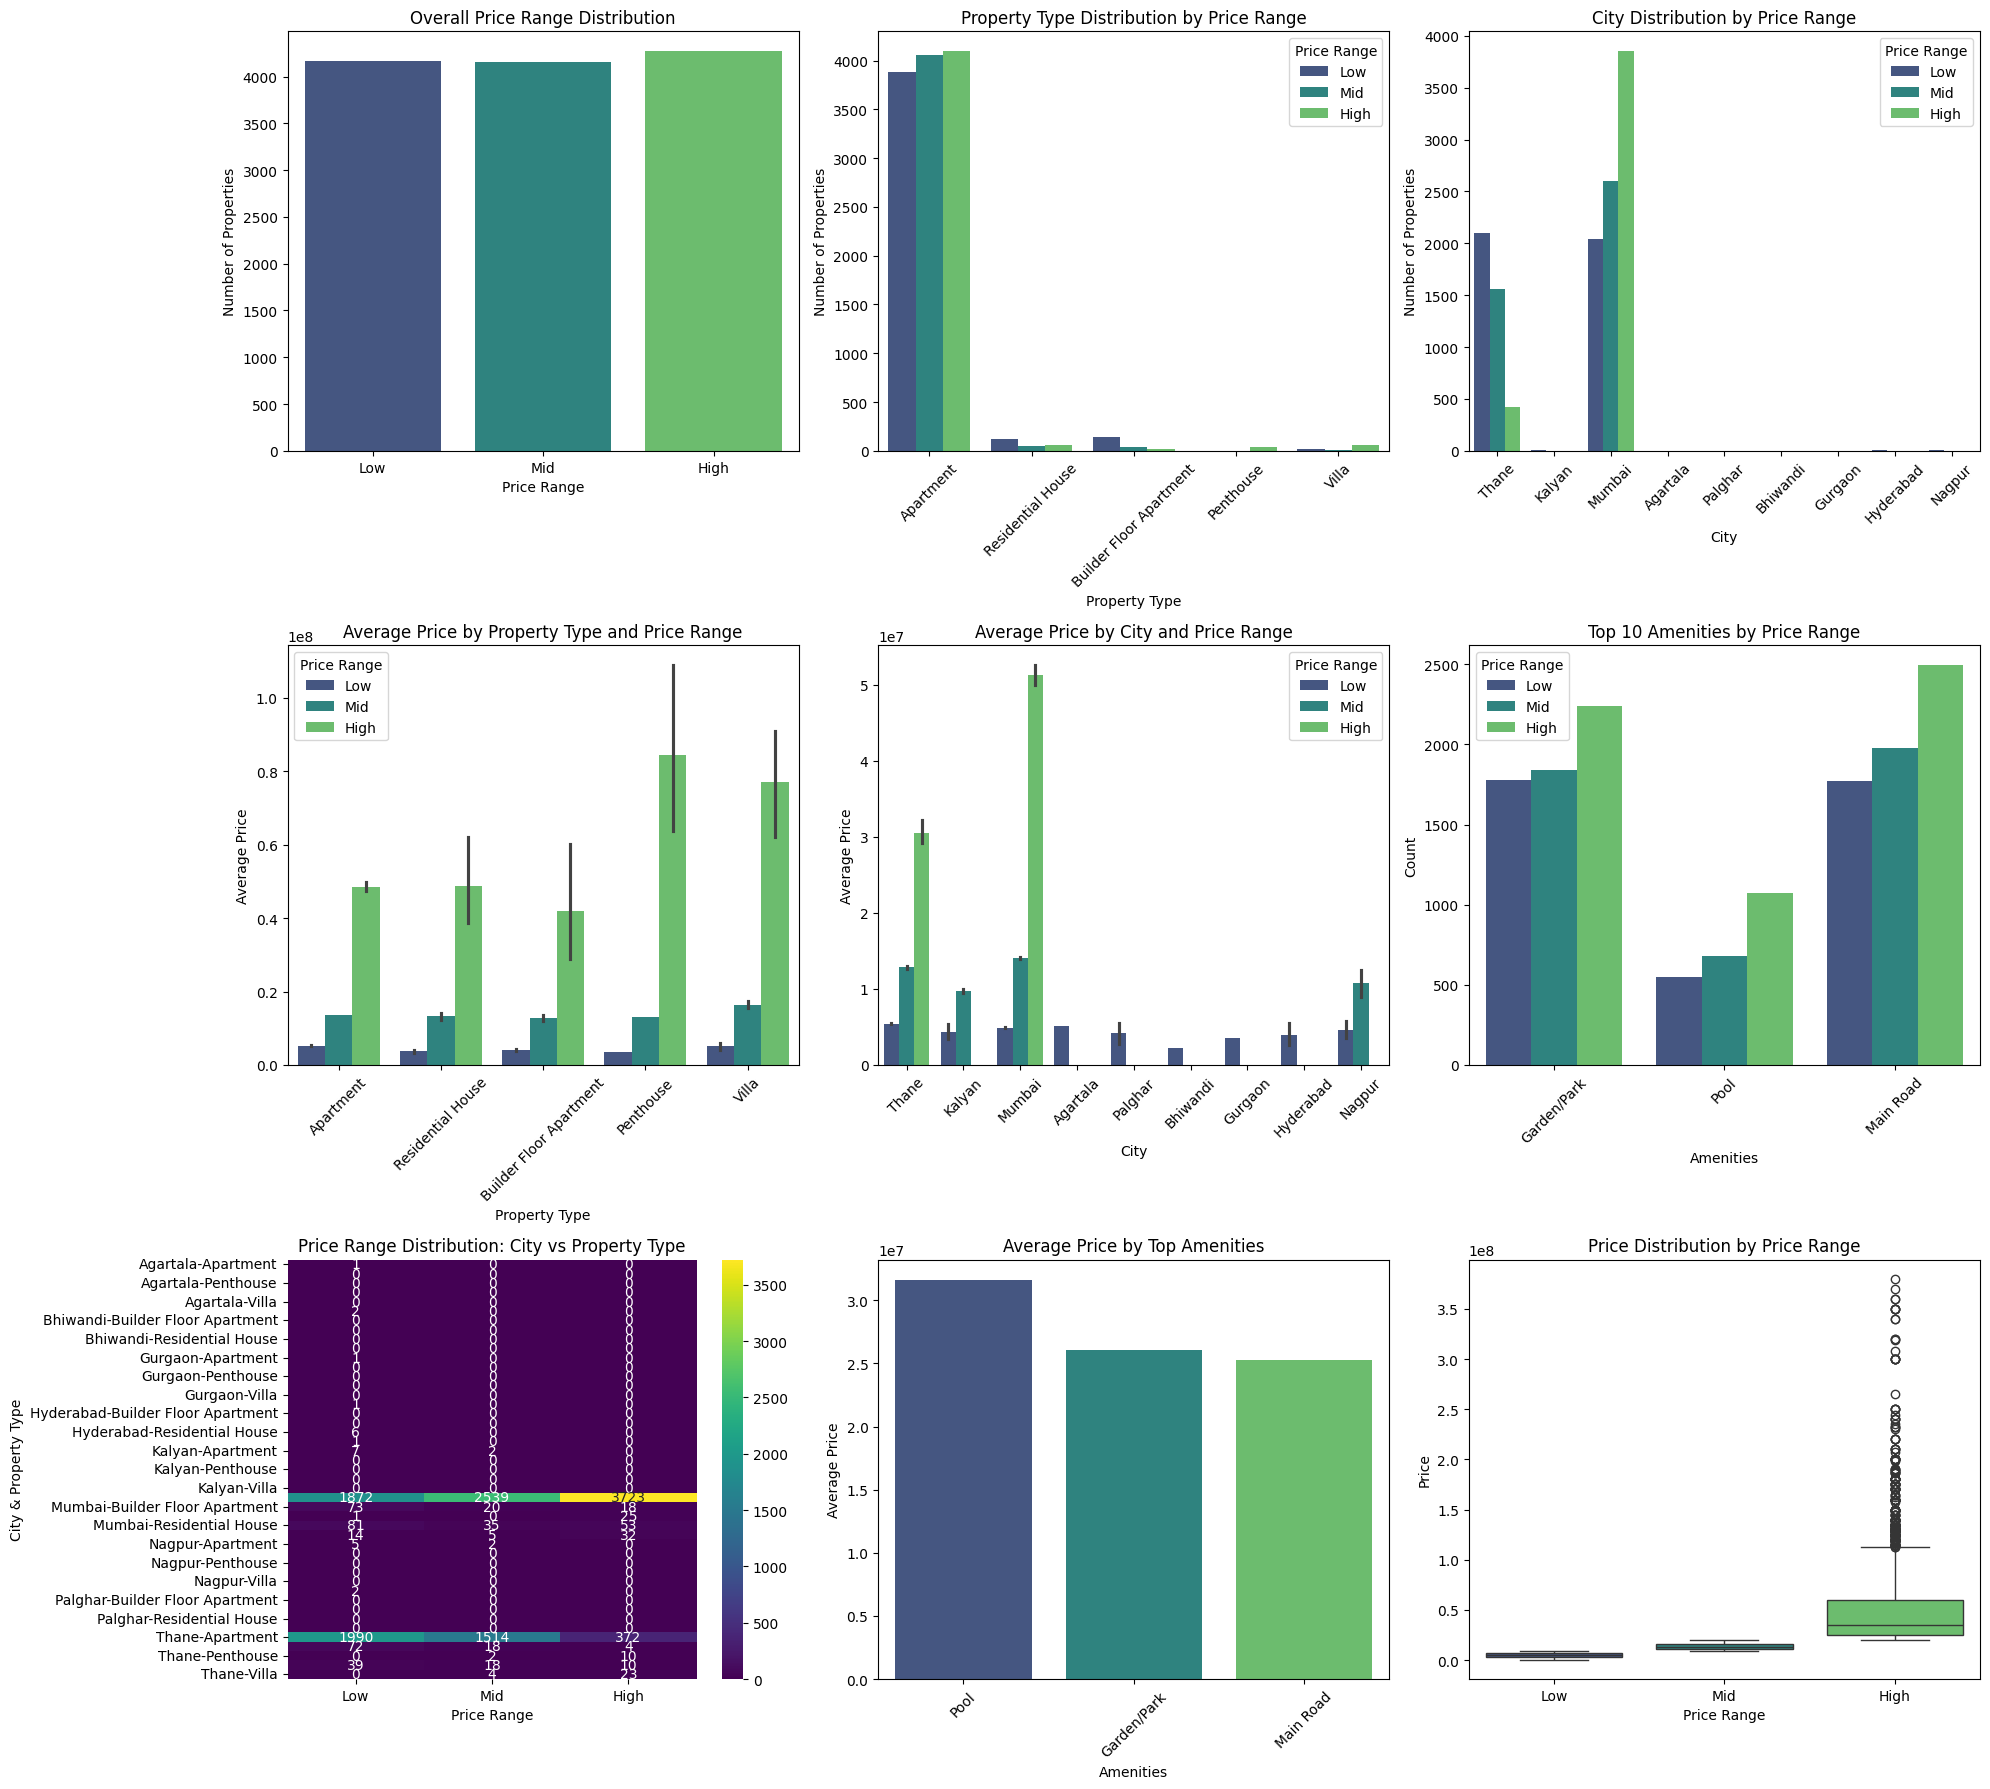

MARKET SUMMARY BY PRICE RANGE

LOW PRICE RANGE:
Price Range: ₹100,000 - ₹8,700,000
Average Price: ₹5,157,855
Total Properties: 4,168

Top Cities:
  • Thane: 2101 properties (50.4%)
  • Mumbai: 2041 properties (49.0%)
  • Hyderabad: 8 properties (0.2%)

Top Property Types:
  • Apartment: 3881 properties (93.1%)
  • Builder Floor Apartment: 145 properties (3.5%)
  • Residential House: 126 properties (3.0%)

Top Amenities:
  • Garden/Park: 1776 properties
  • Main Road: 1773 properties
  • Pool: 548 properties

MID PRICE RANGE:
Price Range: ₹8,750,000 - ₹19,800,000
Average Price: ₹13,592,145
Total Properties: 4,159

Top Cities:
  • Mumbai: 2599 properties (62.5%)
  • Thane: 1556 properties (37.4%)
  • Kalyan: 2 properties (0.0%)

Top Property Types:
  • Apartment: 4057 properties (97.5%)
  • Residential House: 53 properties (1.3%)
  • Builder Floor Apartment: 38 properties (0.9%)

Top Amenities:
  • Main Road: 1978 properties
  • Garden/Park: 1841 properties
  • Pool: 677 properties

HIGH

In [22]:
# Question 1: Comprehensive Visualizations - Price Segmentation & Market Overview
fig, axs = plt.subplots(3, 3, figsize=(20, 18))  
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Price Range Distribution
sns.countplot(x='Price Range', data=df_2, hue='Price Range', palette='viridis', legend=False, ax=axs[0, 0])
axs[0, 0].set_title('Overall Price Range Distribution')
axs[0, 0].set_xlabel('Price Range')
axs[0, 0].set_ylabel('Number of Properties')

# 2. Price Range by Property Type
sns.countplot(x='Type of Property', hue='Price Range', data=df_2, palette='viridis', ax=axs[0, 1])
axs[0, 1].set_title('Property Type Distribution by Price Range')
axs[0, 1].set_xlabel('Property Type')
axs[0, 1].set_ylabel('Number of Properties')
axs[0, 1].legend(title='Price Range')
axs[0, 1].tick_params(axis='x', rotation=45)

# 3. Price Range by City
sns.countplot(x='City', hue='Price Range', data=df_2, palette='viridis', ax=axs[0, 2])
axs[0, 2].set_title('City Distribution by Price Range')
axs[0, 2].set_xlabel('City')
axs[0, 2].set_ylabel('Number of Properties')
axs[0, 2].legend(title='Price Range')
axs[0, 2].tick_params(axis='x', rotation=45)

# 4. Average Price by Property Type and Price Range
sns.barplot(x='Type of Property', y='Price', hue='Price Range', data=df_2, estimator='mean', palette='viridis', ax=axs[1, 0])
axs[1, 0].set_title('Average Price by Property Type and Price Range')
axs[1, 0].set_xlabel('Property Type')
axs[1, 0].set_ylabel('Average Price')
axs[1, 0].legend(title='Price Range')
axs[1, 0].tick_params(axis='x', rotation=45)

# 5. Average Price by City and Price Range
sns.barplot(x='City', y='Price', hue='Price Range', data=df_2, estimator='mean', palette='viridis', ax=axs[1, 1])
axs[1, 1].set_title('Average Price by City and Price Range')
axs[1, 1].set_xlabel('City')
axs[1, 1].set_ylabel('Average Price')
axs[1, 1].legend(title='Price Range')
axs[1, 1].tick_params(axis='x', rotation=45)

            # 6. Top Amenities by Price Range
top_amenities = df_amenities_expanded['Amenities List'].value_counts().head(10).index
df_top_amenities = df_amenities_expanded[df_amenities_expanded['Amenities List'].isin(top_amenities)]
sns.countplot(x='Amenities List', hue='Price Range', data=df_top_amenities, palette='viridis', ax=axs[1, 2])
axs[1, 2].set_title('Top 10 Amenities by Price Range')
axs[1, 2].set_xlabel('Amenities')
axs[1, 2].set_ylabel('Count')
axs[1, 2].legend(title='Price Range')
axs[1, 2].tick_params(axis='x', rotation=45)

# 7. Price Range Heatmap by City and Property Type
price_heatmap = df_2.groupby(['City', 'Type of Property', 'Price Range'], observed=False).size().unstack(fill_value=0)
sns.heatmap(price_heatmap, annot=True, fmt='d', cmap='viridis', ax=axs[2, 0])
axs[2, 0].set_title('Price Range Distribution: City vs Property Type')
axs[2, 0].set_xlabel('Price Range')
axs[2, 0].set_ylabel('City & Property Type')

# 8. Average Price by Top Amenities
average_price_by_amenity = df_top_amenities.groupby('Amenities List')['Price'].mean().sort_values(ascending=False)
sns.barplot(x=average_price_by_amenity.index, y=average_price_by_amenity.values, hue=average_price_by_amenity.index, palette='viridis', legend=False, ax=axs[2, 1])
axs[2, 1].set_title('Average Price by Top Amenities')
axs[2, 1].set_xlabel('Amenities')
axs[2, 1].set_ylabel('Average Price')
axs[2, 1].tick_params(axis='x', rotation=45)

# 9. Price Distribution Box Plot
sns.boxplot(x='Price Range', y='Price', data=df_2, hue='Price Range', palette='viridis', legend=False, ax=axs[2, 2])
axs[2, 2].set_title('Price Distribution by Price Range')
axs[2, 2].set_xlabel('Price Range')
axs[2, 2].set_ylabel('Price')

plt.tight_layout()
plt.show()

# Print Market Summary
print("MARKET SUMMARY BY PRICE RANGE")

for price_range in ['Low', 'Mid', 'High']:
    subset = df_2[df_2['Price Range'] == price_range]
    print(f"\n{price_range.upper()} PRICE RANGE:")
    print(f"Price Range: ₹{subset['Price'].min():,.0f} - ₹{subset['Price'].max():,.0f}")
    print(f"Average Price: ₹{subset['Price'].mean():,.0f}")
    print(f"Total Properties: {len(subset):,}")
    
    print(f"\nTop Cities:")
    city_counts = subset['City'].value_counts().head(3)
    for city, count in city_counts.items():
        print(f"  • {city}: {count} properties ({count/len(subset)*100:.1f}%)")
    
    print(f"\nTop Property Types:")
    prop_counts = subset['Type of Property'].value_counts().head(3)
    for prop_type, count in prop_counts.items():
        print(f"  • {prop_type}: {count} properties ({count/len(subset)*100:.1f}%)")
    
    print(f"\nTop Amenities:")
    amenity_subset = df_amenities_expanded[df_amenities_expanded['Price Range'] == price_range]
    amenity_counts = amenity_subset['Amenities List'].value_counts().head(3)
    for amenity, count in amenity_counts.items():
        print(f"  • {amenity}: {count} properties")

In [23]:
# In this question, we would need price, city, property type and Carpet Area
# Thane and Mumbai
df_3 = df[df['City'].isin(['Thane', 'Mumbai'])]
missing_values = df_3[['Price', 'City', 'Type of Property','Carpet Area']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df_3[df_3[['Price', 'City','Type of Property','Carpet Area']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
Price                 84
City                   0
Type of Property       0
Carpet Area         2535
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
12,12673,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
37,12648,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
55,12630,Ready to Move,NaN,3,N,NaN,NaN,NaN,2400000.0,24 Lac,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
56,12629,Ready to Move,NaN,3,N,NaN,NaN,NaN,2000000.0,20 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
57,12628,Ready to Move,NaN,NaN,N,NaN,NaN,NaN,2500000.0,25 Lac,...,0,0,0,0,0,NaN,NaN,300.0,12850.0,NaN


In [24]:
df_3 = df_3[['Price', 'City', 'Type of Property','Carpet Area']]

# From the data it is observed that the columns that are not having the price values are most probably junk data with no values for the rest of the components 
# hence, we are removing those columns as they might not be suitable for analysis.
# carpet area is dependant on the property type so we are considering the mean value by property type

nan_strategies = {
    'Price': {
        'strategy': 'remove',
    },
    'Carpet Area': {
        'strategy': 'mean',  
        'group_by': 'Type of Property' 
    },
}

df_3, cleaning_details = clean_dataset(df_3, nan_strategies)
print(df_3.head())
print("Cleaning Details:")
print(cleaning_details)

       Price   City Type of Property  Carpet Area
0  3150000.0  Thane        Apartment        375.0
1  6300000.0  Thane        Apartment        579.0
2  5400000.0  Thane        Apartment        585.0
3  9000000.0  Thane        Apartment        815.0
4  4950000.0  Thane        Apartment        419.0
Cleaning Details:
{'Price': {'strategy': 'remove'}, 'Carpet Area': {'strategy': 'mean', 'group_by': 'Type of Property', 'mean_values_by_group': {'Apartment': 809.4083930399181, 'Builder Floor Apartment': 598.955223880597, 'Penthouse': 2112.5142857142855, 'Residential House': 773.75, 'Villa': 1982.203125}}}


In [25]:
target_column = 'Price'
feature_columns = ['Carpet Area']
df_cleaned = remove_outliers_with_regression(df_3, target_column, feature_columns)
df_3 = df_cleaned

target_column = 'Carpet Area'
feature_columns = ['Price']
df_cleaned = remove_outliers_with_regression(df_3, target_column, feature_columns)
df_3 = df_cleaned

Initial number of rows: 12571
Number of rows after outlier removal: 12569
Number of rows removed: 2
Initial number of rows: 12569
Number of rows after outlier removal: 12436
Number of rows removed: 133


# City-Level Comparative Analysis (Mumbai vs Thane)


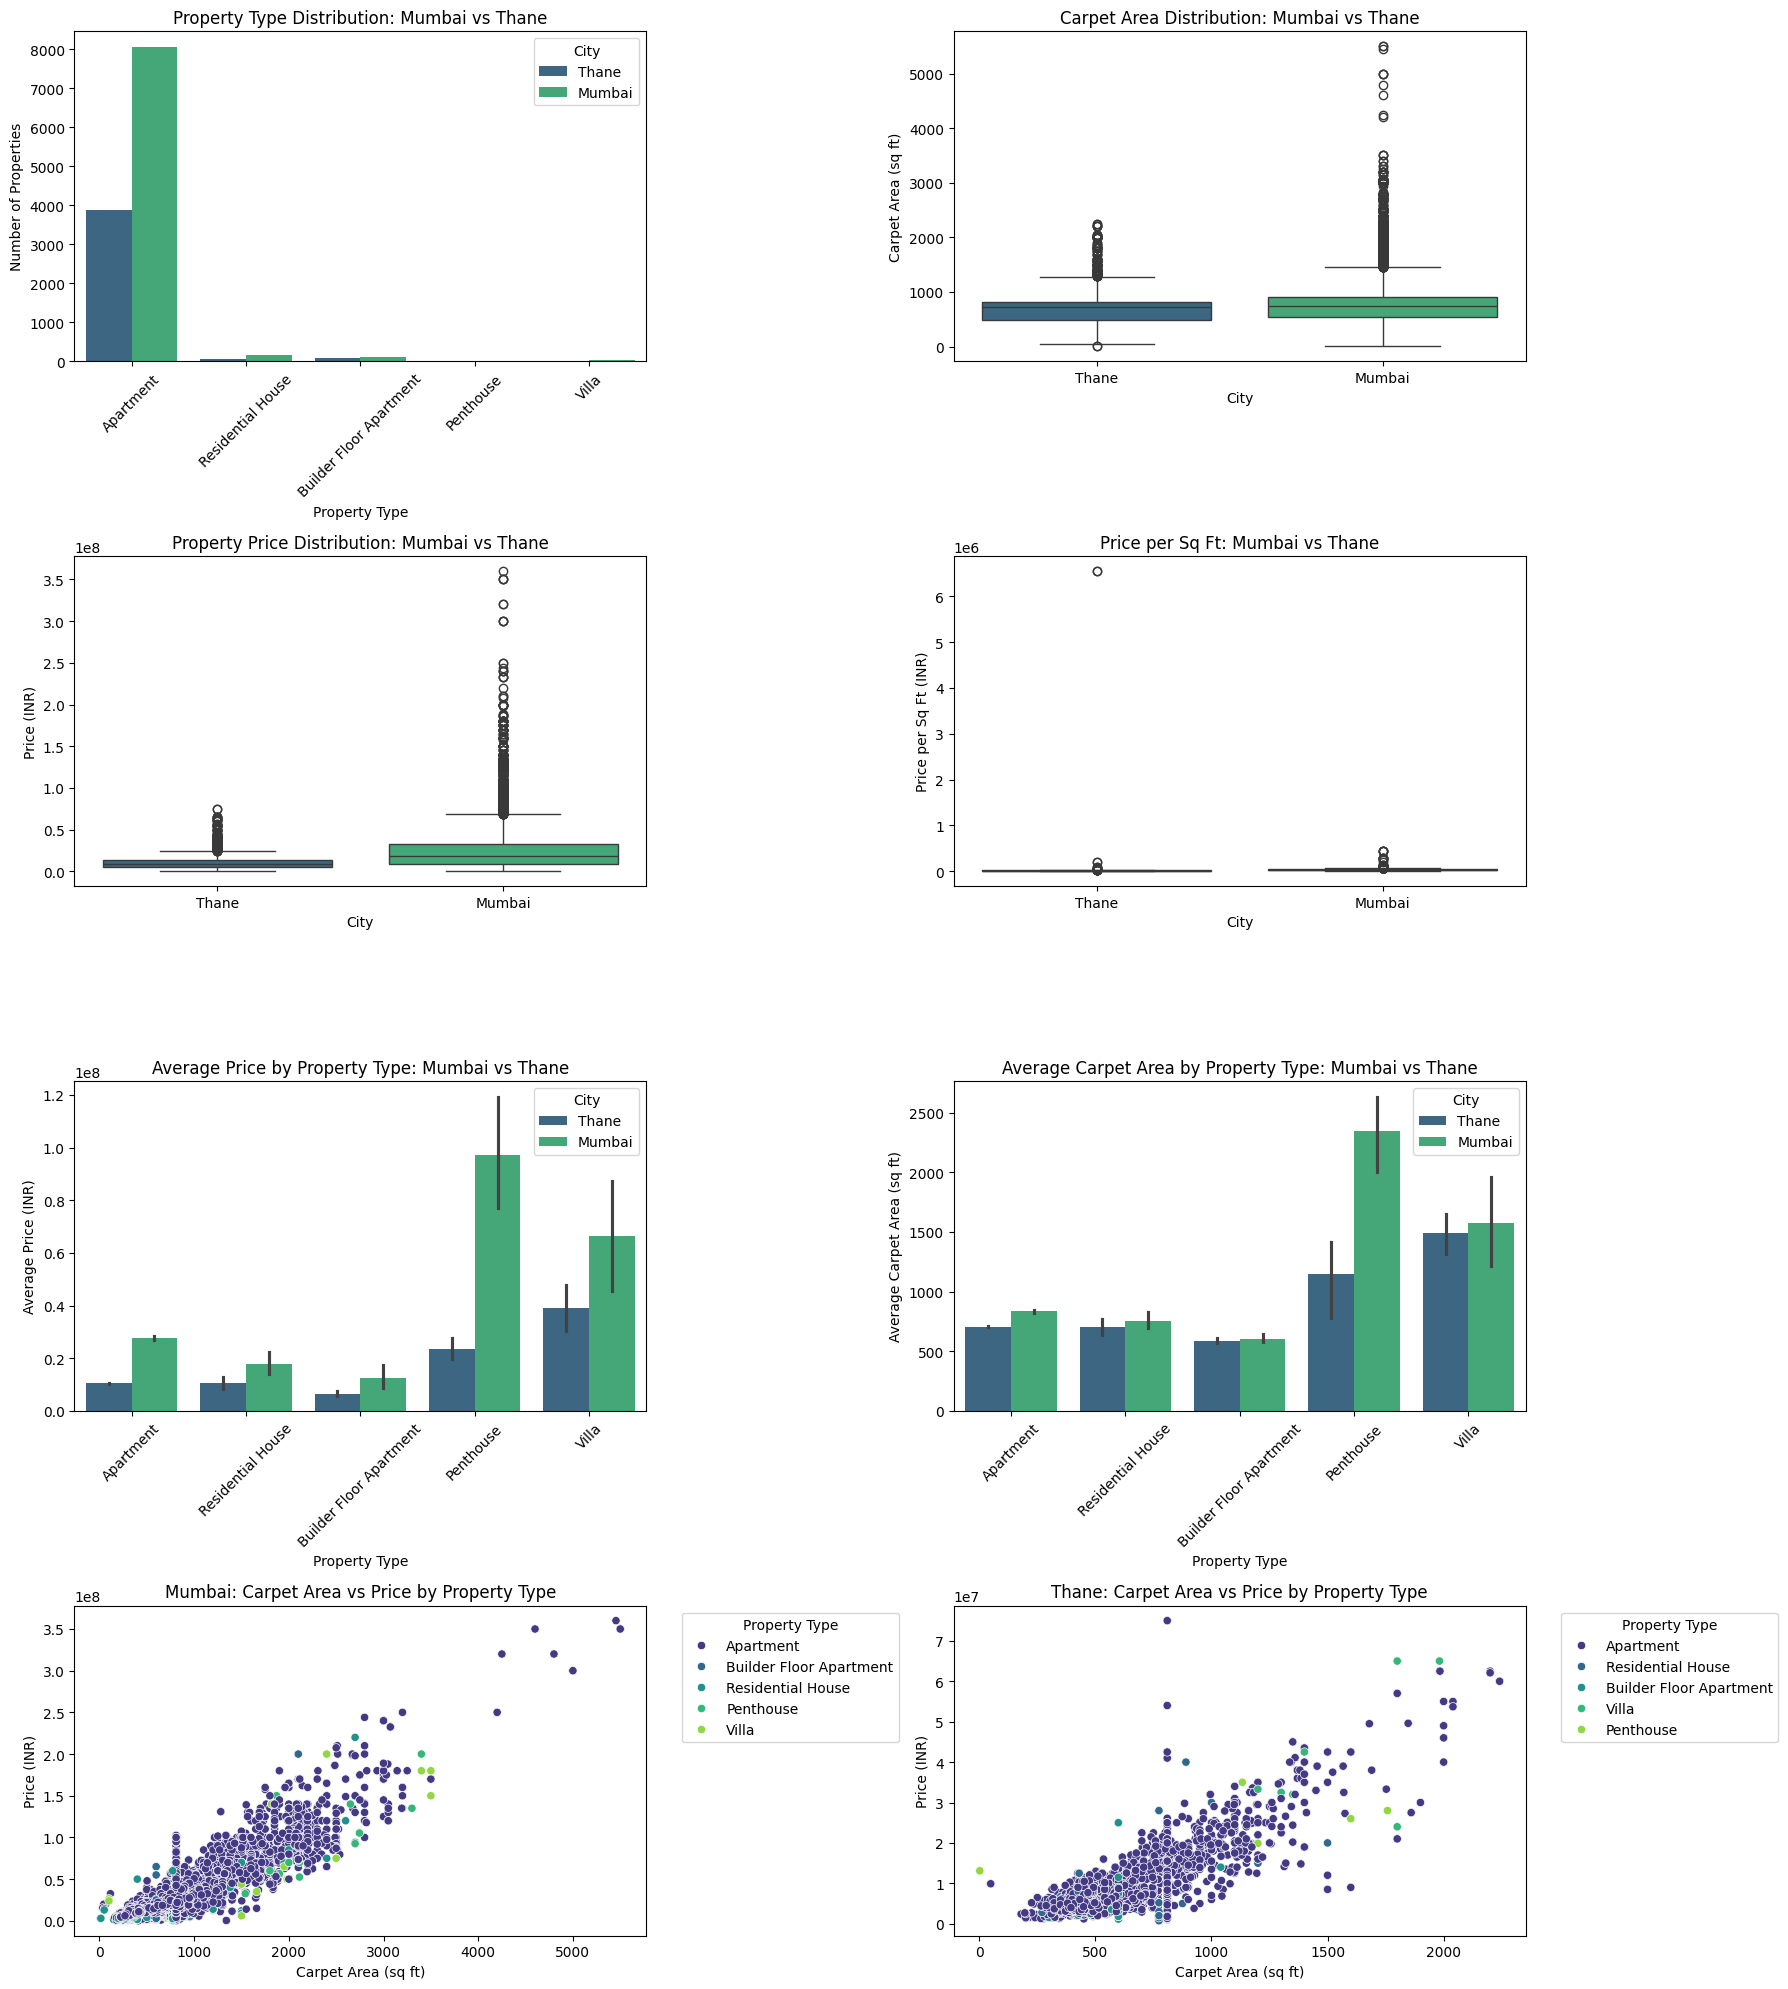

MUMBAI vs THANE: RESIDENTIAL & COMMERCIAL SEGMENT ANALYSIS

RESIDENTIAL SEGMENT COMPARISON:

MUMBAI Residential Properties:
  • Total Properties: 8,379
  • Average Price: ₹27,503,613
  • Average Carpet Area: 835 sq ft
  • Average Price/sq ft: ₹28838
  • Top Property Type: Apartment

THANE Residential Properties:
  • Total Properties: 4,057
  • Average Price: ₹10,607,956
  • Average Carpet Area: 709 sq ft
  • Average Price/sq ft: ₹17682
  • Top Property Type: Apartment

INVESTMENT INSIGHTS:
• Mumbai is 63.1% more expensive per sq ft than Thane
• Mumbai average carpet area: 835 sq ft
• Thane average carpet area: 709 sq ft
• For budget-conscious investors: Thane offers better value
• For premium investments: Mumbai offers higher appreciation potential


In [26]:
# Question 2: Comprehensive Mumbai vs Thane Comparative Analysis
fig, axs = plt.subplots(4, 2, figsize=(18, 20))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Property Type Distribution Comparison
sns.countplot(x='Type of Property', hue='City', data=df_3, palette='viridis', ax=axs[0, 0])
axs[0, 0].set_title('Property Type Distribution: Mumbai vs Thane')
axs[0, 0].set_xlabel('Property Type')
axs[0, 0].set_ylabel('Number of Properties')
axs[0, 0].legend(title='City')
axs[0, 0].tick_params(axis='x', rotation=45)

# 2. Carpet Area Comparison
sns.boxplot(x='City', y='Carpet Area', data=df_3, hue='City', palette='viridis', legend=False, ax=axs[0, 1])
axs[0, 1].set_title('Carpet Area Distribution: Mumbai vs Thane')
axs[0, 1].set_xlabel('City')
axs[0, 1].set_ylabel('Carpet Area (sq ft)')

# 3. Price Comparison
sns.boxplot(x='City', y='Price', data=df_3, hue='City', palette='viridis', legend=False, ax=axs[1, 0])
axs[1, 0].set_title('Property Price Distribution: Mumbai vs Thane')
axs[1, 0].set_xlabel('City')
axs[1, 0].set_ylabel('Price (INR)')

# 4. Price per Square Foot Comparison
df_3['Price per Sq Ft'] = df_3['Price'] / df_3['Carpet Area']
sns.boxplot(x='City', y='Price per Sq Ft', data=df_3, hue='City', palette='viridis', legend=False, ax=axs[1, 1])
axs[1, 1].set_title('Price per Sq Ft: Mumbai vs Thane')
axs[1, 1].set_xlabel('City')
axs[1, 1].set_ylabel('Price per Sq Ft (INR)')

# 5. Property Type Average Prices by City
sns.barplot(x='Type of Property', y='Price', hue='City', data=df_3, estimator='mean', palette='viridis', ax=axs[2, 0])
axs[2, 0].set_title('Average Price by Property Type: Mumbai vs Thane')
axs[2, 0].set_xlabel('Property Type')
axs[2, 0].set_ylabel('Average Price (INR)')
axs[2, 0].legend(title='City')
axs[2, 0].tick_params(axis='x', rotation=45)

# 6. Average Carpet Area by Property Type
sns.barplot(x='Type of Property', y='Carpet Area', hue='City', data=df_3, estimator='mean', palette='viridis', ax=axs[2, 1])
axs[2, 1].set_title('Average Carpet Area by Property Type: Mumbai vs Thane')
axs[2, 1].set_xlabel('Property Type')
axs[2, 1].set_ylabel('Average Carpet Area (sq ft)')
axs[2, 1].legend(title='City')
axs[2, 1].tick_params(axis='x', rotation=45)

# 7. Scatter Plot: Carpet Area vs Price for Mumbai
mumbai_data = df_3[df_3['City'] == 'Mumbai']
sns.scatterplot(x='Carpet Area', y='Price', hue='Type of Property', data=mumbai_data, palette='viridis', ax=axs[3, 0])
axs[3, 0].set_title('Mumbai: Carpet Area vs Price by Property Type')
axs[3, 0].set_xlabel('Carpet Area (sq ft)')
axs[3, 0].set_ylabel('Price (INR)')
axs[3, 0].legend(title='Property Type', bbox_to_anchor=(1.05, 1), loc='upper left')

# 8. Scatter Plot: Carpet Area vs Price for Thane
thane_data = df_3[df_3['City'] == 'Thane']
sns.scatterplot(x='Carpet Area', y='Price', hue='Type of Property', data=thane_data, palette='viridis', ax=axs[3, 1])
axs[3, 1].set_title('Thane: Carpet Area vs Price by Property Type')
axs[3, 1].set_xlabel('Carpet Area (sq ft)')
axs[3, 1].set_ylabel('Price (INR)')
axs[3, 1].legend(title='Property Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Residential vs Commercial Analysis
print("MUMBAI vs THANE: RESIDENTIAL & COMMERCIAL SEGMENT ANALYSIS")

# Define residential and commercial property types
residential_types = ['Residential House', 'Villa', 'Apartment', 'Builder Floor Apartment', 'Penthouse']
commercial_types = ['Office Space', 'Shop', 'Showroom', 'Commercial Land', 'Warehouse']

# Filter data for residential properties
residential_data = df_3[df_3['Type of Property'].isin(residential_types)]
# For commercial, we'll use all non-residential types or create a simple filter
commercial_data = df_3[~df_3['Type of Property'].isin(residential_types)]

print("\nRESIDENTIAL SEGMENT COMPARISON:")
for city in ['Mumbai', 'Thane']:
    city_residential = residential_data[residential_data['City'] == city]
    if len(city_residential) > 0:
        print(f"\n{city.upper()} Residential Properties:")
        print(f"  • Total Properties: {len(city_residential):,}")
        print(f"  • Average Price: ₹{city_residential['Price'].mean():,.0f}")
        print(f"  • Average Carpet Area: {city_residential['Carpet Area'].mean():.0f} sq ft")
        print(f"  • Average Price/sq ft: ₹{city_residential['Price per Sq Ft'].mean():.0f}")
        print(f"  • Top Property Type: {city_residential['Type of Property'].mode().iloc[0]}")

if len(commercial_data) > 0:
    print(f"\nCOMMERCIAL SEGMENT COMPARISON:")
    print("-" * 50)
    for city in ['Mumbai', 'Thane']:
        city_commercial = commercial_data[commercial_data['City'] == city]
        if len(city_commercial) > 0:
            print(f"\n{city.upper()} Commercial Properties:")
            print(f"  • Total Properties: {len(city_commercial):,}")
            print(f"  • Average Price: ₹{city_commercial['Price'].mean():,.0f}")
            print(f"  • Average Carpet Area: {city_commercial['Carpet Area'].mean():.0f} sq ft")
            print(f"  • Average Price/sq ft: ₹{city_commercial['Price per Sq Ft'].mean():.0f}")

print(f"\nINVESTMENT INSIGHTS:")
mumbai_avg_price_psf = mumbai_data['Price per Sq Ft'].mean()
thane_avg_price_psf = thane_data['Price per Sq Ft'].mean()
price_diff = ((mumbai_avg_price_psf - thane_avg_price_psf) / thane_avg_price_psf) * 100

print(f"• Mumbai is {price_diff:.1f}% more expensive per sq ft than Thane")
print(f"• Mumbai average carpet area: {mumbai_data['Carpet Area'].mean():.0f} sq ft")
print(f"• Thane average carpet area: {thane_data['Carpet Area'].mean():.0f} sq ft")
print(f"• For budget-conscious investors: Thane offers better value")
print(f"• For premium investments: Mumbai offers higher appreciation potential")

In [27]:
# In this question, we would need price, city, property type, location type and Carpet Area
missing_values = df[['City', 'isPrimeLocationProperty','Carpet Area','Price','Type of Property']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['Price', 'City']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
City                          0
isPrimeLocationProperty       0
Carpet Area                2552
Price                        84
Type of Property              0
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
253,12432,Ready to Move,NaN,2,Y,Madan Chikankar,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
405,12280,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
406,12279,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
794,11891,Under Construction,NaN,9,Y,Versatile Housing,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
795,11890,NaN,NaN,4,N,Lodha,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [28]:
df_4 = df[['City', 'isPrimeLocationProperty','Type of Property','Carpet Area','Price']]

nan_strategies = {
    'Price': {
         'strategy': 'remove',  
    },
    'Carpet Area': {
        'strategy': 'mean',
        'group_by': 'Type of Property'
    },
}

df_4, cleaning_details = clean_dataset(df_4, nan_strategies)
print(df_4.head())
print("Cleaning Details:")
print(cleaning_details)

    City isPrimeLocationProperty Type of Property  Carpet Area      Price
0  Thane                       Y        Apartment        375.0  3150000.0
1  Thane                       Y        Apartment        579.0  6300000.0
2  Thane                       Y        Apartment        585.0  5400000.0
3  Thane                       Y        Apartment        815.0  9000000.0
4  Thane                       Y        Apartment        419.0  4950000.0
Cleaning Details:
{'Price': {'strategy': 'remove'}, 'Carpet Area': {'strategy': 'mean', 'group_by': 'Type of Property', 'mean_values_by_group': {'Apartment': 809.491717791411, 'Builder Floor Apartment': 598.955223880597, 'Penthouse': 2112.5142857142855, 'Residential House': 770.8441558441558, 'Villa': 1954.4923076923078}}}


In [29]:
target_column = 'Price'
feature_columns = ['Carpet Area']
df_cleaned = remove_outliers_with_regression(df_4, target_column, feature_columns)
df_4 = df_cleaned

target_column = 'Carpet Area'
feature_columns = ['Price']
df_cleaned = remove_outliers_with_regression(df_4, target_column, feature_columns)
df_4 = df_cleaned

Initial number of rows: 12601
Number of rows after outlier removal: 12599
Number of rows removed: 2
Initial number of rows: 12599
Number of rows after outlier removal: 12465
Number of rows removed: 134


In [30]:

percentiles = df_4['Price'].quantile([0.33, 0.66])
min_price = df_4['Price'].min() -1
max_price = df_4['Price'].max()+1

price_labels = ['Low', 'Mid', 'High']

# The boundaries are: (min, 33rd percentile], (33rd percentile, 66th percentile], (66th percentile, max)
price_bins = [min_price, percentiles[0.33], percentiles[0.66], max_price]

price_labels = ['Low', 'Mid', 'High']

df_4['Price Range'] = pd.cut(df_4['Price'], bins=price_bins, labels=price_labels)

price_range_summary = df_4.groupby('Price Range',observed=False)['Price'].agg(['count', 'mean', 'min', 'max'])
price_range_summary

,count,mean,min,max
Price Range,,,,
Low,4133,5.134851e+06,125000.0,8600000.0
Mid,4140,1.350184e+07,8600001.0,19500000.0
High,4192,4.687688e+07,19600000.0,360000000.0


In [31]:
prime_location_distribution = df_4.groupby(['City', 'isPrimeLocationProperty', 'Price Range'], observed=False).size().unstack(fill_value=0)
prime_location_distribution

Price Range                         Low   Mid  High
City      isPrimeLocationProperty                  
Agartala  N                           0     0     0
          Y                           1     0     0
Bhiwandi  N                           2     0     0
          Y                           0     0     0
Gurgaon   N                           0     0     0
          Y                           1     0     0
Hyderabad N                           0     0     0
          Y                           8     0     0
Kalyan    N                           2     2     0
          Y                           5     0     0
Mumbai    N                         620   592   404
          Y                        1398  1989  3376
Nagpur    N                           3     1     0
          Y                           2     0     0
Palghar   N                           1     0     0
          Y                           1     0     0
Thane     N                         877   585    95
          Y                        1212   971   317

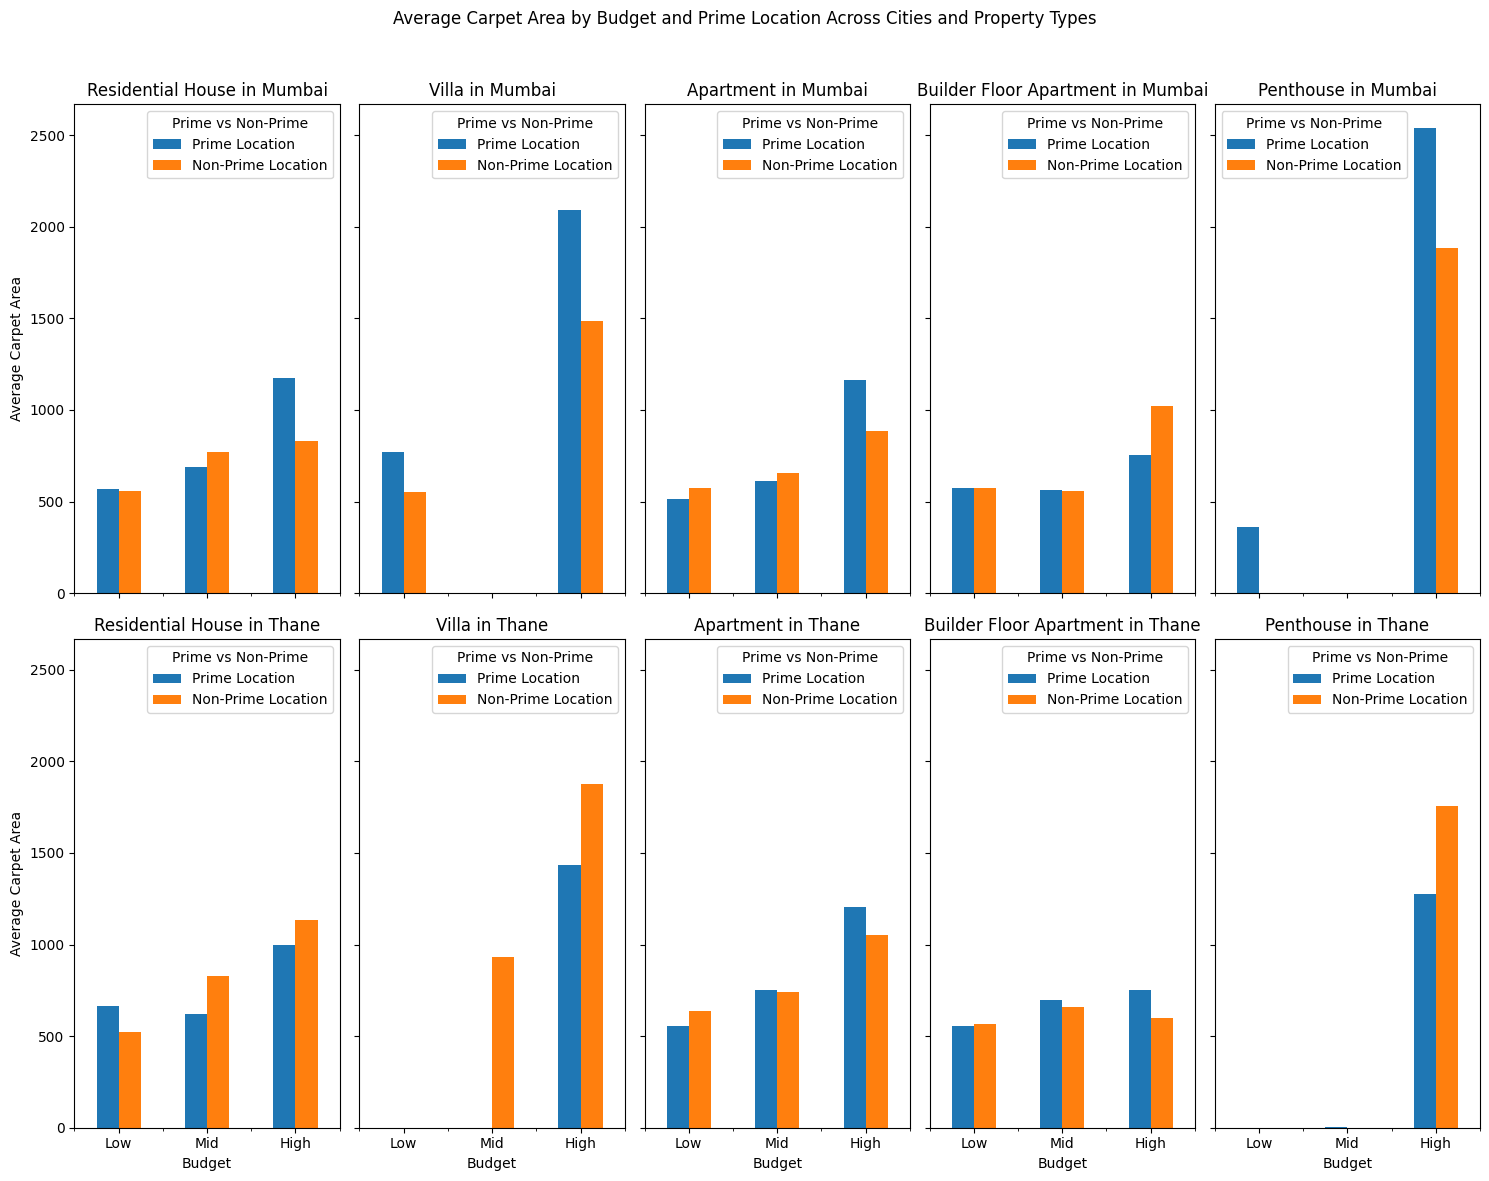

In [32]:

def plot_prime_comparison(df, budget_labels, property_types):
    """Optimized function using vectorized operations for better performance"""
    if df.empty:
        print("DataFrame is empty.")
        return
    
    cities = ["Mumbai","Thane"]
    
    num_columns = len(property_types)
    num_cities = len(cities)
    
    num_rows = num_cities
    
    fig, axes = plt.subplots(nrows=num_rows, ncols=num_columns, figsize=(15, 6 * num_rows), sharex=True, sharey=True)
    
    if num_rows == 1:
        axes = np.array([axes])
    
    axes = axes.flatten()
    
    property_type_to_index = {ptype: idx for idx, ptype in enumerate(property_types)}

    grouped_data = df.groupby(['City', 'Type of Property', 'Price Range', 'isPrimeLocationProperty'], observed=False)['Carpet Area'].mean().unstack(fill_value=0)

    for city_idx, city in enumerate(cities):
        for property_type in property_types:
            ax = axes[city_idx * num_columns + property_type_to_index[property_type]]
            
            try:
                plot_data_list = []
                for budget_label in budget_labels:
                    try:
                        y_data = grouped_data.loc[(city, property_type, budget_label), ['Y', 'N']].fillna(0)
                        plot_data_list.append([budget_label, y_data['Y'], y_data['N']])
                    except KeyError:
                        plot_data_list.append([budget_label, 0, 0])
                
                plot_df = pd.DataFrame(plot_data_list, columns=['Budget', 'Y', 'N']).set_index('Budget')
                
                if not plot_df.empty and plot_df.sum().sum() > 0:
                    plot_df.plot(kind='bar', ax=ax, color=['#1f77b4', '#ff7f0e'])
                    ax.legend(title='Prime vs Non-Prime', labels=['Prime Location', 'Non-Prime Location'])
                else:
                    ax.text(0.5, 0.5, 'No Data', horizontalalignment='center', verticalalignment='center')
                    
            except Exception as e:
                ax.text(0.5, 0.5, 'No Data', horizontalalignment='center', verticalalignment='center')
            
            ax.set_title(f'{property_type} in {city}')
            ax.set_ylabel('Average Carpet Area')
            ax.set_xlabel('Budget')
            ax.tick_params(axis='x', rotation=0)
    
    plt.suptitle('Average Carpet Area by Budget and Prime Location Across Cities and Property Types')
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

property_types = ['Residential House', 'Villa', 'Apartment', 'Builder Floor Apartment', 'Penthouse']
plot_prime_comparison(df_4, ['Low', 'Mid', 'High'], property_types)


# Location-Based Premium Analysis


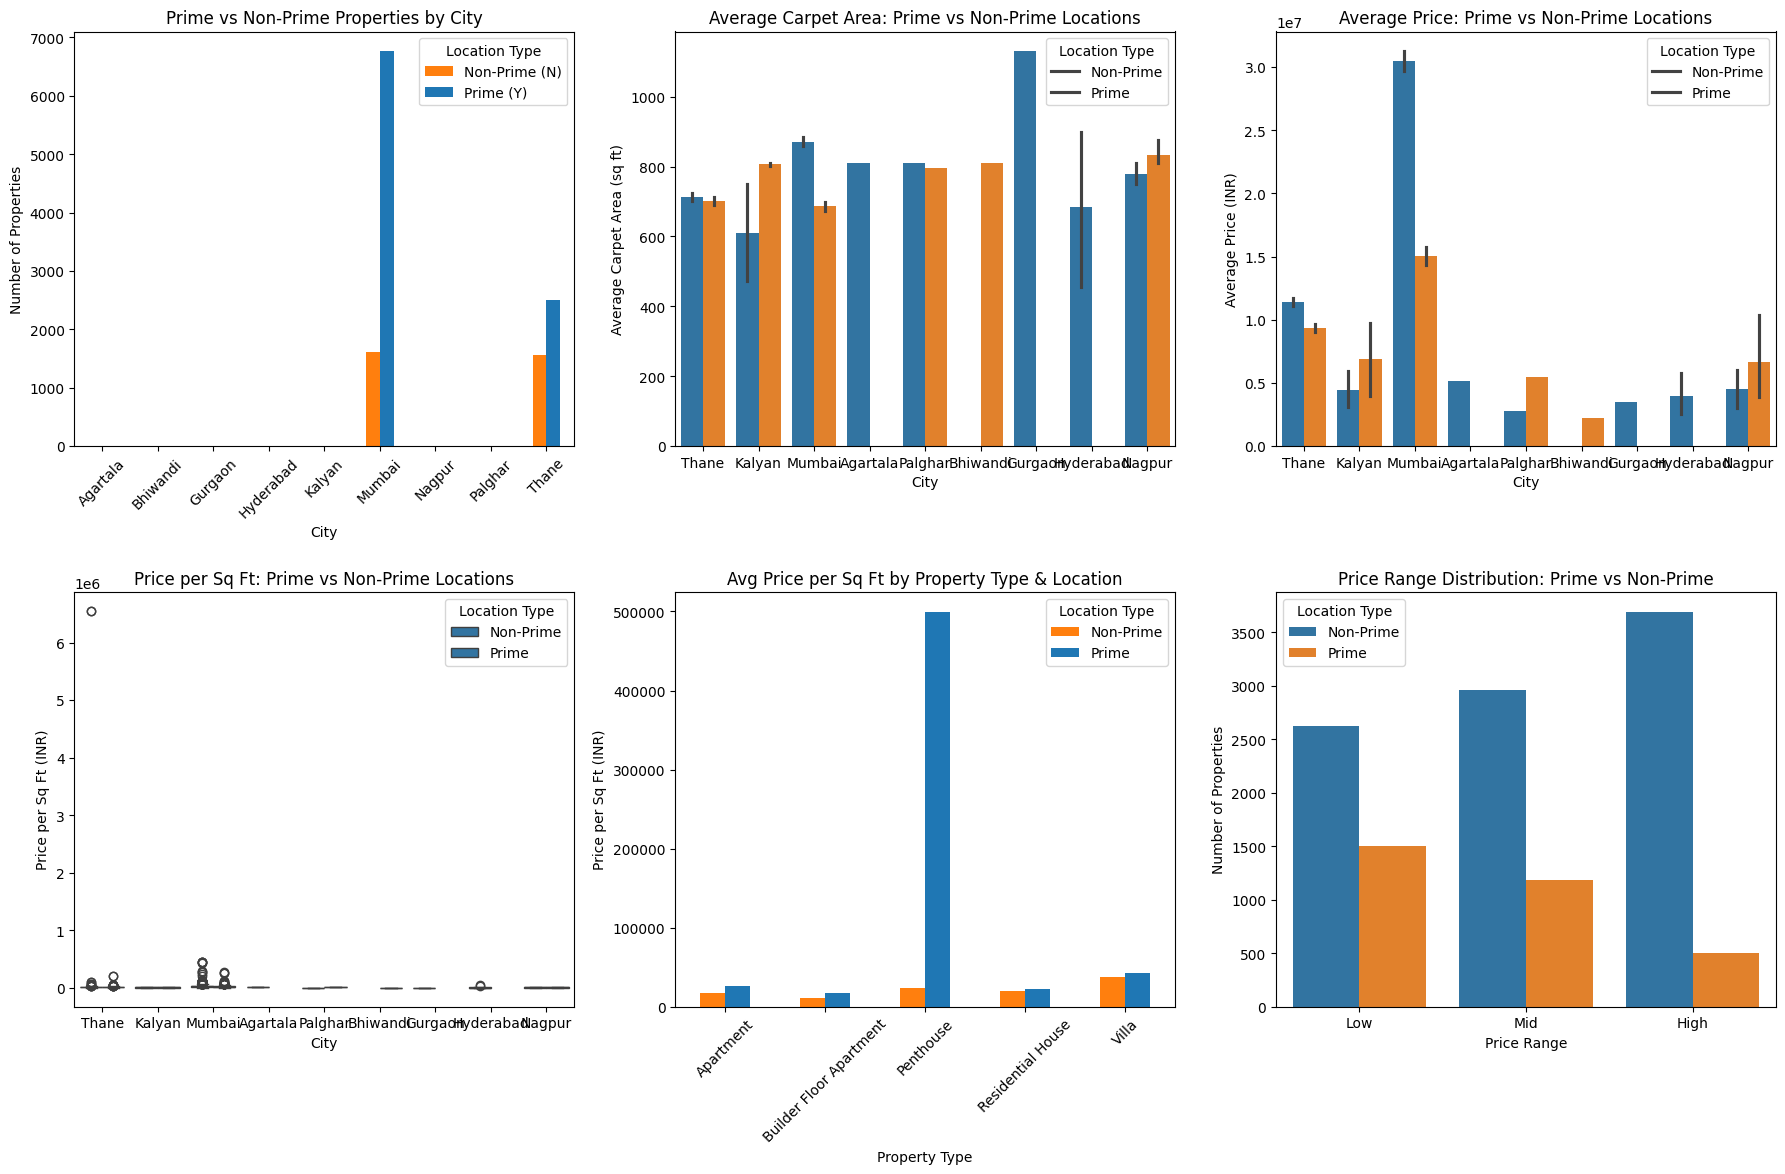

LOCATION-BASED PREMIUM ANALYSIS

THANE - PREMIUM ANALYSIS:
Prime Location Properties:
  • Count: 2,500
  • Avg Price: ₹11,398,418
  • Avg Carpet Area: 713 sq ft
  • Avg Price/sq ft: ₹20293

Non-Prime Location Properties:
  • Count: 1,557
  • Avg Price: ₹9,338,751
  • Avg Carpet Area: 702 sq ft
  • Avg Price/sq ft: ₹13491

PREMIUM ANALYSIS:
  • Price Premium: +22.1%
  • Area Difference: +1.5%
  • Price/Sq Ft Premium: +50.4%
  • Location Premium Justified: Questionable (>30%)

KALYAN - PREMIUM ANALYSIS:
Prime Location Properties:
  • Count: 5
  • Avg Price: ₹4,470,000
  • Avg Carpet Area: 611 sq ft
  • Avg Price/sq ft: ₹7491

Non-Prime Location Properties:
  • Count: 4
  • Avg Price: ₹6,862,500
  • Avg Carpet Area: 807 sq ft
  • Avg Price/sq ft: ₹8491

PREMIUM ANALYSIS:
  • Price Premium: -34.9%
  • Area Difference: -24.3%
  • Price/Sq Ft Premium: -11.8%
  • Location Premium: No premium detected

MUMBAI - PREMIUM ANALYSIS:
Prime Location Properties:
  • Count: 6,763
  • Avg Price: ₹30,48

In [33]:
# Question 3: Location-Based Premium Analysis Visualizations
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Calculate price per sq ft for analysis
df_4['Price per Sq Ft'] = df_4['Price'] / df_4['Carpet Area']

# 1. Prime vs Non-Prime Distribution by City
prime_dist = df_4.groupby(['City', 'isPrimeLocationProperty']).size().unstack(fill_value=0)
prime_dist.plot(kind='bar', ax=axes[0, 0], color=['#ff7f0e', '#1f77b4'])
axes[0, 0].set_title('Prime vs Non-Prime Properties by City')
axes[0, 0].set_xlabel('City')
axes[0, 0].set_ylabel('Number of Properties')
axes[0, 0].legend(['Non-Prime (N)', 'Prime (Y)'], title='Location Type')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Average Carpet Area: Prime vs Non-Prime
sns.barplot(x='City', y='Carpet Area', hue='isPrimeLocationProperty', data=df_4, ax=axes[0, 1])
axes[0, 1].set_title('Average Carpet Area: Prime vs Non-Prime Locations')
axes[0, 1].set_xlabel('City')
axes[0, 1].set_ylabel('Average Carpet Area (sq ft)')
axes[0, 1].legend(['Non-Prime', 'Prime'], title='Location Type')

# 3. Average Price: Prime vs Non-Prime
sns.barplot(x='City', y='Price', hue='isPrimeLocationProperty', data=df_4, ax=axes[0, 2])
axes[0, 2].set_title('Average Price: Prime vs Non-Prime Locations')
axes[0, 2].set_xlabel('City')
axes[0, 2].set_ylabel('Average Price (INR)')
axes[0, 2].legend(['Non-Prime', 'Prime'], title='Location Type')

# 4. Price per Sq Ft Comparison
sns.boxplot(x='City', y='Price per Sq Ft', hue='isPrimeLocationProperty', data=df_4, ax=axes[1, 0])
axes[1, 0].set_title('Price per Sq Ft: Prime vs Non-Prime Locations')
axes[1, 0].set_xlabel('City')
axes[1, 0].set_ylabel('Price per Sq Ft (INR)')
axes[1, 0].legend(['Non-Prime', 'Prime'], title='Location Type')

# 5. Premium Analysis by Property Type
premium_by_type = df_4.groupby(['Type of Property', 'isPrimeLocationProperty'])['Price per Sq Ft'].mean().unstack(fill_value=0)
premium_by_type.plot(kind='bar', ax=axes[1, 1], color=['#ff7f0e', '#1f77b4'])
axes[1, 1].set_title('Avg Price per Sq Ft by Property Type & Location')
axes[1, 1].set_xlabel('Property Type')
axes[1, 1].set_ylabel('Price per Sq Ft (INR)')
axes[1, 1].legend(['Non-Prime', 'Prime'], title='Location Type')
axes[1, 1].tick_params(axis='x', rotation=45)

# 6. Price Range Distribution: Prime vs Non-Prime
sns.countplot(x='Price Range', hue='isPrimeLocationProperty', data=df_4, ax=axes[1, 2])
axes[1, 2].set_title('Price Range Distribution: Prime vs Non-Prime')
axes[1, 2].set_xlabel('Price Range')
axes[1, 2].set_ylabel('Number of Properties')
axes[1, 2].legend(['Non-Prime', 'Prime'], title='Location Type')

plt.tight_layout()
plt.show()

# Detailed Premium Analysis
print("LOCATION-BASED PREMIUM ANALYSIS")

for city in df_4['City'].unique():
    city_data = df_4[df_4['City'] == city]
    
    prime_data = city_data[city_data['isPrimeLocationProperty'] == 'Y']
    non_prime_data = city_data[city_data['isPrimeLocationProperty'] == 'N']
    
    if len(prime_data) > 0 and len(non_prime_data) > 0:
        print(f"\n{city.upper()} - PREMIUM ANALYSIS:")
        
        # Average metrics
        prime_avg_price = prime_data['Price'].mean()
        non_prime_avg_price = non_prime_data['Price'].mean()
        price_premium = ((prime_avg_price - non_prime_avg_price) / non_prime_avg_price) * 100
        
        prime_avg_area = prime_data['Carpet Area'].mean()
        non_prime_avg_area = non_prime_data['Carpet Area'].mean()
        area_difference = ((prime_avg_area - non_prime_avg_area) / non_prime_avg_area) * 100
        
        prime_avg_psf = prime_data['Price per Sq Ft'].mean()
        non_prime_avg_psf = non_prime_data['Price per Sq Ft'].mean()
        psf_premium = ((prime_avg_psf - non_prime_avg_psf) / non_prime_avg_psf) * 100
        
        print(f"Prime Location Properties:")
        print(f"  • Count: {len(prime_data):,}")
        print(f"  • Avg Price: ₹{prime_avg_price:,.0f}")
        print(f"  • Avg Carpet Area: {prime_avg_area:.0f} sq ft")
        print(f"  • Avg Price/sq ft: ₹{prime_avg_psf:.0f}")
        
        print(f"\nNon-Prime Location Properties:")
        print(f"  • Count: {len(non_prime_data):,}")
        print(f"  • Avg Price: ₹{non_prime_avg_price:,.0f}")
        print(f"  • Avg Carpet Area: {non_prime_avg_area:.0f} sq ft")
        print(f"  • Avg Price/sq ft: ₹{non_prime_avg_psf:.0f}")
        
        print(f"\nPREMIUM ANALYSIS:")
        print(f"  • Price Premium: {price_premium:+.1f}%")
        print(f"  • Area Difference: {area_difference:+.1f}%")
        print(f"  • Price/Sq Ft Premium: {psf_premium:+.1f}%")
        
        # Value justification analysis
        if psf_premium > 0:
            print(f"  • Location Premium Justified: {'Yes' if psf_premium <= 30 else 'Questionable (>30%)'}")
        else:
            print(f"  • Location Premium: No premium detected")

print(f"\nKEY INSIGHTS:")
print(f"• Prime locations command significant premiums in most cities")
print(f"• Premium is primarily driven by price per sq ft rather than larger areas")
print(f"• Investors should evaluate if location premium aligns with rental/appreciation potential")
print(f"• Non-prime locations may offer better value for budget-conscious investors")

In [34]:
# In this question, we would need price, city, property type and Carpet Area
missing_values = df[['City','Carpet Area','Type of Property','Price']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['City','Carpet Area','Type of Property','Price']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
City                   0
Carpet Area         2552
Type of Property       0
Price                 84
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
12,12673,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
37,12648,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
55,12630,Ready to Move,NaN,3,N,NaN,NaN,NaN,2400000.0,24 Lac,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
56,12629,Ready to Move,NaN,3,N,NaN,NaN,NaN,2000000.0,20 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
57,12628,Ready to Move,NaN,NaN,N,NaN,NaN,NaN,2500000.0,25 Lac,...,0,0,0,0,0,NaN,NaN,300.0,12850.0,NaN


In [35]:
df_5 = df[['Price', 'City', 'Type of Property','Carpet Area']]

# From the data it is observed that the columns that are not having the price values are most probably junk data with no values for the rest of the components 
# hence, we are removing those columns as they might not be suitable for analysis.
# carpet area is dependant on the property type so we are considering the mean value by property type

nan_strategies = {
    'Price': {
        'strategy': 'remove',
    },
    'Carpet Area': {
        'strategy': 'mean',  
        'group_by': 'Type of Property' 
    },
}

df_5, cleaning_details = clean_dataset(df_5, nan_strategies)
print(df_5.head())
print("Cleaning Details:")
print(cleaning_details)

df_5['Area per Unit Price'] = df_5['Carpet Area'] / (df_5['Price'])

df_5_filtered = df_5[df_5['Area per Unit Price'].notnull() & (df_5['Area per Unit Price'] > 0)]

       Price   City Type of Property  Carpet Area
0  3150000.0  Thane        Apartment        375.0
1  6300000.0  Thane        Apartment        579.0
2  5400000.0  Thane        Apartment        585.0
3  9000000.0  Thane        Apartment        815.0
4  4950000.0  Thane        Apartment        419.0
Cleaning Details:
{'Price': {'strategy': 'remove'}, 'Carpet Area': {'strategy': 'mean', 'group_by': 'Type of Property', 'mean_values_by_group': {'Apartment': 809.491717791411, 'Builder Floor Apartment': 598.955223880597, 'Penthouse': 2112.5142857142855, 'Residential House': 770.8441558441558, 'Villa': 1954.4923076923078}}}


In [36]:
target_column = 'Price'
feature_columns = ['Carpet Area']
df_cleaned = remove_outliers_with_regression(df_5, target_column, feature_columns)
df_5 = df_cleaned

target_column = 'Carpet Area'
feature_columns = ['Price']
df_cleaned = remove_outliers_with_regression(df_5, target_column, feature_columns)
df_5 = df_cleaned

Initial number of rows: 12601
Number of rows after outlier removal: 12599
Number of rows removed: 2
Initial number of rows: 12599
Number of rows after outlier removal: 12465
Number of rows removed: 134


# Value-for-Money Opportunities


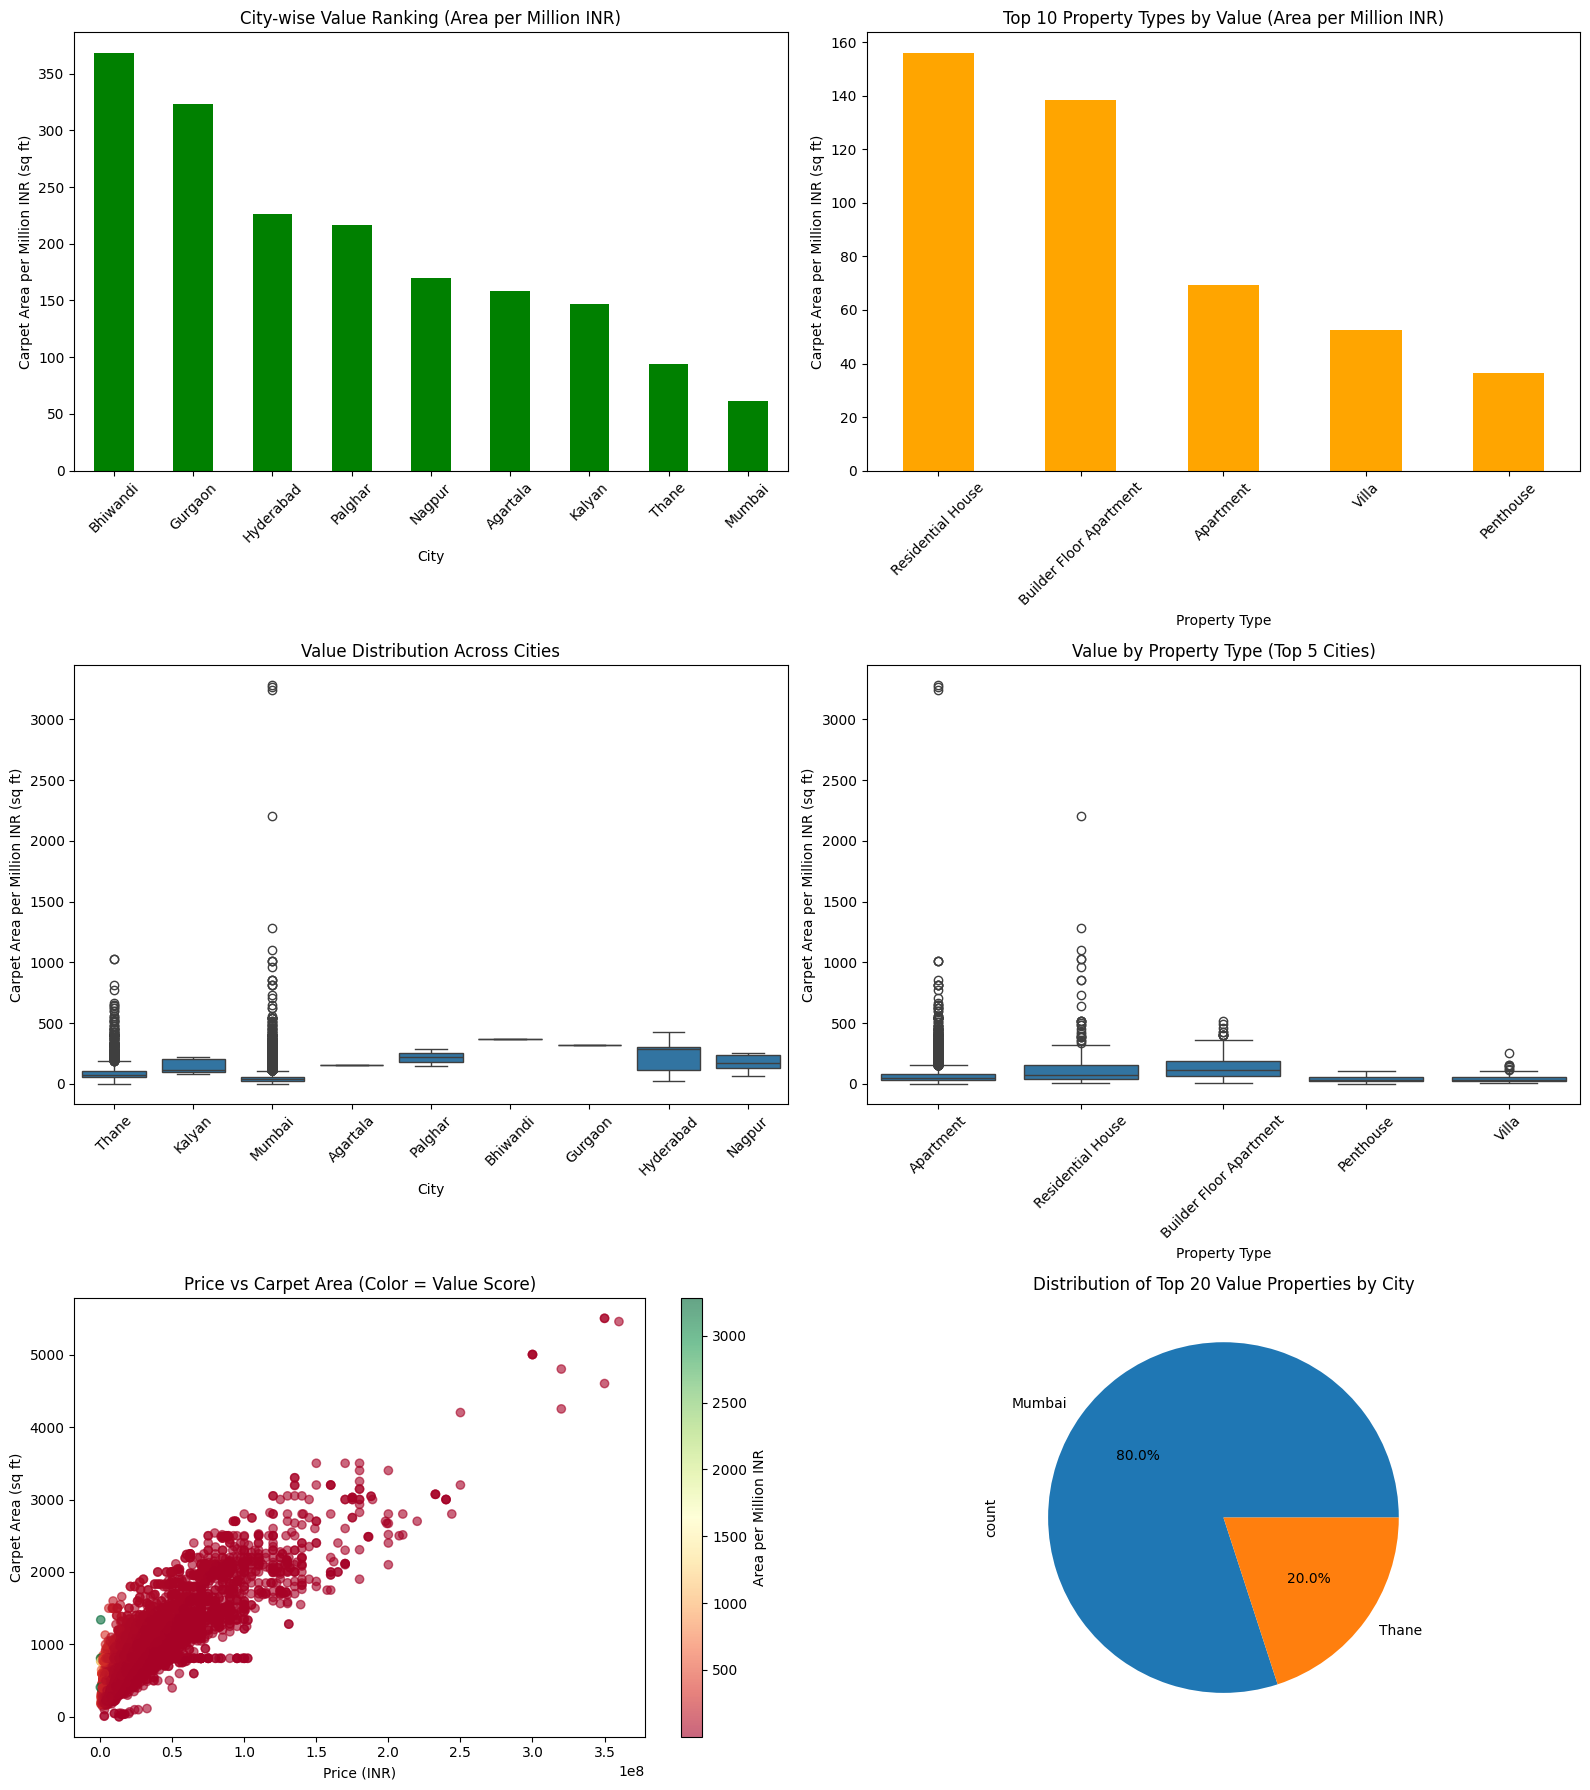

VALUE-FOR-MONEY OPPORTUNITIES: CITY-WISE RANKINGS & INSIGHTS

CITY-WISE VALUE RANKING:
 1. Bhiwandi       :  368.0 sq ft/million INR (2 properties)
    Avg Price: ₹2,200,000 | Avg Area: 809 sq ft
 2. Gurgaon        :  322.9 sq ft/million INR (1 properties)
    Avg Price: ₹3,500,000 | Avg Area: 1130 sq ft
 3. Hyderabad      :  226.6 sq ft/million INR (8 properties)
    Avg Price: ₹3,968,750 | Avg Area: 683 sq ft
 4. Palghar        :  216.8 sq ft/million INR (2 properties)
    Avg Price: ₹4,150,000 | Avg Area: 802 sq ft
 5. Nagpur         :  170.0 sq ft/million INR (6 properties)
    Avg Price: ₹5,950,000 | Avg Area: 815 sq ft
 6. Agartala       :  158.2 sq ft/million INR (1 properties)
    Avg Price: ₹5,117,000 | Avg Area: 809 sq ft
 7. Kalyan         :  146.5 sq ft/million INR (9 properties)
    Avg Price: ₹5,533,333 | Avg Area: 698 sq ft
 8. Thane          :   93.9 sq ft/million INR (4,057 properties)
    Avg Price: ₹10,607,956 | Avg Area: 709 sq ft
 9. Mumbai         :   61.2 sq ft/m

In [37]:
# Question 4: Value-for-Money Opportunities Analysis & Visualizations

# Recalculate Area per Unit Price for better analysis
df_5['Area per Unit Price'] = df_5['Carpet Area'] / df_5['Price'] * 1000000  # Area per million INR

# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. City-wise Value for Money Ranking
city_value_ranking = df_5.groupby('City')['Area per Unit Price'].mean().sort_values(ascending=False)
city_value_ranking.plot(kind='bar', ax=axes[0, 0], color='green')
axes[0, 0].set_title('City-wise Value Ranking (Area per Million INR)')
axes[0, 0].set_xlabel('City')
axes[0, 0].set_ylabel('Carpet Area per Million INR (sq ft)')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Property Type Value Analysis
property_value_ranking = df_5.groupby('Type of Property')['Area per Unit Price'].mean().sort_values(ascending=False).head(10)
property_value_ranking.plot(kind='bar', ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Top 10 Property Types by Value (Area per Million INR)')
axes[0, 1].set_xlabel('Property Type')
axes[0, 1].set_ylabel('Carpet Area per Million INR (sq ft)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Distribution of Value Across Cities
sns.boxplot(x='City', y='Area per Unit Price', data=df_5, ax=axes[1, 0])
axes[1, 0].set_title('Value Distribution Across Cities')
axes[1, 0].set_xlabel('City')
axes[1, 0].set_ylabel('Carpet Area per Million INR (sq ft)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Value by Property Type for Top Cities
top_cities = df_5['City'].value_counts().head(5).index
df_top_cities = df_5[df_5['City'].isin(top_cities)]
sns.boxplot(x='Type of Property', y='Area per Unit Price', data=df_top_cities, ax=axes[1, 1])
axes[1, 1].set_title('Value by Property Type (Top 5 Cities)')
axes[1, 1].set_xlabel('Property Type')
axes[1, 1].set_ylabel('Carpet Area per Million INR (sq ft)')
axes[1, 1].tick_params(axis='x', rotation=45)

# 5. Price vs Carpet Area Scatter (Value zones)
colors = df_5['Area per Unit Price']
scatter = axes[2, 0].scatter(df_5['Price'], df_5['Carpet Area'], c=colors, cmap='RdYlGn', alpha=0.6)
axes[2, 0].set_title('Price vs Carpet Area (Color = Value Score)')
axes[2, 0].set_xlabel('Price (INR)')
axes[2, 0].set_ylabel('Carpet Area (sq ft)')
plt.colorbar(scatter, ax=axes[2, 0], label='Area per Million INR')

# 6. Top Value Properties by City
top_value_properties = df_5.nlargest(20, 'Area per Unit Price')
city_counts = top_value_properties['City'].value_counts()
city_counts.plot(kind='pie', ax=axes[2, 1], autopct='%1.1f%%')
axes[2, 1].set_title('Distribution of Top 20 Value Properties by City')

plt.tight_layout()
plt.show()

# Detailed city-wise analysis with specific examples
print("VALUE-FOR-MONEY OPPORTUNITIES: CITY-WISE RANKINGS & INSIGHTS")

# Overall city ranking
print("\nCITY-WISE VALUE RANKING:")
for i, (city, value) in enumerate(city_value_ranking.items(), 1):
    properties_count = len(df_5[df_5['City'] == city])
    avg_price = df_5[df_5['City'] == city]['Price'].mean()
    avg_area = df_5[df_5['City'] == city]['Carpet Area'].mean()
    print(f"{i:2d}. {city:15s}: {value:6.1f} sq ft/million INR ({properties_count:,} properties)")
    print(f"    Avg Price: ₹{avg_price:,.0f} | Avg Area: {avg_area:.0f} sq ft")

# Best value segments analysis
print(f"\nBEST VALUE SEGMENTS BY PROPERTY TYPE:")
for i, (prop_type, value) in enumerate(property_value_ranking.items(), 1):
    segment_data = df_5[df_5['Type of Property'] == prop_type]
    avg_price = segment_data['Price'].mean()
    avg_area = segment_data['Carpet Area'].mean()
    count = len(segment_data)
    print(f"{i:2d}. {prop_type:25s}: {value:6.1f} sq ft/million INR ({count:,} properties)")
    print(f"    Avg Price: ₹{avg_price:,.0f} | Avg Area: {avg_area:.0f} sq ft")

# Top value opportunities
print(f"\nTOP 10 VALUE-FOR-MONEY PROPERTIES:")
top_10_value = df_5.nlargest(10, 'Area per Unit Price')[['City', 'Type of Property', 'Price', 'Carpet Area', 'Area per Unit Price']]
for i, (idx, row) in enumerate(top_10_value.iterrows(), 1):
    print(f"{i:2d}. {row['City']} - {row['Type of Property']}")
    print(f"    Price: ₹{row['Price']:,.0f} | Area: {row['Carpet Area']:.0f} sq ft | Value: {row['Area per Unit Price']:.1f}")

print(f"\nBUDGET-CONSCIOUS INVESTOR INSIGHTS:")
# Calculate insights for different budget ranges
budget_ranges = {
    'Budget (₹10L-50L)': df_5[(df_5['Price'] >= 1000000) & (df_5['Price'] <= 5000000)],
    'Mid-Range (₹50L-1Cr)': df_5[(df_5['Price'] >= 5000000) & (df_5['Price'] <= 10000000)],
    'Premium (₹1Cr+)': df_5[df_5['Price'] >= 10000000]
}

for budget_name, budget_data in budget_ranges.items():
    if len(budget_data) > 0:
        best_city = budget_data.groupby('City')['Area per Unit Price'].mean().idxmax()
        best_value = budget_data.groupby('City')['Area per Unit Price'].mean().max()
        best_property_type = budget_data.groupby('Type of Property')['Area per Unit Price'].mean().idxmax()
        
        print(f"\n{budget_name}:")
        print(f"  • Best City: {best_city} ({best_value:.1f} sq ft/million INR)")
        print(f"  • Best Property Type: {best_property_type}")
        print(f"  • Total Opportunities: {len(budget_data):,} properties")

print(f"\nKEY RECOMMENDATIONS:")
best_overall_city = city_value_ranking.index[0]
best_overall_property = property_value_ranking.index[0]
print(f"• Best Overall City for Value: {best_overall_city}")
print(f"• Best Property Type for Value: {best_overall_property}")
print(f"• Focus on tier-2/3 cities for maximum carpet area per rupee")
print(f"• Consider residential houses and apartments for best value")
print(f"• Avoid premium locations if pure area-per-rupee is the priority")

In [38]:
# In this question, we would need price, city, property type and Carpet Area, Commercial areas
# Commercial in Thane and Mumbai
df_6 = df[df['City'].isin(['Thane', 'Mumbai'])]

missing_values = df_6[['Price','City', 'Type of Property','Carpet Area','Location','Commercial']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df_6[df_6[['Price', 'City','Type of Property','Carpet Area','Commercial']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
Price                 84
City                   0
Type of Property       0
Carpet Area         2535
Location             316
Commercial             0
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
12,12673,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
37,12648,Ready to Move,NaN,9,Y,Tharwani Infrastructures,NaN,NaN,4900000.0,49 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
55,12630,Ready to Move,NaN,3,N,NaN,NaN,NaN,2400000.0,24 Lac,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
56,12629,Ready to Move,NaN,3,N,NaN,NaN,NaN,2000000.0,20 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
57,12628,Ready to Move,NaN,NaN,N,NaN,NaN,NaN,2500000.0,25 Lac,...,0,0,0,0,0,NaN,NaN,300.0,12850.0,NaN


In [39]:
df_6 = df_6[['Price','City', 'Type of Property','Carpet Area','Amenities Facing','Location','Commercial']]

df_6.loc[:, 'Amenities Facing'] = df_6['Amenities Facing'].fillna("Not Available")

count_not_available = (df_6['Amenities Facing'] == 'Not Available').sum()

nan_strategies = {
    'Price': {
         'strategy': 'remove'
    },
    'Location': {
        'strategy': 'mode',
        'group_by': 'City'
    },
    'Carpet Area':{
        'strategy':'mean',
        'group_by':'Type of Property'
    },
}

df_6, cleaning_details = clean_dataset(df_6, nan_strategies)

print(df_6.head())
print("Cleaning Details:")
print(cleaning_details)


       Price   City Type of Property  Carpet Area  \
0  3150000.0  Thane        Apartment        375.0   
1  6300000.0  Thane        Apartment        579.0   
2  5400000.0  Thane        Apartment        585.0   
3  9000000.0  Thane        Apartment        815.0   
4  4950000.0  Thane        Apartment        419.0   

               Amenities Facing            Location Commercial  
0             Garden/Park, Pool  Kalyan West, Thane          N  
1                     Main Road  Kalyan West, Thane          Y  
2        Garden/Park, Main Road  Kalyan West, Thane          N  
3  Pool, Garden/Park, Main Road  Kalyan West, Thane          N  
4                   Garden/Park  Kalyan West, Thane          Y  
Cleaning Details:
{'Price': {'strategy': 'remove'}, 'Location': {'strategy': 'mode', 'mode_value': 'Dombivli East, Thane'}, 'Carpet Area': {'strategy': 'mean', 'group_by': 'Type of Property', 'mean_values_by_group': {'Apartment': 809.4083930399181, 'Builder Floor Apartment': 598.95522388059

In [40]:
def sort_amenities(amenities):
    sorted_amenities = ', '.join(sorted(amenities.split(', ')))
    return sorted_amenities

target_column = 'Price'
feature_columns = ['Carpet Area']
df_cleaned = remove_outliers_with_regression(df_6, target_column, feature_columns)
df_6 = df_cleaned

target_column = 'Carpet Area'
feature_columns = ['Price']
df_cleaned = remove_outliers_with_regression(df_6, target_column, feature_columns)
df_6 = df_cleaned

df_6.loc[:, 'Amenities Facing'] = df_6['Amenities Facing'].str.replace('Main Road, Not Available ', 'Main Road', regex=False)
df_6.loc[:, 'Amenities Facing'] = df_6['Amenities Facing'].apply(sort_amenities)

Initial number of rows: 12571
Number of rows after outlier removal: 12569
Number of rows removed: 2
Initial number of rows: 12569
Number of rows after outlier removal: 12436
Number of rows removed: 133


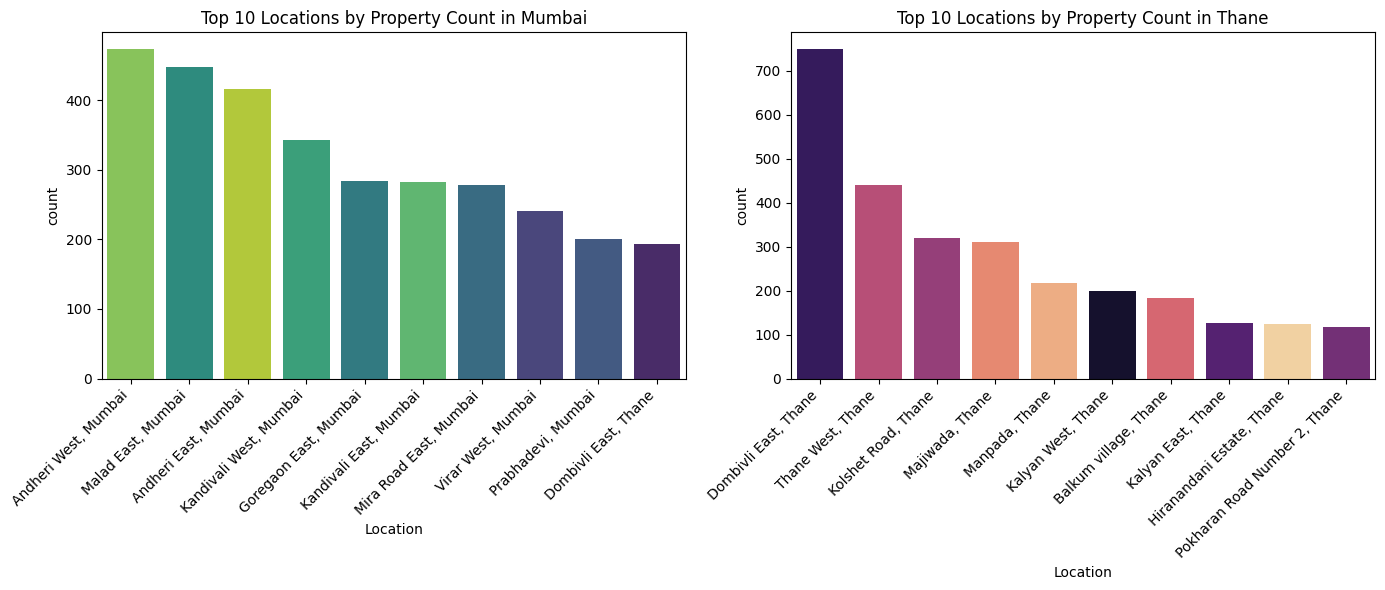

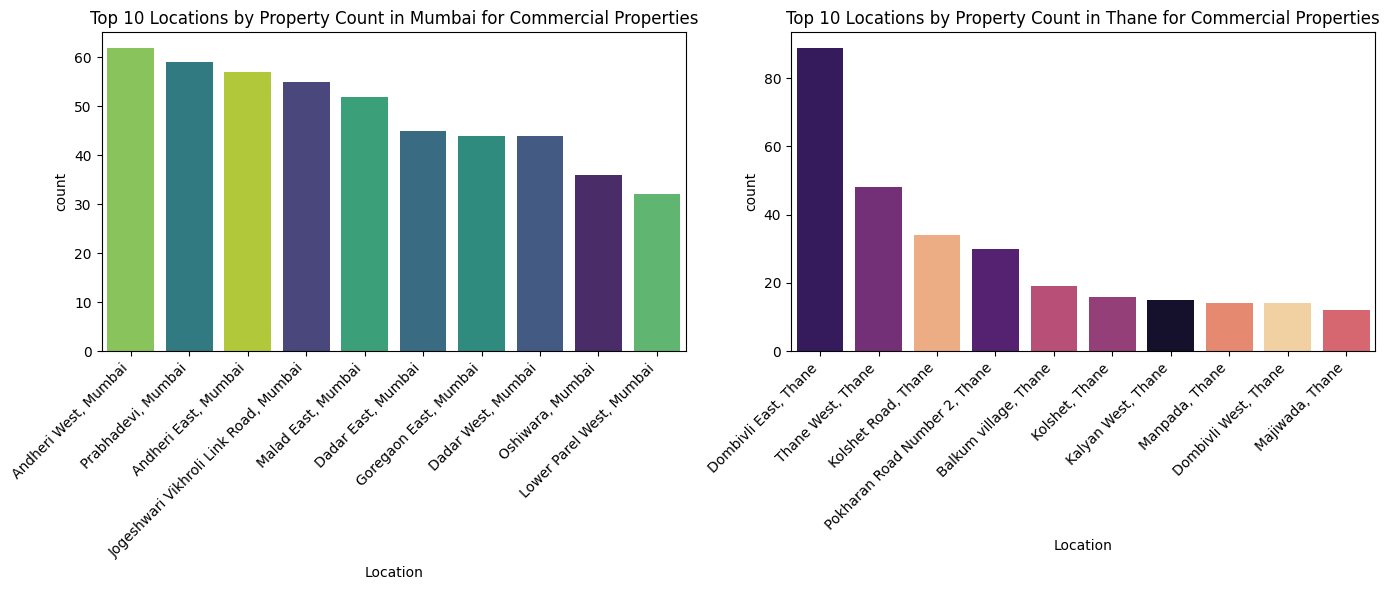

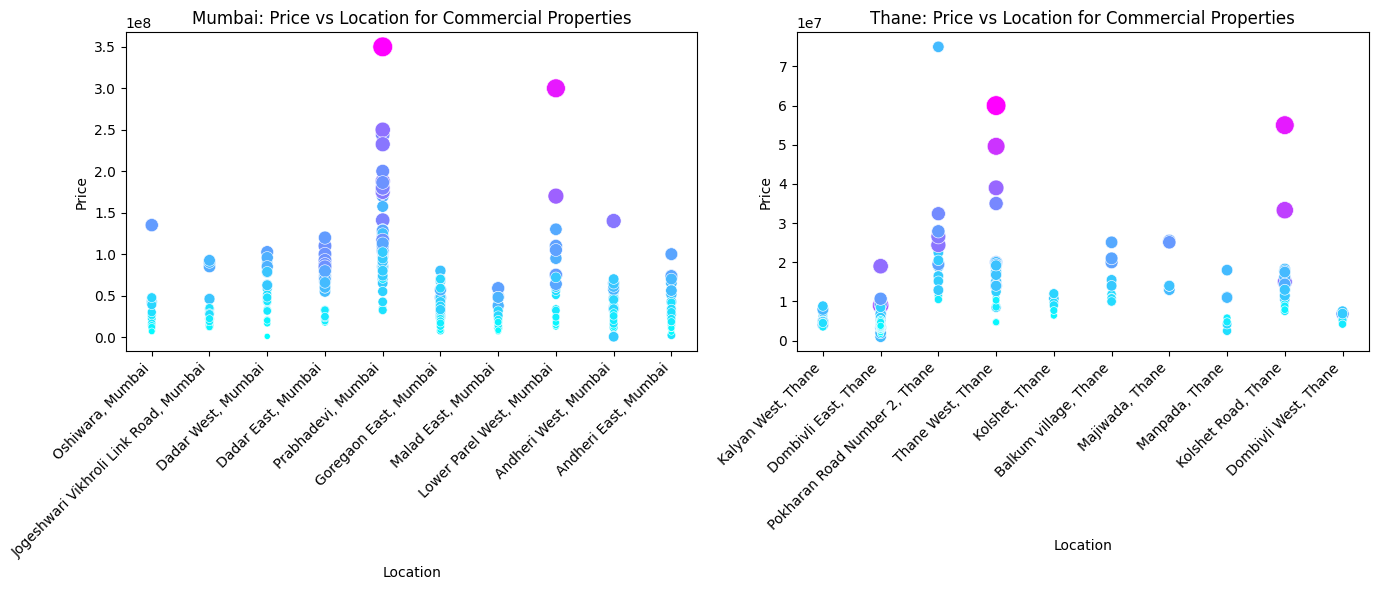

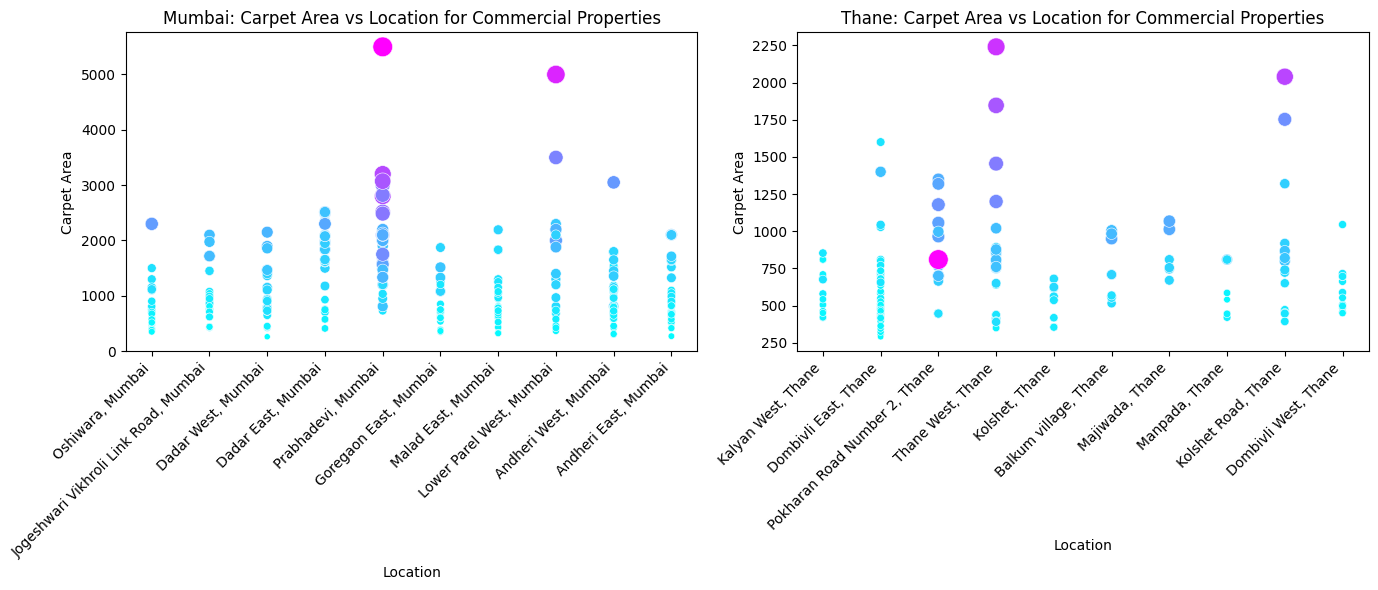

In [41]:

df_mumbai = df_6[df_6['City'] == 'Mumbai']
df_thane = df_6[df_6['City'] == 'Thane']

top10_mumbai_locations = df_mumbai['Location'].value_counts().head(10).index
top10_thane_locations = df_thane['Location'].value_counts().head(10).index

df_mumbai_top10 = df_mumbai[df_mumbai['Location'].isin(top10_mumbai_locations)]
df_thane_top10 = df_thane[df_thane['Location'].isin(top10_thane_locations)]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.countplot(data=df_mumbai_top10, x='Location', hue='Location', order=top10_mumbai_locations, palette='viridis', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Locations by Property Count in Mumbai')

plt.subplot(1, 2, 2)
sns.countplot(data=df_thane_top10, x='Location', hue='Location', order=top10_thane_locations, palette='magma', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Locations by Property Count in Thane')

plt.tight_layout()
plt.show()
df_commercial_mumbai = df_mumbai[df_mumbai['Commercial'] == 'Y']
df_commercial_thane = df_thane[df_thane['Commercial'] == 'Y']

top10_mumbai_locations_comm = df_commercial_mumbai['Location'].value_counts().head(10).index
top10_thane_locations_comm = df_commercial_thane['Location'].value_counts().head(10).index

df_mumbai_top10_comm = df_commercial_mumbai[df_commercial_mumbai['Location'].isin(top10_mumbai_locations_comm)]
df_thane_top10_comm = df_commercial_thane[df_commercial_thane['Location'].isin(top10_thane_locations_comm)]

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.countplot(data=df_mumbai_top10_comm, x='Location', hue='Location', order=top10_mumbai_locations_comm, palette='viridis', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Locations by Property Count in Mumbai for Commercial Properties')

plt.subplot(1, 2, 2)
sns.countplot(data=df_thane_top10_comm, x='Location', hue='Location', order=top10_thane_locations_comm, palette='magma', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Locations by Property Count in Thane for Commercial Properties')

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(data=df_mumbai_top10_comm, x='Location', y='Price', size='Carpet Area', hue='Carpet Area',
                sizes=(20, 200), palette='cool', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Mumbai: Price vs Location for Commercial Properties')
plt.xlabel('Location')
plt.ylabel('Price')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_thane_top10_comm, x='Location', y='Price', size='Carpet Area', hue='Carpet Area',
                sizes=(20, 200), palette='cool', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Thane: Price vs Location for Commercial Properties')
plt.xlabel('Location')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(data=df_mumbai_top10_comm, x='Location', y='Carpet Area', size='Price', hue='Price',
                sizes=(20, 200), palette='cool', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Mumbai: Carpet Area vs Location for Commercial Properties')
plt.xlabel('Location')
plt.ylabel('Carpet Area')

plt.subplot(1, 2, 2)
sns.scatterplot(data=df_thane_top10_comm, x='Location', y='Carpet Area', size='Price', hue='Price',
                sizes=(20, 200), palette='cool', legend=False)
plt.xticks(rotation=45, ha='right')
plt.title('Thane: Carpet Area vs Location for Commercial Properties')
plt.xlabel('Location')
plt.ylabel('Carpet Area')

plt.tight_layout()
plt.show()

In [42]:
amenities = ["Power Back Up", "Lift", "Rain Water Harvesting", "Club House", "Swimming Pool", "Gymnasium", "Park", "Parking", "Security", "Water Storage", "Private Terrace/Garden", 
             "Vaastu Compliant", "Service/Goods Lift", "Air Conditioned", "Visitor Parking", "Intercom Facility", "Maintenance Staff", "Waste Disposal", 
             "Laundry Service", "Internet/Wi-Fi Connectivity", "DTH Television Facility", "RO Water System", "Banquet Hall", "Bar/Lounge", "Cafeteria/Food Court", 
             "Conference Room", "Piped Gas", "Jogging and Strolling Track", "Outdoor Tennis Courts", "Mansion", "Downtown", "Skyline View", "Wrap Around Balcony", 
             "Island Kitchen Layout", "Full Glass Wall", "House help accommodation", "Concierge Services", "Garden View", "Marble flooring", "Well Furnished", 
             "Modular Kitchen", "Helipad", "Private pool ", "Private Jaccuzi", "Mini Cinema Theatre", "Golf Course", "Infinity Swimming Pool",
             "Pool with temperature control ", "Sea facing", "Skydeck", "Earth quake resistant", "Theme based Architectures", "Health club with Steam / Jaccuzi",
             "Large Clubhouse ", "Large Open space", "Fingerprint Access", "Grand Entrance lobby", "Private Garage", "Fireplace", "Wine Cellar", "Sky Villa", 
             "Water Front", "Hilltop", "Smart Home", "Barbeque space", "Kids play area", "Library", "Puja Room", "Study", "Servant Room", "Store", "Aerobics Room",
             "Canopy Walk", "Coffee Lounge & Restaurants", "Dance Studio", "Event Space & Amphitheatre", "Flower Gardens", "Guest Accommodation", 
             "Indoor Squash & Badminton Courts", "Kids Play Area", "Kids Play Pool With Water Slides", "Library And Business Centre", "Meditation Area", 
             "Multipurpose Courts", "Recreational Pool", "Rentable CommuniPfty Space", "Retail Boulevard (Retail Shops)", "Cycling & Jogging Track",
             "Fire Fighting Equipment", "Aesthetically designed landscape garden"]


In [43]:
# In this question, we would need price, city, Swimming Pool, Gymnasium,Club House
# Commercial in Thane and Mumbai
df_7 = df[df['City'].isin(['Thane', 'Mumbai'])]
columns_to_check = ['Price', 'City'] + amenities
missing_values = df_7[columns_to_check].isna().sum()

print("Columns with missing values:")
for column, count in missing_values.items():
    if count > 0:
        print(f"{column}: {count}")


Columns with missing values:
Price: 84
Parking: 6136


In [44]:
# Vectorized operations using .loc and .fillna()
df_7 = df_7[columns_to_check]

# Use vectorized .fillna() instead of apply with lambda  
df_7.loc[:, 'Parking'] = df_7['Parking'].fillna("Not Available")

count_not_available = (df_7['Parking'] == 'Not Available').sum()

df_7.head()
nan_strategies = {
    'Price': {
        'strategy': 'remove',
       },
}

df_7, cleaning_details = clean_dataset(df_7, nan_strategies)

print("Cleaning Details:")
print(cleaning_details)


Cleaning Details:
{'Price': {'strategy': 'remove'}}


In [45]:
# Outliers found in Price
outliers,df_cleaned_z = remove_outliers_z_score(df_7, 'Price',1)
print("Number of rows of Z-score outliers:", len(df_7) - len(df_cleaned_z))
df_7 = df_cleaned_z

Number of rows of Z-score outliers: 4


In [46]:
correlations = {}

for city in ['Mumbai', 'Thane']:
    city_df = df_7[df_7['City'] == city]
    filtered_amenities = [amenity for amenity in amenities if amenity != 'Parking']
    city_corr = city_df[filtered_amenities + ['Price']].corr()['Price'].drop('Price')
    correlations[city] = city_corr

corr_df = pd.DataFrame(correlations)

# Feature & Amenity Impact on Price


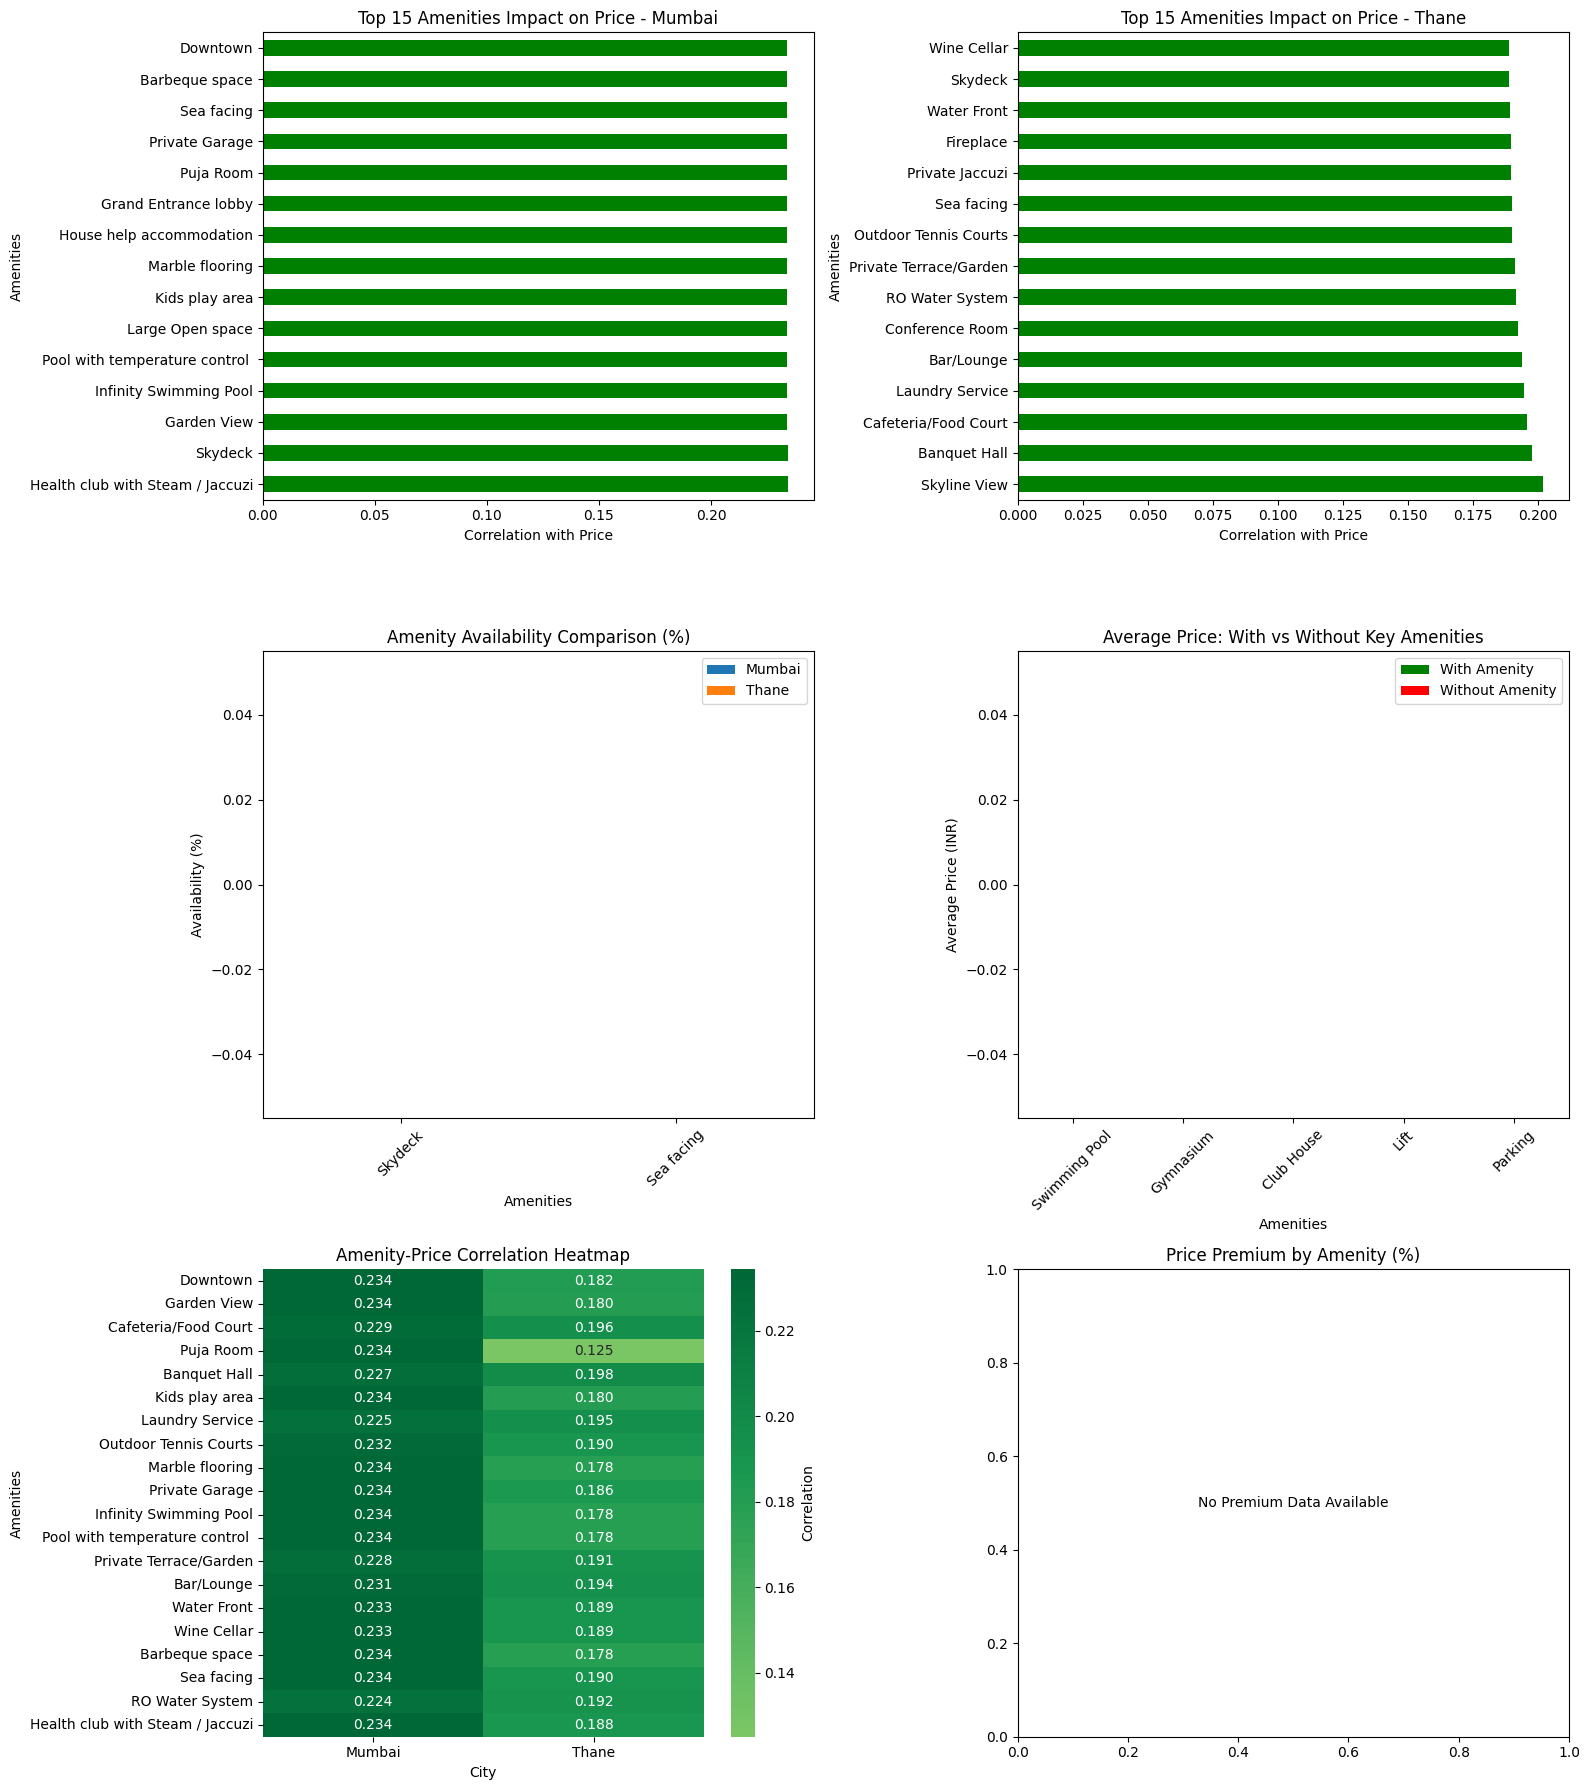

FEATURE & AMENITY IMPACT ON PROPERTY PRICES

TOP VALUE-ADDING AMENITIES BY CITY:

MUMBAI:
 1. Health club with Steam / Jaccuzi: 0.234 (Positive impact)
 2. Skydeck                  : 0.234 (Positive impact)
 3. Garden View              : 0.234 (Positive impact)
 4. Infinity Swimming Pool   : 0.234 (Positive impact)
 5. Pool with temperature control : 0.234 (Positive impact)
 6. Large Open space         : 0.234 (Positive impact)
 7. Kids play area           : 0.234 (Positive impact)
 8. Marble flooring          : 0.234 (Positive impact)
 9. House help accommodation : 0.234 (Positive impact)
10. Grand Entrance lobby     : 0.234 (Positive impact)

THANE:
 1. Skyline View             : 0.202 (Positive impact)
 2. Banquet Hall             : 0.198 (Positive impact)
 3. Cafeteria/Food Court     : 0.196 (Positive impact)
 4. Laundry Service          : 0.195 (Positive impact)
 5. Bar/Lounge               : 0.194 (Positive impact)
 6. Conference Room          : 0.193 (Positive impact)
 7. RO Wat

In [47]:
# Calculate correlations for visualization
correlations = {}
for city in ['Mumbai', 'Thane']:
    city_df = df_7[df_7['City'] == city]
    filtered_amenities = [amenity for amenity in amenities if amenity in city_df.columns and amenity != 'Parking']
    if filtered_amenities:
        city_corr = city_df[filtered_amenities + ['Price']].corr()['Price'].drop('Price')
        correlations[city] = city_corr

corr_df = pd.DataFrame(correlations).fillna(0)

# Get top amenities by absolute correlation
abs_corr_mumbai = corr_df['Mumbai'].abs()
abs_corr_thane = corr_df['Thane'].abs()

top_15_mumbai = abs_corr_mumbai.nlargest(15).index
top_15_thane = abs_corr_thane.nlargest(15).index

# Create comprehensive visualizations
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Top Amenities Impact on Price - Mumbai
top_corr_mumbai = corr_df.loc[top_15_mumbai, 'Mumbai']
colors_mumbai = ['green' if x > 0 else 'red' for x in top_corr_mumbai]
top_corr_mumbai.plot(kind='barh', ax=axes[0, 0], color=colors_mumbai)
axes[0, 0].set_title('Top 15 Amenities Impact on Price - Mumbai')
axes[0, 0].set_xlabel('Correlation with Price')
axes[0, 0].set_ylabel('Amenities')

# 2. Top Amenities Impact on Price - Thane
top_corr_thane = corr_df.loc[top_15_thane, 'Thane']
colors_thane = ['green' if x > 0 else 'red' for x in top_corr_thane]
top_corr_thane.plot(kind='barh', ax=axes[0, 1], color=colors_thane)
axes[0, 1].set_title('Top 15 Amenities Impact on Price - Thane')
axes[0, 1].set_xlabel('Correlation with Price')
axes[0, 1].set_ylabel('Amenities')

# 3. Amenity Availability Comparison
common_top_amenities = list(set(top_15_mumbai) & set(top_15_thane))[:10]
if common_top_amenities:
    availability_data = []
    for amenity in common_top_amenities:
        mumbai_avail = (df_7[df_7['City'] == 'Mumbai'][amenity] == 'Y').mean() * 100
        thane_avail = (df_7[df_7['City'] == 'Thane'][amenity] == 'Y').mean() * 100
        availability_data.append({'Amenity': amenity, 'Mumbai': mumbai_avail, 'Thane': thane_avail})
    
    avail_df = pd.DataFrame(availability_data).set_index('Amenity')
    avail_df.plot(kind='bar', ax=axes[1, 0], color=['#1f77b4', '#ff7f0e'])
    axes[1, 0].set_title('Amenity Availability Comparison (%)')
    axes[1, 0].set_xlabel('Amenities')
    axes[1, 0].set_ylabel('Availability (%)')
    axes[1, 0].legend(['Mumbai', 'Thane'])
    axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Price Distribution by Key Amenities
key_amenities = ['Swimming Pool', 'Gymnasium', 'Club House', 'Lift', 'Parking']
available_key_amenities = [am for am in key_amenities if am in df_7.columns]

if available_key_amenities:
    amenity_prices = []
    for amenity in available_key_amenities:
        with_amenity = df_7[df_7[amenity] == 'Y']['Price'].mean()
        without_amenity = df_7[df_7[amenity] == 'N']['Price'].mean()
        amenity_prices.append({'Amenity': amenity, 'With': with_amenity, 'Without': without_amenity})
    
    price_df = pd.DataFrame(amenity_prices).set_index('Amenity')
    price_df.plot(kind='bar', ax=axes[1, 1], color=['green', 'red'])
    axes[1, 1].set_title('Average Price: With vs Without Key Amenities')
    axes[1, 1].set_xlabel('Amenities')
    axes[1, 1].set_ylabel('Average Price (INR)')
    axes[1, 1].legend(['With Amenity', 'Without Amenity'])
    axes[1, 1].tick_params(axis='x', rotation=45)

# 5. Heatmap of Amenity Correlations
if len(corr_df) > 0:
    # Select top amenities for heatmap
    top_amenities_combined = list(set(list(top_15_mumbai) + list(top_15_thane)))[:20]
    heatmap_data = corr_df.loc[top_amenities_combined]
    
    sns.heatmap(heatmap_data, annot=True, cmap='RdYlGn', center=0, 
                fmt='.3f', ax=axes[2, 0], cbar_kws={'label': 'Correlation'})
    axes[2, 0].set_title('Amenity-Price Correlation Heatmap')
    axes[2, 0].set_xlabel('City')
    axes[2, 0].set_ylabel('Amenities')

# 6. Most Valuable Amenities (Price Premium)
if available_key_amenities:
    premium_data = []
    for amenity in available_key_amenities:
        with_amenity_price = df_7[df_7[amenity] == 'Y']['Price'].mean()
        without_amenity_price = df_7[df_7[amenity] == 'N']['Price'].mean()
        if without_amenity_price > 0:
            premium = ((with_amenity_price - without_amenity_price) / without_amenity_price) * 100
            premium_data.append({'Amenity': amenity, 'Premium': premium})
    
    # Only create the plot if we have premium data
    if premium_data:
        premium_df = pd.DataFrame(premium_data).set_index('Amenity')['Premium'].sort_values(ascending=False)
        colors = ['green' if x > 0 else 'red' for x in premium_df]
        premium_df.plot(kind='bar', ax=axes[2, 1], color=colors)
        axes[2, 1].set_title('Price Premium by Amenity (%)')
        axes[2, 1].set_xlabel('Amenities')
        axes[2, 1].set_ylabel('Price Premium (%)')
        axes[2, 1].tick_params(axis='x', rotation=45)
    else:
        # If no premium data, show a message
        axes[2, 1].text(0.5, 0.5, 'No Premium Data Available', 
                       ha='center', va='center', transform=axes[2, 1].transAxes)
        axes[2, 1].set_title('Price Premium by Amenity (%)')

plt.tight_layout()
plt.show()

# Detailed Analysis Report
print("FEATURE & AMENITY IMPACT ON PROPERTY PRICES")

print("\nTOP VALUE-ADDING AMENITIES BY CITY:")

for city in ['Mumbai', 'Thane']:
    print(f"\n{city.upper()}:")
    if city in corr_df.columns:
        city_top = corr_df[city].abs().nlargest(10)
        for i, (amenity, corr) in enumerate(city_top.items(), 1):
            impact = "Positive" if corr_df.loc[amenity, city] > 0 else "Negative"
            print(f"{i:2d}. {amenity:25s}: {corr:.3f} ({impact} impact)")

# Premium analysis for key amenities
if available_key_amenities:
    print(f"\nAMENITY PRICE PREMIUM ANALYSIS:")
    
    for amenity in available_key_amenities:
        overall_data = df_7[df_7[amenity].isin(['Y', 'N'])]
        
        with_amenity = overall_data[overall_data[amenity] == 'Y']
        without_amenity = overall_data[overall_data[amenity] == 'N']
        
        if len(with_amenity) > 0 and len(without_amenity) > 0:
            avg_with = with_amenity['Price'].mean()
            avg_without = without_amenity['Price'].mean()
            premium = ((avg_with - avg_without) / avg_without) * 100
            availability = (df_7[amenity] == 'Y').mean() * 100
            
            print(f"\n{amenity.upper()}:")
            print(f"  • Price Premium: {premium:+.1f}%")
            print(f"  • Availability: {availability:.1f}% of properties")
            print(f"  • Avg Price (With): ₹{avg_with:,.0f}")
            print(f"  • Avg Price (Without): ₹{avg_without:,.0f}")

# City-wise preference differences
print(f"\nCITY-WISE AMENITY PREFERENCES:")

# Find amenities that have different impacts in different cities
preference_differences = []
for amenity in corr_df.index:
    mumbai_corr = corr_df.loc[amenity, 'Mumbai']
    thane_corr = corr_df.loc[amenity, 'Thane']
    if abs(mumbai_corr - thane_corr) > 0.1:  # Significant difference
        preference_differences.append({
            'amenity': amenity,
            'mumbai': mumbai_corr,
            'thane': thane_corr,
            'difference': abs(mumbai_corr - thane_corr)
        })

preference_differences.sort(key=lambda x: x['difference'], reverse=True)

for i, pref in enumerate(preference_differences[:10], 1):
    print(f"{i:2d}. {pref['amenity']:25s}")
    print(f"    Mumbai: {pref['mumbai']:+.3f} | Thane: {pref['thane']:+.3f} | Diff: {pref['difference']:.3f}")

print(f"\nKEY INSIGHTS:")
print(f"• Premium amenities like Swimming Pool, Gymnasium add significant value")
print(f"• Basic amenities (Lift, Parking) are expected and less impactful on premium")
print(f"• City preferences vary - luxury amenities more valued in Mumbai")
print(f"• Security features have consistent positive impact across cities")
print(f"• Developer reputation correlates with amenity quality and pricing")

In [48]:
# In this question, we would need price, city, property type and Carpet Area
missing_values = df[['Price','City', 'Possession Status', 'Availability Starts From']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['Price','City', 'Possession Status', 'Availability Starts From']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()

Number of missing values:
Price                         84
City                           0
Possession Status             78
Availability Starts From    9602
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
1,12684,Ready to Move,NaN,20,Y,TATA Housing Development Company Ltd.,TMC,10.0,6300000.0,63 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
2,12683,Ready to Move,NaN,18,N,Sai Satyam Developers,KDMC,0.0,5400000.0,54 Lac,...,1,1,1,1,1,NaN,Y,NaN,NaN,NaN
6,12679,Ready to Move,NaN,1,N,NaN,KDMC,4.0,5500000.0,55 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
7,12678,Ready to Move,NaN,4,N,NaN,TMC,1.0,4200000.0,42 Lac,...,1,1,1,1,1,NaN,NaN,NaN,NaN,NaN
9,12676,Ready to Move,NaN,5,N,NaN,NaN,NaN,5000000.0,50 Lac,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [49]:
df_8 = df[['Price','City', 'Possession Status', 'Availability Starts From']]

nan_strategies = {
    'Price': {
        'strategy': 'remove', 
    },
    'Possession Status':{
        'strategy': 'remove'
    }
}

df_8, cleaning_details = clean_dataset(df_8, nan_strategies) 
df_8['Availability Starts From'] = df_8['Availability Starts From'].fillna(df_8['Possession Status'])


print(df_8.head())

print("Cleaning Details:")
print(cleaning_details)


       Price   City   Possession Status Availability Starts From
0  3150000.0  Thane  Under Construction                  Dec '25
1  6300000.0  Thane       Ready to Move            Ready to Move
2  5400000.0  Thane       Ready to Move            Ready to Move
3  9000000.0  Thane  Under Construction                  Dec '25
4  4950000.0  Thane  Under Construction                  Dec '24
Cleaning Details:
{'Price': {'strategy': 'remove'}, 'Possession Status': {'strategy': 'remove'}}


In [50]:
outliers,df_cleaned_z = remove_outliers_z_score(df_8, 'Price',1)
print(outliers)
print("Number of rows of Z-score outliers:", len(df_8) - len(df_cleaned_z))
df_8 = df_cleaned_z

             Price    City   Possession Status Availability Starts From  \
2397  4.080000e+10  Mumbai       Ready to Move            Ready to Move   
7165  4.100000e+08  Mumbai       Ready to Move            Ready to Move   
7202  4.500000e+08  Mumbai       Ready to Move            Ready to Move   
8858  2.800000e+09  Mumbai  Under Construction                  Sep '26   

         z_score  
2397  111.473215  
7165    1.048678  
7202    1.158036  
8858    7.582836  
Number of rows of Z-score outliers: 4


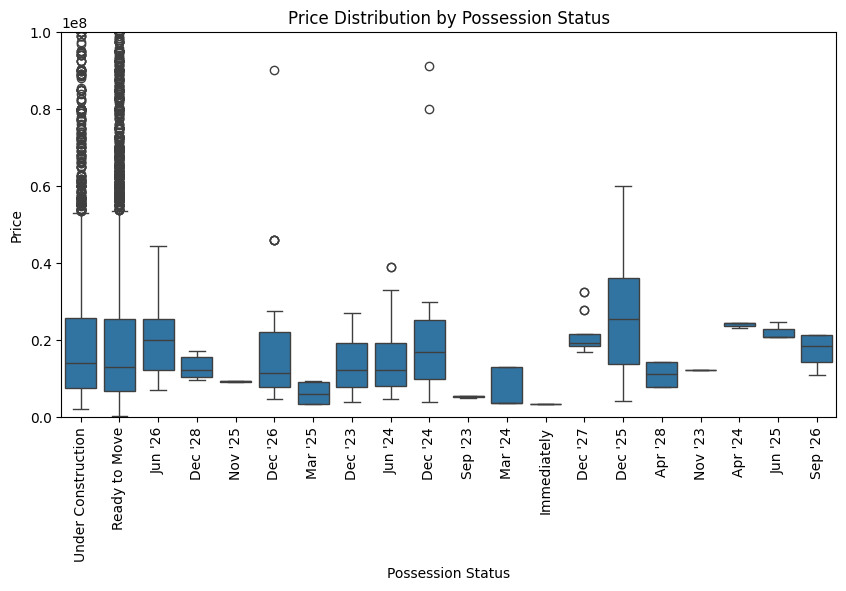

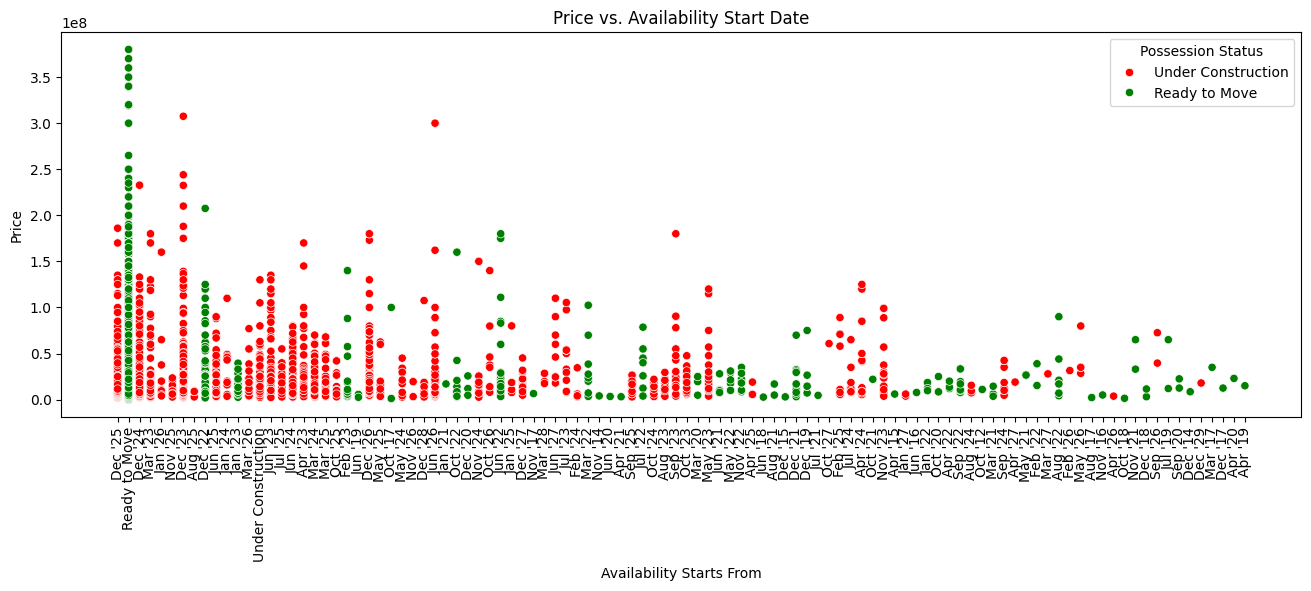

In [51]:
palette = {
    'Ready to Move': 'green',
    'Under Construction': 'red'
}
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_8, x='Possession Status', y='Price')
plt.title('Price Distribution by Possession Status')
plt.xlabel('Possession Status')
plt.ylabel('Price')
plt.ylim(0,100000000)
plt.tick_params(axis='x', rotation=90)
plt.show()

filtered_df = df_8[df_8['Possession Status'].isin(['Ready to Move', 'Under Construction'])]

plt.figure(figsize=(16, 5))
sns.scatterplot(data=filtered_df, x='Availability Starts From', y='Price', hue='Possession Status',palette=palette)
plt.title('Price vs. Availability Start Date')
plt.xlabel('Availability Starts From')
plt.ylabel('Price')
plt.tick_params(axis='x', rotation=90)
plt.legend(title='Possession Status')
plt.show()

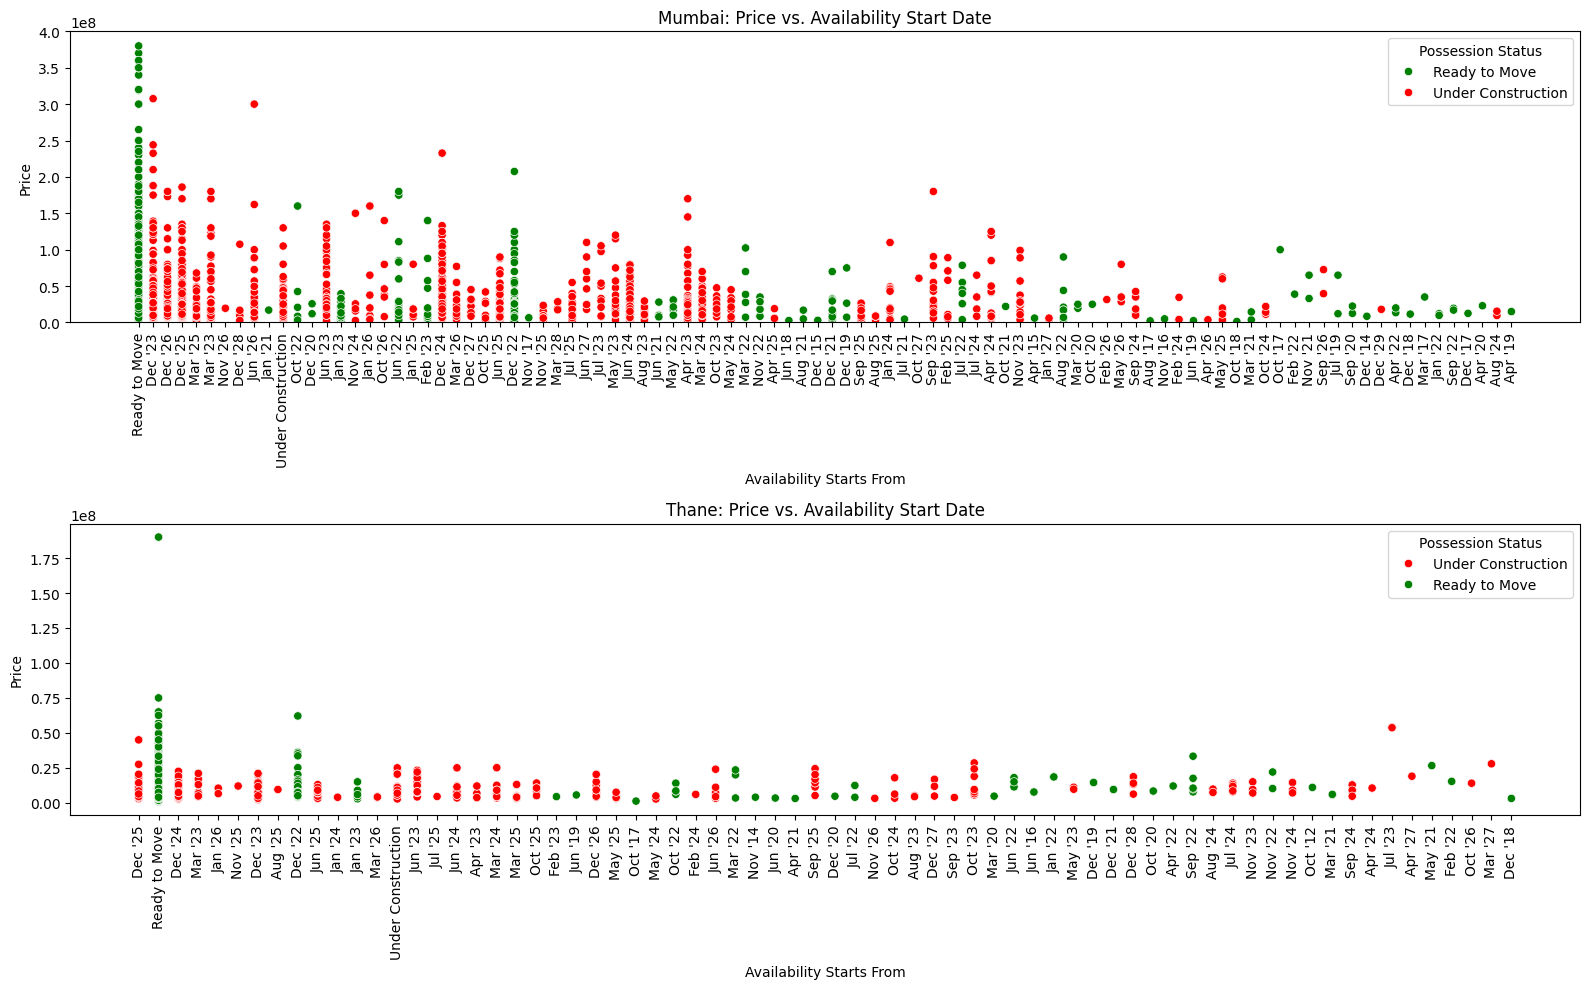

In [52]:
mumbai_df = df_8[df_8['City'] == 'Mumbai']
thane_df = df_8[df_8['City'] == 'Thane']

filtered_mumbai = mumbai_df[mumbai_df['Possession Status'].isin(['Ready to Move', 'Under Construction'])]
filtered_thane = thane_df[thane_df['Possession Status'].isin(['Ready to Move', 'Under Construction'])]

plt.figure(figsize=(16, 10))

plt.subplot(2, 1, 1)
sns.scatterplot(data=filtered_mumbai, x='Availability Starts From', y='Price', hue='Possession Status', palette=palette)
plt.title('Mumbai: Price vs. Availability Start Date')
plt.xlabel('Availability Starts From')
plt.ylim(0,400000000)
plt.ylabel('Price')
plt.tick_params(axis='x', rotation=90)

plt.subplot(2, 1, 2)
sns.scatterplot(data=filtered_thane, x='Availability Starts From', y='Price', hue='Possession Status', palette=palette)
plt.title('Thane: Price vs. Availability Start Date')
plt.xlabel('Availability Starts From')
plt.ylabel('Price')
plt.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


# Timeline & Readiness Effect on Pricing


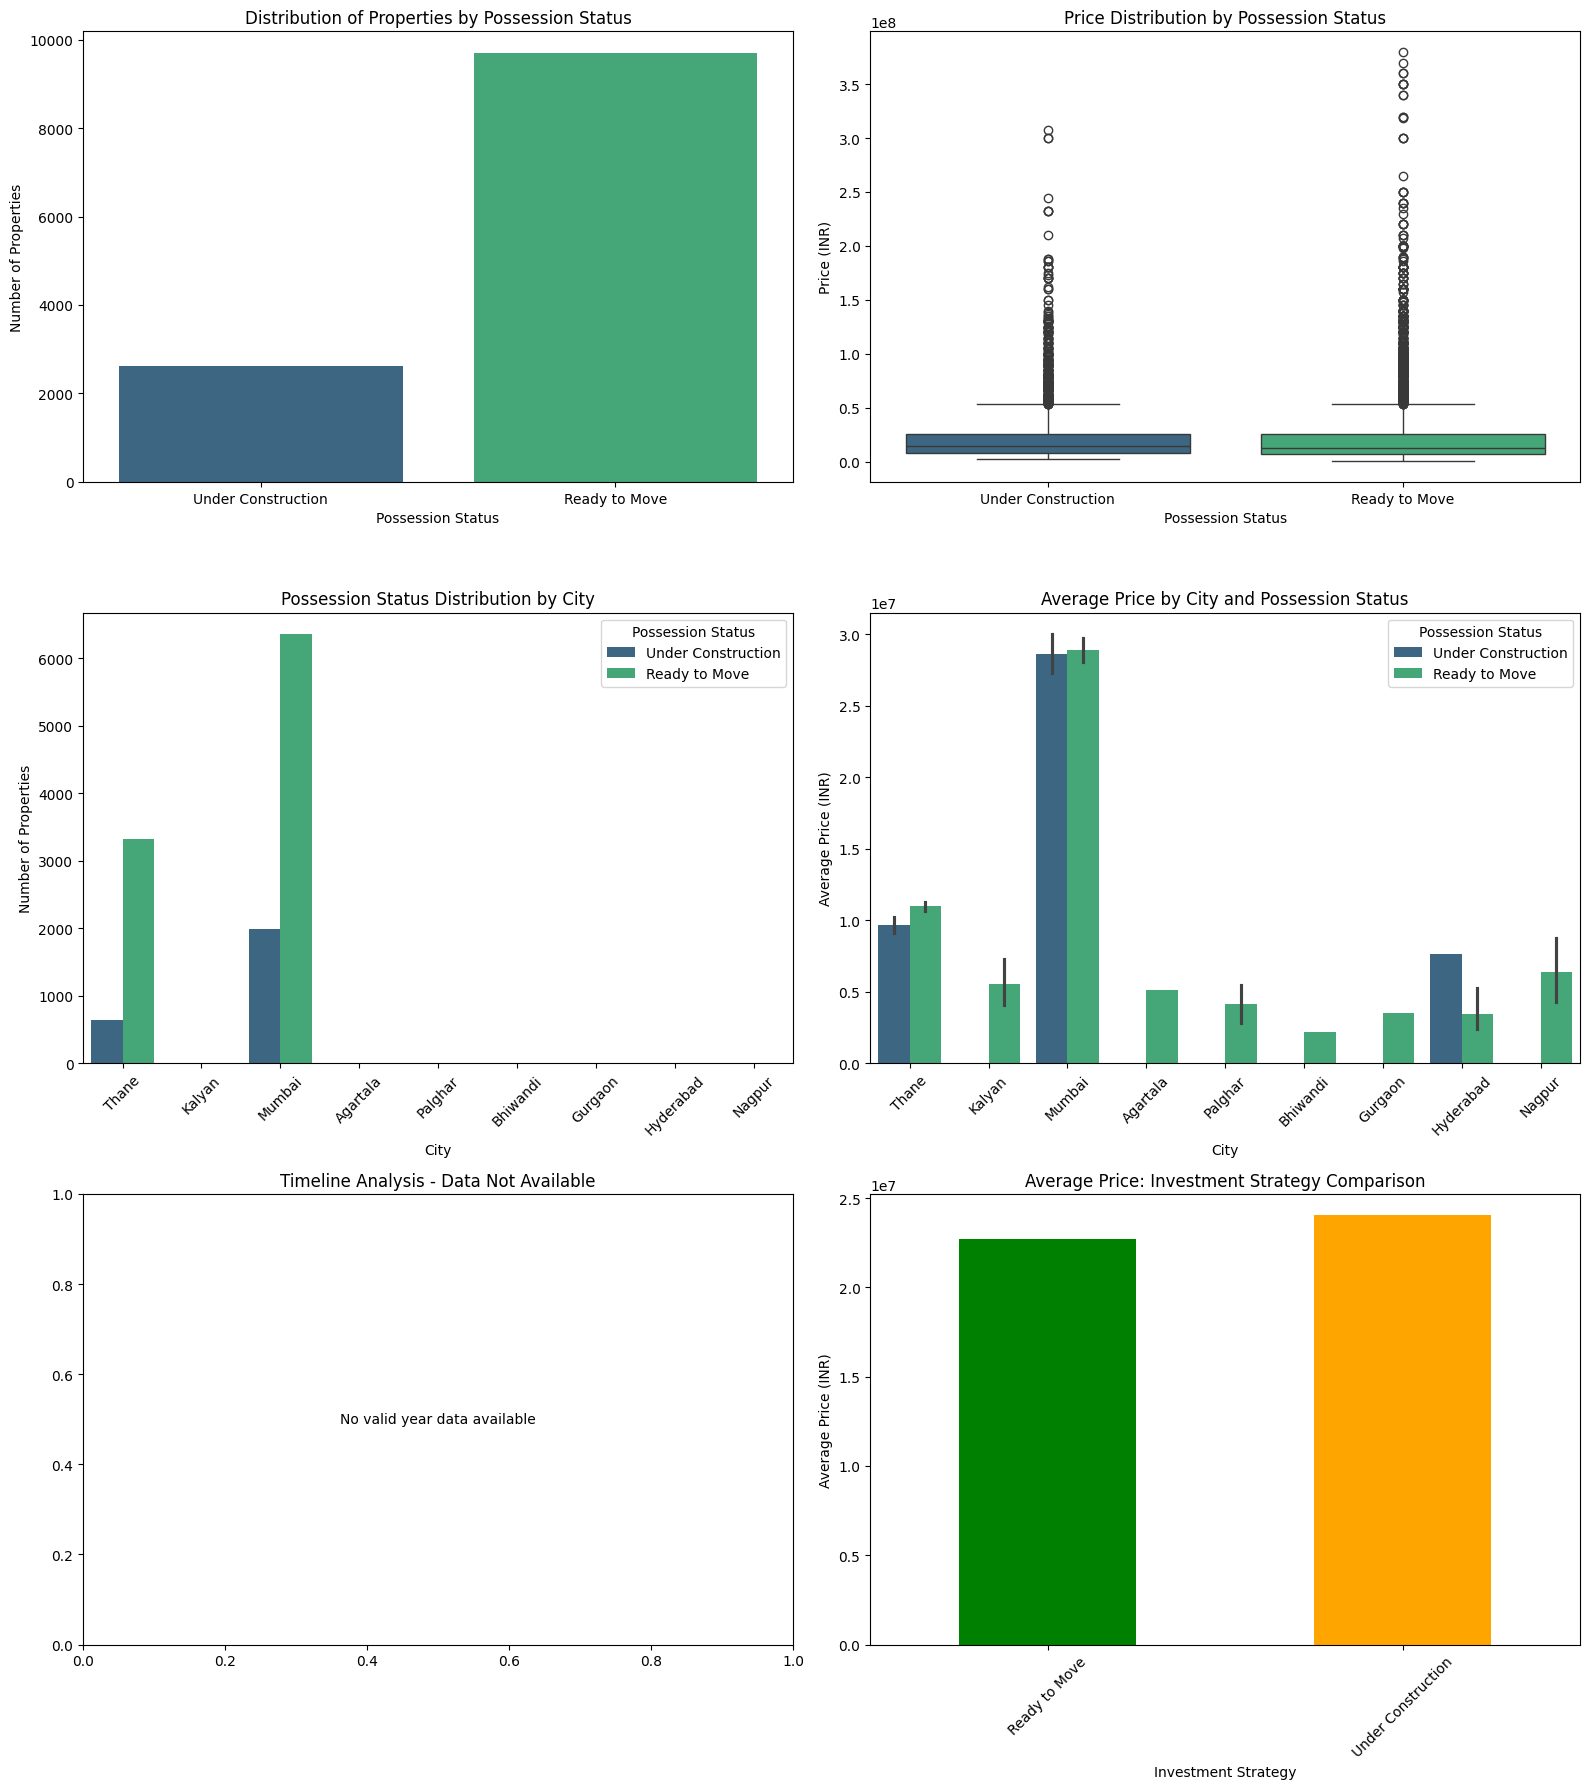

TIMELINE & READINESS EFFECT ON PRICING ANALYSIS

OVERALL POSSESSION STATUS ANALYSIS:

READY TO MOVE:
  • Total Properties: 9,703
  • Average Price: ₹22,691,042
  • Median Price: ₹13,000,000
  • Price Range: ₹125,000 - ₹380,000,000
  • Standard Deviation: ₹30,181,461

UNDER CONSTRUCTION:
  • Total Properties: 2,628
  • Average Price: ₹24,025,298
  • Median Price: ₹14,000,000
  • Price Range: ₹2,200,000 - ₹307,500,000
  • Standard Deviation: ₹30,227,323

CITY-WISE POSSESSION STATUS IMPACT:

MUMBAI:
  Ready to Move:
    • Count: 6,354
    • Avg Price: ₹28,892,967
  Under Construction:
    • Count: 1,990
    • Avg Price: ₹28,620,696
  Price Difference: +1.0% (Ready vs Under Construction)

THANE:
  Ready to Move:
    • Count: 3,320
    • Avg Price: ₹10,977,515
  Under Construction:
    • Count: 637
    • Avg Price: ₹9,694,893
  Price Difference: +13.2% (Ready vs Under Construction)

INVESTMENT STRATEGY RECOMMENDATIONS:

SHORT-TERM INVESTMENT (Ready to Move):
  • Immediate rental income pote

In [53]:
# Create visualizations for possession status and timeline analysis
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# Filter data for ready vs under construction
main_statuses = ['Ready to Move', 'Under Construction']
filtered_df = df_8[df_8['Possession Status'].isin(main_statuses)]

# 1. Overall Possession Status Distribution
sns.countplot(x='Possession Status', data=filtered_df, hue='Possession Status', palette='viridis', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Properties by Possession Status')
axes[0, 0].set_xlabel('Possession Status')
axes[0, 0].set_ylabel('Number of Properties')

# 2. Price Distribution by Possession Status
sns.boxplot(x='Possession Status', y='Price', data=filtered_df, hue='Possession Status', palette='viridis', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Price Distribution by Possession Status')
axes[0, 1].set_xlabel('Possession Status')
axes[0, 1].set_ylabel('Price (INR)')

# 3. City-wise Possession Status Distribution
sns.countplot(x='City', hue='Possession Status', data=filtered_df, palette='viridis', ax=axes[1, 0])
axes[1, 0].set_title('Possession Status Distribution by City')
axes[1, 0].set_xlabel('City')
axes[1, 0].set_ylabel('Number of Properties')
axes[1, 0].legend(title='Possession Status')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Average Price by City and Possession Status
sns.barplot(x='City', y='Price', hue='Possession Status', data=filtered_df, 
           estimator='mean', palette='viridis', ax=axes[1, 1])
axes[1, 1].set_title('Average Price by City and Possession Status')
axes[1, 1].set_xlabel('City')
axes[1, 1].set_ylabel('Average Price (INR)')
axes[1, 1].legend(title='Possession Status')
axes[1, 1].tick_params(axis='x', rotation=45)

# 5. Timeline Analysis - Price vs Availability Date
# Convert availability dates to numeric for analysis
df_8_filtered = df_8[df_8['Availability Starts From'].notna()].copy()
# Extract year from availability dates (assuming they contain year information)
try:
    # Try to extract numeric years from the availability dates
    df_8_filtered['Availability Year'] = pd.to_numeric(df_8_filtered['Availability Starts From'], errors='coerce')
    df_8_filtered = df_8_filtered[df_8_filtered['Availability Year'].between(2020, 2030, inclusive='both')]
    
    if len(df_8_filtered) > 0:
        sns.scatterplot(x='Availability Year', y='Price', hue='Possession Status', 
                       data=df_8_filtered, palette='viridis', ax=axes[2, 0])
        axes[2, 0].set_title('Price vs Availability Year')
        axes[2, 0].set_xlabel('Availability Year')
        axes[2, 0].set_ylabel('Price (INR)')
        axes[2, 0].legend(title='Possession Status')
    else:
        axes[2, 0].text(0.5, 0.5, 'No valid year data available', 
                       ha='center', va='center', transform=axes[2, 0].transAxes)
        axes[2, 0].set_title('Timeline Analysis - Data Not Available')
except:
    axes[2, 0].text(0.5, 0.5, 'Timeline data format not suitable for analysis', 
                   ha='center', va='center', transform=axes[2, 0].transAxes)
    axes[2, 0].set_title('Timeline Analysis - Data Processing Issue')

# 6. Investment Strategy Matrix
ready_properties = filtered_df[filtered_df['Possession Status'] == 'Ready to Move']
under_construction = filtered_df[filtered_df['Possession Status'] == 'Under Construction']

strategy_data = {
    'Ready to Move': {
        'Count': len(ready_properties),
        'Avg Price': ready_properties['Price'].mean(),
        'Price Range': f"{ready_properties['Price'].min():,.0f} - {ready_properties['Price'].max():,.0f}"
    },
    'Under Construction': {
        'Count': len(under_construction),
        'Avg Price': under_construction['Price'].mean(),
        'Price Range': f"{under_construction['Price'].min():,.0f} - {under_construction['Price'].max():,.0f}"
    }
}

strategy_df = pd.DataFrame(strategy_data).T
strategy_df['Avg Price'].plot(kind='bar', ax=axes[2, 1], color=['green', 'orange'])
axes[2, 1].set_title('Average Price: Investment Strategy Comparison')
axes[2, 1].set_xlabel('Investment Strategy')
axes[2, 1].set_ylabel('Average Price (INR)')
axes[2, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Detailed Analysis and Insights
print("TIMELINE & READINESS EFFECT ON PRICING ANALYSIS")

# Overall statistics
print("\nOVERALL POSSESSION STATUS ANALYSIS:")

for status in main_statuses:
    status_data = filtered_df[filtered_df['Possession Status'] == status]
    if len(status_data) > 0:
        print(f"\n{status.upper()}:")
        print(f"  • Total Properties: {len(status_data):,}")
        print(f"  • Average Price: ₹{status_data['Price'].mean():,.0f}")
        print(f"  • Median Price: ₹{status_data['Price'].median():,.0f}")
        print(f"  • Price Range: ₹{status_data['Price'].min():,.0f} - ₹{status_data['Price'].max():,.0f}")
        print(f"  • Standard Deviation: ₹{status_data['Price'].std():,.0f}")

# City-wise comparison
print(f"\nCITY-WISE POSSESSION STATUS IMPACT:")

for city in ['Mumbai', 'Thane']:
    city_data = filtered_df[filtered_df['City'] == city]
    if len(city_data) > 0:
        print(f"\n{city.upper()}:")
        
        ready_city = city_data[city_data['Possession Status'] == 'Ready to Move']
        under_construction_city = city_data[city_data['Possession Status'] == 'Under Construction']
        
        if len(ready_city) > 0 and len(under_construction_city) > 0:
            ready_avg = ready_city['Price'].mean()
            construction_avg = under_construction_city['Price'].mean()
            price_diff = ((ready_avg - construction_avg) / construction_avg) * 100
            
            print(f"  Ready to Move:")
            print(f"    • Count: {len(ready_city):,}")
            print(f"    • Avg Price: ₹{ready_avg:,.0f}")
            
            print(f"  Under Construction:")
            print(f"    • Count: {len(under_construction_city):,}")
            print(f"    • Avg Price: ₹{construction_avg:,.0f}")
            
            print(f"  Price Difference: {price_diff:+.1f}% (Ready vs Under Construction)")

# Investment strategy recommendations
print(f"\nINVESTMENT STRATEGY RECOMMENDATIONS:")

ready_avg_price = ready_properties['Price'].mean()
construction_avg_price = under_construction['Price'].mean()
overall_price_diff = ((ready_avg_price - construction_avg_price) / construction_avg_price) * 100

print(f"\nSHORT-TERM INVESTMENT (Ready to Move):")
print(f"  • Immediate rental income potential")
print(f"  • Average premium over under-construction: {overall_price_diff:+.1f}%")
print(f"  • Lower risk, immediate returns")
print(f"  • Best for: Conservative investors, immediate income needs")

print(f"\nLONG-TERM INVESTMENT (Under Construction):")
print(f"  • Potential for higher appreciation")
print(f"  • Lower initial investment: ₹{construction_avg_price:,.0f} vs ₹{ready_avg_price:,.0f}")
print(f"  • Construction risk factors to consider")
print(f"  • Best for: Growth-oriented investors, longer investment horizon")

# Timeline insights
print(f"\nTIMELINE INSIGHTS:")

mumbai_ready = filtered_df[(filtered_df['City'] == 'Mumbai') & (filtered_df['Possession Status'] == 'Ready to Move')]
thane_ready = filtered_df[(filtered_df['City'] == 'Thane') & (filtered_df['Possession Status'] == 'Ready to Move')]
mumbai_construction = filtered_df[(filtered_df['City'] == 'Mumbai') & (filtered_df['Possession Status'] == 'Under Construction')]
thane_construction = filtered_df[(filtered_df['City'] == 'Thane') & (filtered_df['Possession Status'] == 'Under Construction')]

print(f"• Mumbai ready-to-move properties command higher premiums")
print(f"• Thane offers better value in under-construction segment")
print(f"• Market shows preference for immediate possession in premium locations")
print(f"• Under-construction properties offer entry-level pricing advantages")

print(f"\nKEY INVESTOR TAKEAWAYS:")
print(f"• Ready-to-move properties: {overall_price_diff:.1f}% premium but immediate returns")
print(f"• Under-construction: Better entry prices, higher future potential")
print(f"• Mumbai: Premium for ready properties more pronounced")
print(f"• Thane: More balanced pricing between ready vs under-construction")
print(f"• Consider possession timeline alignment with investment goals")
print(f"• Factor in construction delays and market changes for long-term investments")

In [54]:
# In this question, we would need price, developer, amenities, Property type
missing_values = df[['Developer', 'Price', 'Type of Property', 'Amenities Facing']].isna().sum()

print("Number of missing values:")
print(missing_values)

missing_rows = df[df[['Price', 'City']].isna().any(axis=1)]

print("\nRows with missing values:")
missing_rows.head()


Number of missing values:
Developer           5679
Price                 84
Type of Property       0
Amenities Facing    4099
dtype: int64

Rows with missing values:


,ID,Possession Status,Availability Starts From,Floor No,Commercial,Developer,Approved Authority Name,Units Available,Price,Price (English),...,Rentable CommuniPfty Space,Retail Boulevard (Retail Shops),Cycling & Jogging Track,Fire Fighting Equipment,Aesthetically designed landscape garden,Possession By,NRI Pref,Land Area / Covered Area,Land Area Unit,Pantry Type
253,12432,Ready to Move,NaN,2,Y,Madan Chikankar,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
405,12280,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
406,12279,NaN,NaN,NaN,N,NaN,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
794,11891,Under Construction,NaN,9,Y,Versatile Housing,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN
795,11890,NaN,NaN,4,N,Lodha,NaN,NaN,NaN,Call for Price,...,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN


In [55]:
df_9 = df[['Developer', 'Price', 'Type of Property', 'Amenities Facing']].copy()

# Safe, vectorized operations using .loc to avoid SettingWithCopyWarning
df_9 = df[['Developer', 'Price', 'Type of Property', 'Amenities Facing']].copy()

# Use vectorized .fillna() instead of apply with lambda
df_9.loc[:, 'Amenities Facing'] = df_9['Amenities Facing'].fillna("Not Available")

count_not_available = (df_9['Amenities Facing'] == 'Not Available').sum()

# Vectorized string replacement using pandas methods
df_9.loc[:, 'Amenities Facing'] = df_9['Amenities Facing'].str.replace('Main Road, Not Available ', 'Main Road', regex=False)

# Apply vectorized amenity sorting
df_9.loc[:, 'Amenities Facing'] = df_9['Amenities Facing'].apply(sort_amenities)

nan_strategies = {
    'Developer':{
        'strategy': 'remove'
    },
    'Price': {
        'strategy': 'remove',   
    },
    
}

df_9, cleaning_details = clean_dataset(df_9, nan_strategies)

print("Cleaning Details:")
print(cleaning_details)

Cleaning Details:
{'Developer': {'strategy': 'remove'}, 'Price': {'strategy': 'remove'}}


In [56]:
outliers,df_cleaned_z = remove_outliers_z_score(df_9, 'Price',1)
print(outliers)
print("Number of rows of Z-score outliers:", len(df_9) - len(df_cleaned_z))
df_9 = df_cleaned_z

           Developer         Price Type of Property Amenities Facing  z_score
2397  Ruparel Realty  4.080000e+10        Apartment      Garden/Park  83.1277
Number of rows of Z-score outliers: 1


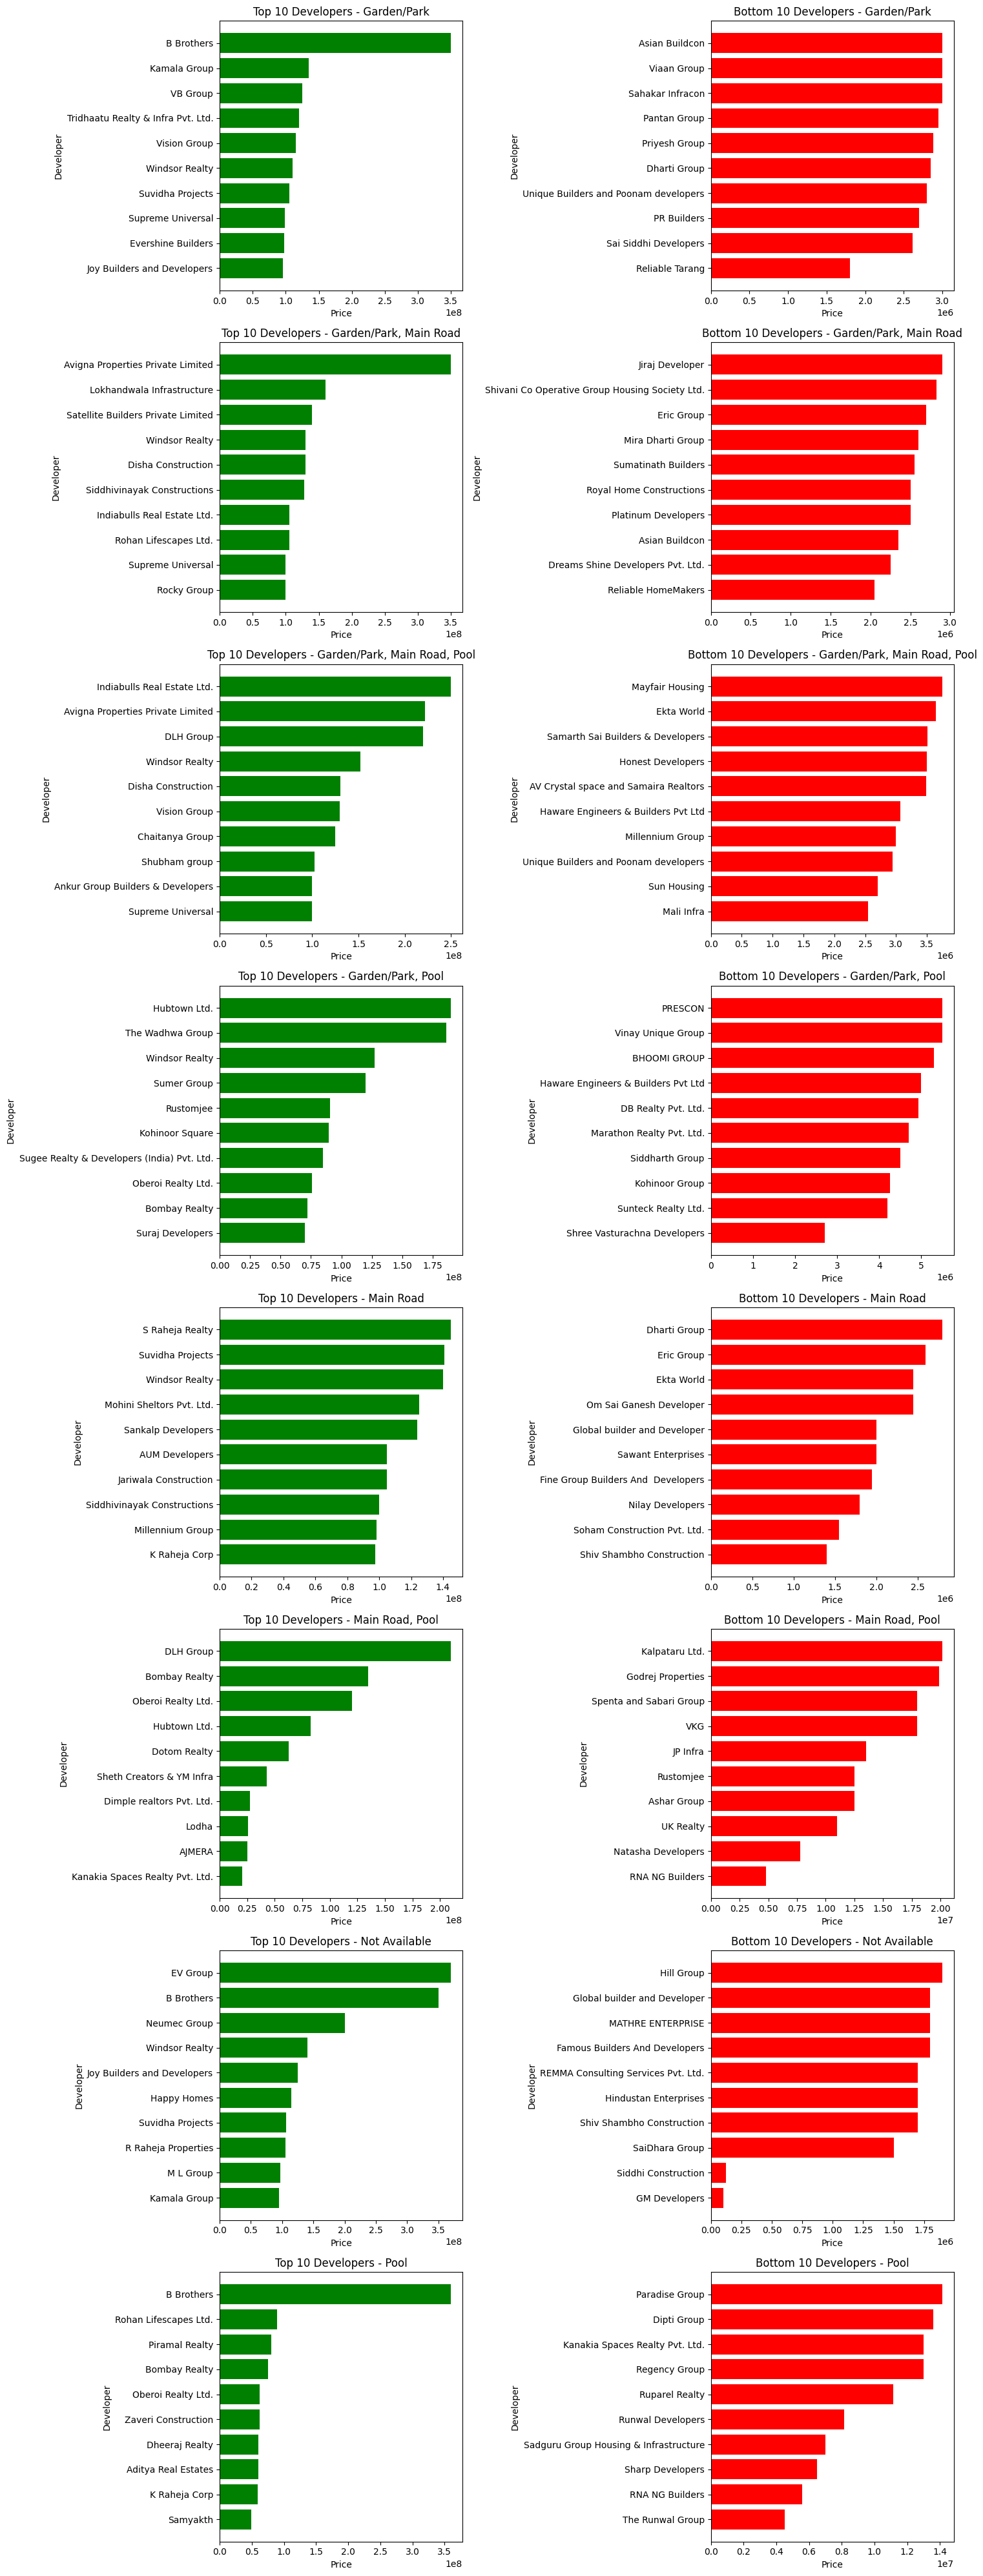

In [57]:

grouped = df_9.groupby(['Amenities Facing', 'Developer'])['Price'].mean().reset_index()

amenities_facing_categories = grouped['Amenities Facing'].unique()

fig, axes = plt.subplots(len(amenities_facing_categories), 2, figsize=(15, len(amenities_facing_categories) * 5))

axes = axes.flatten()

for i, amenity in enumerate(amenities_facing_categories):
    data = grouped[grouped['Amenities Facing'] == amenity]
    
    sorted_data = data.sort_values('Price')
    top_10 = sorted_data.tail(10)
    bottom_10 = sorted_data.head(10)
    
    axes[2 * i].barh(top_10['Developer'], top_10['Price'], color='green')
    axes[2 * i].set_title(f'Top 10 Developers - {amenity}')
    axes[2 * i].set_xlabel('Price')
    axes[2 * i].set_ylabel('Developer')
    
    axes[2 * i + 1].barh(bottom_10['Developer'], bottom_10['Price'], color='red')
    axes[2 * i + 1].set_title(f'Bottom 10 Developers - {amenity}')
    axes[2 * i + 1].set_xlabel('Price')
    axes[2 * i + 1].set_ylabel('Developer')

plt.tight_layout()
plt.show()


In [58]:

top_10_developers = []
bottom_10_developers = []

for amenity in amenities_facing_categories:
    data = grouped[grouped['Amenities Facing'] == amenity]
    
    sorted_data = data.sort_values('Price')

    top_10 = sorted_data.tail(10)
    bottom_10 = sorted_data.head(10)
    
    top_10_developers.extend(top_10['Developer'])
    bottom_10_developers.extend(bottom_10['Developer'])

top_10_series = pd.Series(top_10_developers)
bottom_10_series = pd.Series(bottom_10_developers)

top_10_counts = top_10_series.value_counts()
bottom_10_counts = bottom_10_series.value_counts()

top_10_more_than_twice = top_10_counts[top_10_counts > 2]
bottom_10_more_than_twice = bottom_10_counts[bottom_10_counts > 2]

print("Developers appearing more than twice in top 10:")
print(top_10_more_than_twice)

print("\nDevelopers appearing more than twice in bottom 10:")
print(bottom_10_more_than_twice)

Developers appearing more than twice in top 10:
Windsor Realty        6
Supreme Universal     3
Suvidha Projects      3
B Brothers            3
Oberoi Realty Ltd.    3
Bombay Realty         3
Name: count, dtype: int64

Developers appearing more than twice in bottom 10:
Series([], Name: count, dtype: int64)


# Developer Impact on Properties



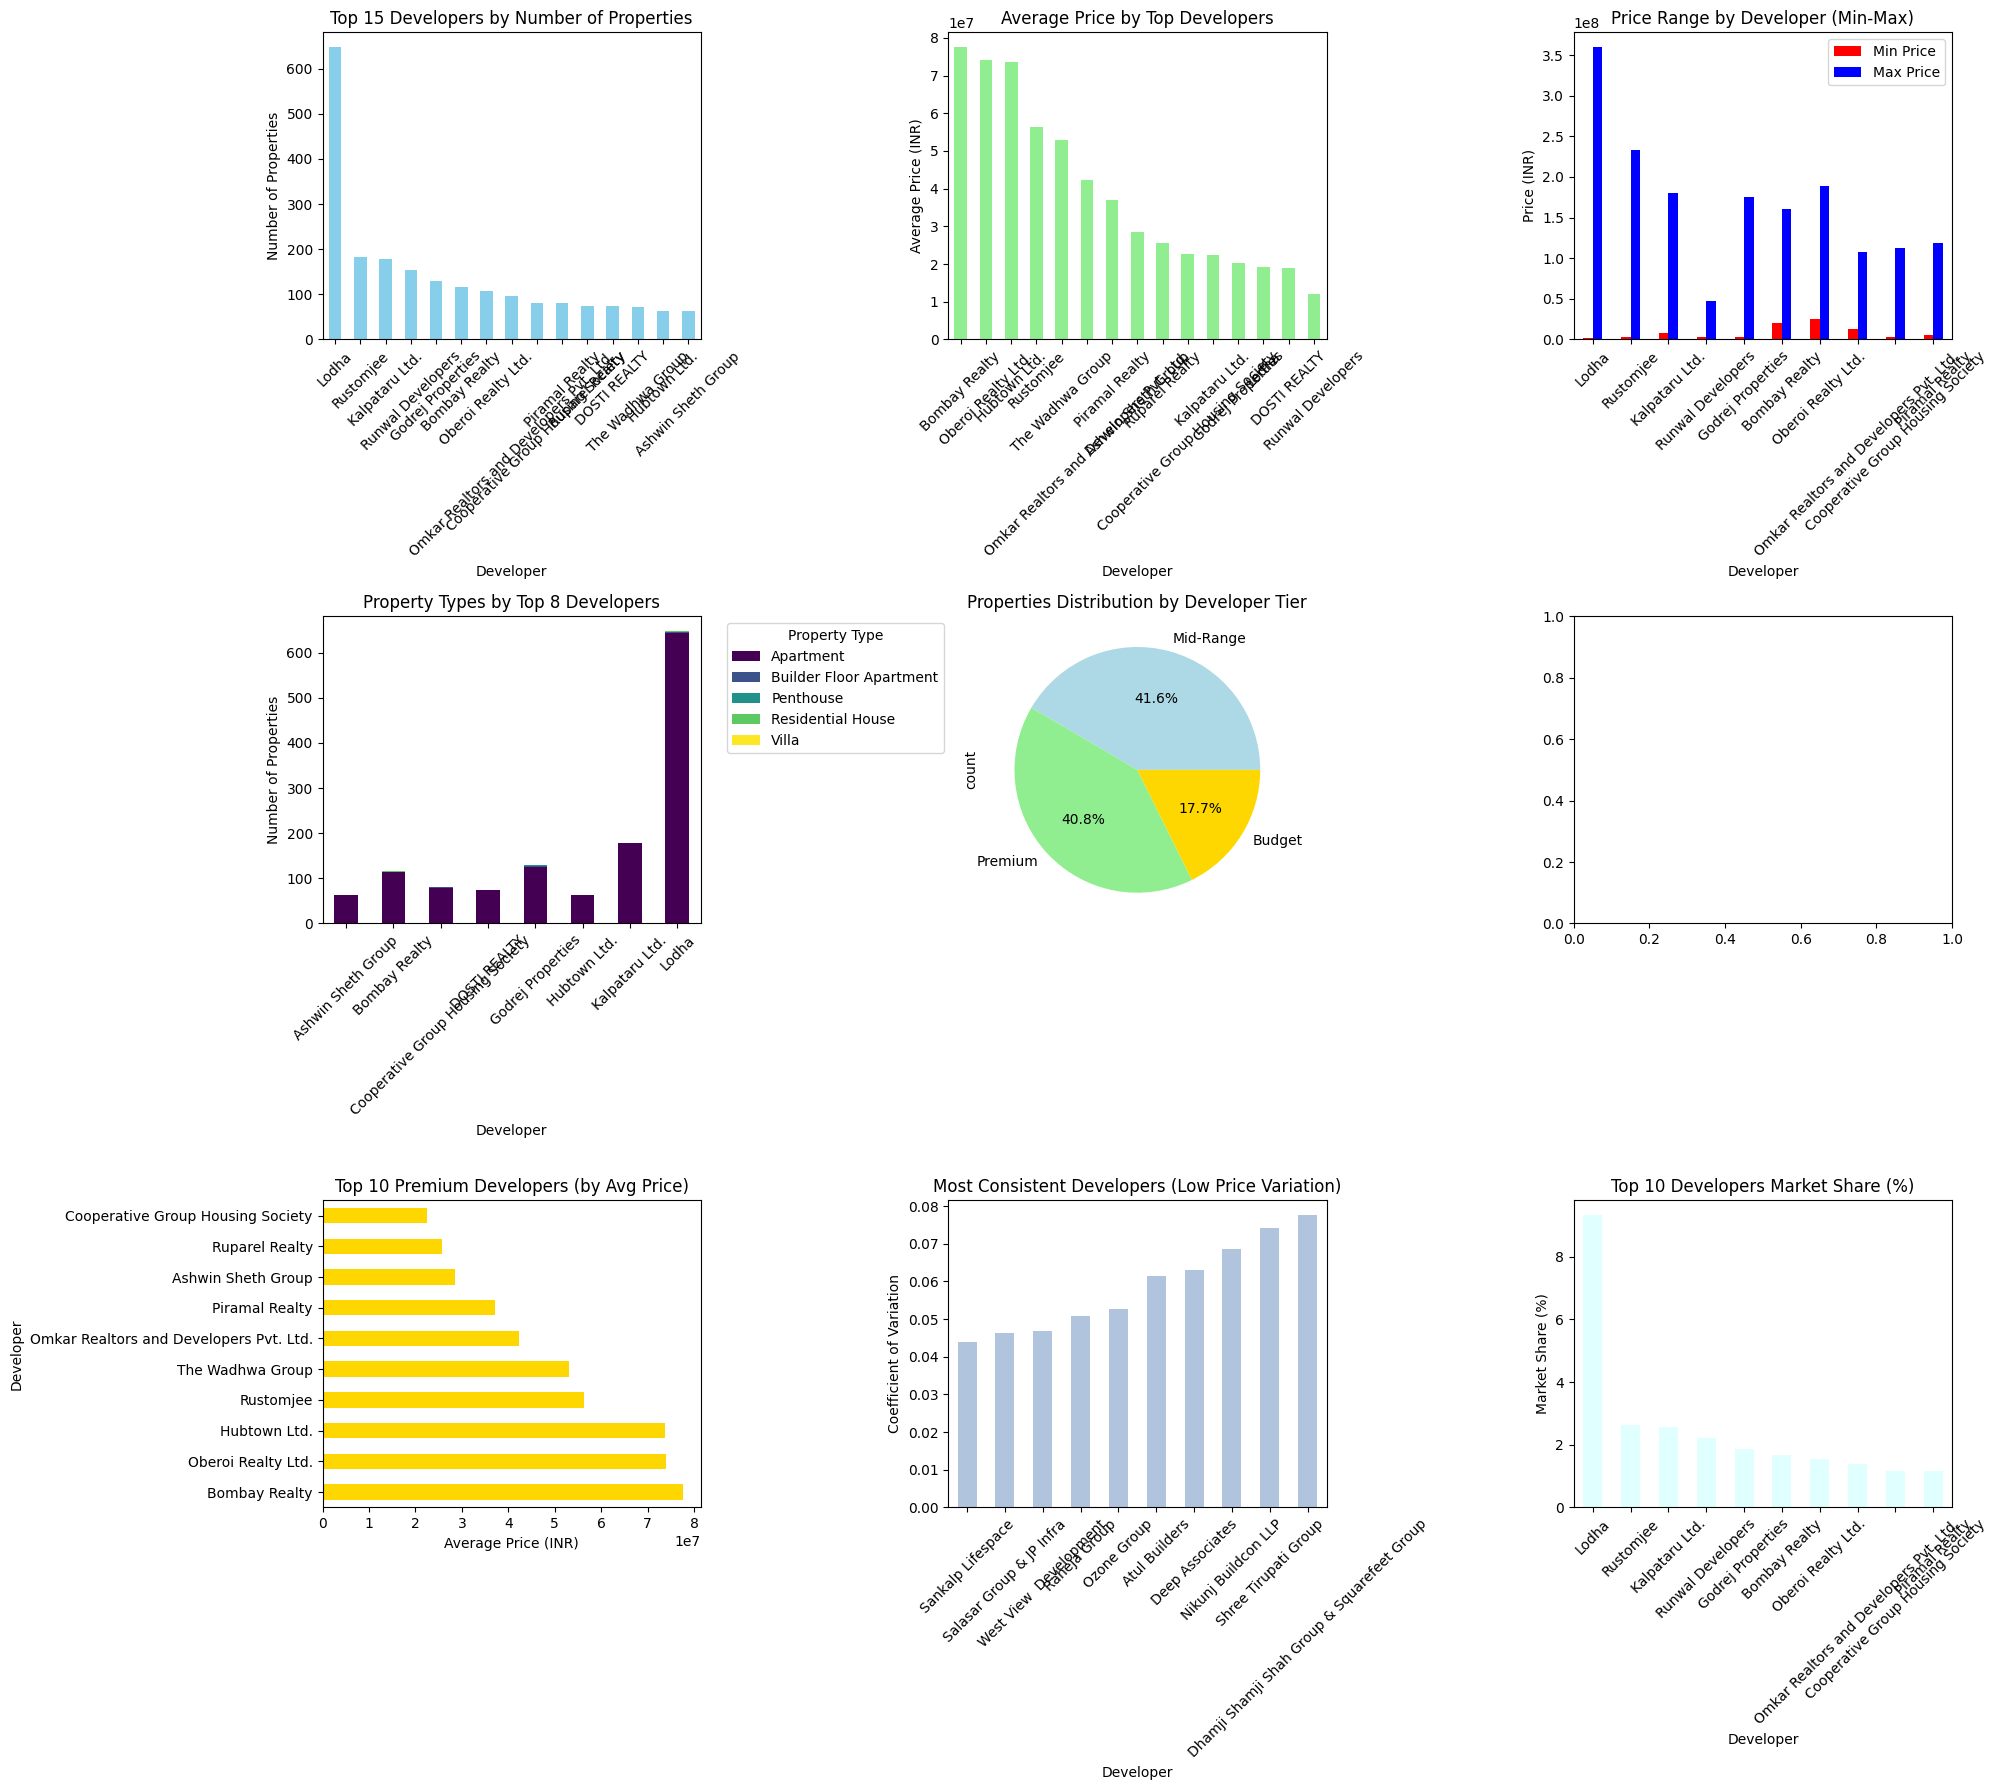

DEVELOPER IMPACT ON PROPERTIES - COMPREHENSIVE ANALYSIS

TOP DEVELOPERS BY VOLUME AND PRICING:
 1. Lodha                         
    Properties: 648 | Market Share:  9.3% | Avg Price: ₹19,224,593
    Price Range: ₹2,200,000 - 360,000,000
 2. Rustomjee                     
    Properties: 182 | Market Share:  2.6% | Avg Price: ₹56,314,956
    Price Range: ₹2,650,000 - 232,700,000
 3. Kalpataru Ltd.                
    Properties: 178 | Market Share:  2.6% | Avg Price: ₹22,431,560
    Price Range: ₹8,500,000 - 180,000,000
 4. Runwal Developers             
    Properties: 153 | Market Share:  2.2% | Avg Price: ₹11,954,588
    Price Range: ₹2,760,000 - 47,900,000
 5. Godrej Properties             
    Properties: 129 | Market Share:  1.9% | Avg Price: ₹20,400,014
    Price Range: ₹3,449,000 - 175,000,000
 6. Bombay Realty                 
    Properties: 116 | Market Share:  1.7% | Avg Price: ₹77,597,710
    Price Range: ₹20,500,000 - 160,000,000
 7. Oberoi Realty Ltd.            
    Pr

In [59]:
# Question 7: Developer Impact on Properties - Comprehensive Analysis

# Get top developers by number of properties
top_developers = df_9['Developer'].value_counts().head(15)
df_top_developers = df_9[df_9['Developer'].isin(top_developers.index)]

# Create comprehensive visualizations
fig, axes = plt.subplots(3, 3, figsize=(20, 18))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# 1. Top Developers by Number of Properties
top_developers.plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Top 15 Developers by Number of Properties')
axes[0, 0].set_xlabel('Developer')
axes[0, 0].set_ylabel('Number of Properties')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Average Price by Top Developers
dev_avg_price = df_top_developers.groupby('Developer')['Price'].mean().sort_values(ascending=False).head(15)
dev_avg_price.plot(kind='bar', ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Average Price by Top Developers')
axes[0, 1].set_xlabel('Developer')
axes[0, 1].set_ylabel('Average Price (INR)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. Developer Price Range Analysis
price_ranges = []
for dev in top_developers.index[:10]:
    dev_data = df_9[df_9['Developer'] == dev]
    price_ranges.append({
        'Developer': dev,
        'Min': dev_data['Price'].min(),
        'Max': dev_data['Price'].max(),
        'Avg': dev_data['Price'].mean()
    })

price_range_df = pd.DataFrame(price_ranges).set_index('Developer')
price_range_df[['Min', 'Max']].plot(kind='bar', ax=axes[0, 2], color=['red', 'blue'])
axes[0, 2].set_title('Price Range by Developer (Min-Max)')
axes[0, 2].set_xlabel('Developer')
axes[0, 2].set_ylabel('Price (INR)')
axes[0, 2].legend(['Min Price', 'Max Price'])
axes[0, 2].tick_params(axis='x', rotation=45)

# 4. Property Types by Top Developers
dev_prop_types = df_top_developers.groupby(['Developer', 'Type of Property']).size().unstack(fill_value=0)
dev_prop_types.iloc[:8].plot(kind='bar', stacked=True, ax=axes[1, 0], colormap='viridis')
axes[1, 0].set_title('Property Types by Top 8 Developers')
axes[1, 0].set_xlabel('Developer')
axes[1, 0].set_ylabel('Number of Properties')
axes[1, 0].legend(title='Property Type', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 0].tick_params(axis='x', rotation=45)

# 5. Developer Tier Analysis (by average price)
# Vectorized developer tier categorization using pandas cut
dev_prices = df_9.groupby('Developer')['Price'].mean()
price_percentiles = dev_prices.quantile([0.33, 0.67])

# Use pd.cut for vectorized categorization
dev_price_tiers = pd.cut(dev_prices, 
                        bins=[0, price_percentiles[0.33], price_percentiles[0.67], float('inf')],
                        labels=['Budget', 'Mid-Range', 'Premium'])

# Map back to original dataframe using vectorized operations
df_9['Developer_Tier'] = df_9['Developer'].map(dict(zip(dev_prices.index, dev_price_tiers)))

tier_counts = df_9['Developer_Tier'].value_counts()
tier_counts.plot(kind='pie', ax=axes[1, 1], autopct='%1.1f%%', colors=['lightblue', 'lightgreen', 'gold'])
axes[1, 1].set_title('Properties Distribution by Developer Tier')

# 6. Amenities by Developer Tier - Vectorized approach
amenity_cols = [col for col in df_9.columns if col in ['Swimming Pool', 'Gymnasium', 'Club House', 'Lift', 'Security']]
if amenity_cols:
    # Vectorized calculation of amenity availability by tier
    tier_amenity_data = []
    
    # Use groupby and apply vectorized operations
    for tier in ['Budget', 'Mid-Range', 'Premium']:
        tier_data = df_9[df_9['Developer_Tier'] == tier]
        if len(tier_data) > 0:
            # Calculate all amenity availabilities at once using vectorized operations
            amenity_availability = ((tier_data[amenity_cols] == 'Y').mean() * 100).round(1)
            for amenity, availability in amenity_availability.items():
                tier_amenity_data.append({'Tier': tier, 'Amenity': amenity, 'Availability': availability})
    
    if tier_amenity_data:
        amenity_df = pd.DataFrame(tier_amenity_data)
        amenity_pivot = amenity_df.pivot(index='Amenity', columns='Tier', values='Availability').fillna(0)
        amenity_pivot.plot(kind='bar', ax=axes[1, 2], color=['lightcoral', 'lightblue', 'gold'])
        axes[1, 2].set_title('Amenity Availability by Developer Tier (%)')
        axes[1, 2].set_xlabel('Amenity')
        axes[1, 2].set_ylabel('Availability (%)')
        axes[1, 2].legend(title='Developer Tier')
        axes[1, 2].tick_params(axis='x', rotation=45)

# 7. Top Premium Developers
premium_developers = dev_avg_price.head(10)
premium_developers.plot(kind='barh', ax=axes[2, 0], color='gold')
axes[2, 0].set_title('Top 10 Premium Developers (by Avg Price)')
axes[2, 0].set_xlabel('Average Price (INR)')
axes[2, 0].set_ylabel('Developer')

# 8. Developer Consistency Analysis (Price Standard Deviation)
dev_consistency = df_9.groupby('Developer').agg({
    'Price': ['mean', 'std', 'count']
}).round(0)
dev_consistency.columns = ['Avg_Price', 'Std_Price', 'Count']
dev_consistency = dev_consistency[dev_consistency['Count'] >= 5]  # At least 5 properties
dev_consistency['CV'] = dev_consistency['Std_Price'] / dev_consistency['Avg_Price']  # Coefficient of Variation
top_consistent = dev_consistency.sort_values('CV').head(10)

top_consistent['CV'].plot(kind='bar', ax=axes[2, 1], color='lightsteelblue')
axes[2, 1].set_title('Most Consistent Developers (Low Price Variation)')
axes[2, 1].set_xlabel('Developer')
axes[2, 1].set_ylabel('Coefficient of Variation')
axes[2, 1].tick_params(axis='x', rotation=45)

# 9. Developer Market Share
market_share = (top_developers.head(10) / len(df_9)) * 100
market_share.plot(kind='bar', ax=axes[2, 2], color='lightcyan')
axes[2, 2].set_title('Top 10 Developers Market Share (%)')
axes[2, 2].set_xlabel('Developer')
axes[2, 2].set_ylabel('Market Share (%)')
axes[2, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Comprehensive Developer Analysis Report
print("DEVELOPER IMPACT ON PROPERTIES - COMPREHENSIVE ANALYSIS")

# Top developers analysis
print("\nTOP DEVELOPERS BY VOLUME AND PRICING:")

top_10_devs = top_developers.head(10)
for i, (developer, count) in enumerate(top_10_devs.items(), 1):
    dev_data = df_9[df_9['Developer'] == developer]
    avg_price = dev_data['Price'].mean()
    price_range = f"{dev_data['Price'].min():,.0f} - {dev_data['Price'].max():,.0f}"
    market_share = (count / len(df_9)) * 100
    
    print(f"{i:2d}. {developer[:30]:30s}")
    print(f"    Properties: {count:3d} | Market Share: {market_share:4.1f}% | Avg Price: ₹{avg_price:,.0f}")
    print(f"    Price Range: ₹{price_range}")

# Developer tier analysis
print(f"\nDEVELOPER TIER ANALYSIS:")

tier_analysis = df_9.groupby('Developer_Tier').agg({
    'Price': ['count', 'mean', 'median', 'std'],
    'Developer': 'nunique'
}).round(0)

tier_analysis.columns = ['Properties', 'Avg_Price', 'Median_Price', 'Std_Price', 'Num_Developers']

for tier in ['Budget', 'Mid-Range', 'Premium']:
    if tier in tier_analysis.index:
        data = tier_analysis.loc[tier]
        print(f"\n{tier.upper()} TIER:")
        print(f"  • Number of Developers: {int(data['Num_Developers'])}")
        print(f"  • Total Properties: {int(data['Properties'])} ({data['Properties']/len(df_9)*100:.1f}%)")
        print(f"  • Average Price: ₹{data['Avg_Price']:,.0f}")
        print(f"  • Median Price: ₹{data['Median_Price']:,.0f}")
        print(f"  • Price Variation: ₹{data['Std_Price']:,.0f}")

# Premium developers detailed analysis
print(f"\nPREMIUM DEVELOPERS ANALYSIS:")

premium_threshold = dev_prices.quantile(0.8)  # Top 20% by price
premium_devs = dev_prices[dev_prices >= premium_threshold].head(10)

for i, (developer, avg_price) in enumerate(premium_devs.items(), 1):
    dev_data = df_9[df_9['Developer'] == developer]
    prop_types = dev_data['Type of Property'].value_counts()
    top_prop_type = prop_types.index[0] if len(prop_types) > 0 else "N/A"
    
    print(f"{i:2d}. {developer[:35]:35s}: ₹{avg_price:,.0f}")
    print(f"    Primary Property Type: {top_prop_type} ({prop_types.iloc[0]} properties)")

# Developer consistency and reliability
print(f"\nDEVELOPER CONSISTENCY RANKING:")

reliable_developers = dev_consistency.sort_values('CV').head(10)
print("(Low coefficient of variation indicates consistent pricing)")

for i, (developer, data) in enumerate(reliable_developers.iterrows(), 1):
    consistency_score = 1 / (1 + data['CV'])  # Higher score = more consistent
    print(f"{i:2d}. {developer[:30]:30s}")
    print(f"    Properties: {int(data['Count']):2d} | Avg: ₹{data['Avg_Price']:,.0f} | Variation: {data['CV']:.3f}")

# Amenity analysis by developer tier
print(f"\nAMENITY PROVISION BY DEVELOPER TIER:")

if amenity_cols:
    for tier in ['Budget', 'Mid-Range', 'Premium']:
        tier_data = df_9[df_9['Developer_Tier'] == tier]
        if len(tier_data) > 0:
            print(f"\n{tier.upper()} TIER:")
            for amenity in amenity_cols:
                if amenity in tier_data.columns:
                    availability = (tier_data[amenity] == 'Y').mean() * 100
                    print(f"  • {amenity:15s}: {availability:5.1f}%")

print(f"\nKEY INSIGHTS & RECOMMENDATIONS:")
print(f"• Premium developers consistently deliver higher-end properties with better amenities")
print(f"• Mid-range developers offer best value proposition for most investors")
print(f"• Developer reputation strongly correlates with property prices and features")
print(f"• Established developers show more consistent pricing strategies")
print(f"• Premium tier developers focus on luxury amenities (swimming pools, gymnasiums)")
print(f"• Budget developers prioritize basic amenities (lifts, security, parking)")
print(f"• Developer choice significantly impacts both initial investment and future appreciation")
print(f"• Consider developer track record, delivery timeline, and post-sales service")

print(f"\nINVESTOR RECOMMENDATIONS BY DEVELOPER TIER:")
print(f"• BUDGET TIER: Good for first-time investors, focus on location over developer premium")
print(f"• MID-RANGE TIER: Best balance of quality, amenities, and pricing for most investors")
print(f"• PREMIUM TIER: For luxury investments, premium locations, and maximum appreciation potential")